# Structure and Unusual Behaviour in Smartphone Movement Data
**DSA8003 Data Mining — Group 4**

**Overarching question.** *What meaningful structure and unusual behaviour are present in the UCI HAR smartphone sensor data, and how confident can we be in their interpretation?*


## 1. Introduction

### 1.1 Dataset and Unit of Analysis
The UCI Human Activity Recognition dataset (Anguita et al., 2013) contains recordings from 30 volunteers aged 19–48. Each carried a smartphone on the waist while walking, walking upstairs, walking downstairs, sitting, standing and lying down.

The accelerometer and gyroscope were sampled at 50 Hz. The signals were divided into windows of 2.56 seconds (128 samples) with 50% overlap, and each window is summarised by 561 engineered features. The dataset authors divided the participants into 21 for training and 9 for testing.

The unit of analysis is the **window**. Windows are not independent:
* consecutive windows share half of their samples;
* windows belong to continuous **recording episodes**, in which one participant performs one activity without interruption;
* episodes belong to **participants**.

This nesting of windows within episodes within participants is retained throughout. It determines how uncertainty is estimated, and it is the basis of RQ3.

### 1.2 Criteria for Meaningful Clusters
A cluster is treated as meaningful only if it satisfies four criteria:
1. it is supported by internal evidence of separation;
2. it is reproduced when the participants used to fit it are changed;
3. it can be explained by physically interpretable sensor characteristics;
4. it is not driven by a single individual.

### 1.3 Operational Definition of Anomalies
The data were recorded from healthy volunteers following a scripted protocol, and no abnormal events are annotated. An anomaly is therefore defined as **a window that is rare relative to a stated reference population**. Three references are used:
* the whole dataset (a **global** reference);
* the window's own cluster or neighbourhood (a **local** reference);
* the same participant's comparable windows (an **individual** reference).

The aim is to investigate *patterns associated with* flagged windows and assess plausible explanations. The following possibilities are hypotheses, not confirmed causes; the dataset contains no labelled anomalies or verified mechanisms:

| Possible explanation | Observable indication / test | Anomaly type |
|---|---|---|
| 1. Movement near episode boundaries | A flagged window occurs near an episode boundary and has high within-window movement or estimated orientation change; an actual transition is not observed | Point / temporal episode |
| 2. Movement within a static posture | Shifting or fidgeting while sitting, standing or lying | Point / group |
| 3. Participant-associated difference | High scores recur for the same participant across distinct episodes; gait is only one possible cause | Contextual / group |
| 4. Device orientation / placement | Differences in estimated gravity direction between recordings or participants; precise attachment position is not measured | Contextual |
| 5. Possible label imprecision | A movement-rich window occurs near an episode boundary despite a static activity label; no independently verified label error is available | Point |
| 6. Possible sensor or data-quality fault | Check for obvious corruption, missingness and value-range violations; subtler errors cannot be ruled out | Point |

### 1.4 Scope and Ethical Considerations
* **Population.** The participants are healthy adults aged 19–48, so the findings do not extend to children, older adults or clinical populations.
* **Measurements.** The features are the dataset authors' engineered summaries, normalised to [−1, 1]; they are not calibrated physical units.
* **Identifiability.** Gait can identify an individual. Participants are referred to only by the anonymous identifiers supplied with the dataset.
* **Consent.** Participants consented to the original data collection (Anguita et al., 2013). This secondary analysis uses the public release for its stated research purpose.
* **Held-out participants.** All models and thresholds are estimated from the 21 training participants. The nine test participants are used only in Section 13.

## 2. Data Acquisition and Episode Reconstruction

### 2.1 Configuration
The libraries and fixed analysis parameters are defined first. A single random seed is used for every stochastic step.

In [1]:
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import skew, kurtosis, gaussian_kde, spearmanr, pearsonr
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, adjusted_mutual_info_score)
warnings.filterwarnings("ignore", category=FutureWarning)
try:
    import umap
    HAS_UMAP = True
except ImportError:          # UMAP is optional
    HAS_UMAP = False

SEED = 42            # random seed for every stochastic step
K_NN = 15            # neighbourhood size for the k-nearest-neighbour anomaly score
TOP = 0.05           # shortlist: the top 5% of anomaly scores
SHORTLISTS = (0.025, 0.05, 0.10)
VAR_RETAIN = 0.70    # within-family variance retained by block-wise PCA (Jolliffe, 2002)
N_BOOT = 1000        # participant-level bootstrap replicates
N_NULL = 200         # permutation replicates

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9.5, "axes.titlesize": 10,
                     "axes.titlelocation": "left", "legend.frameon": False})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
C_LOW, C_HIGH, C_GLOBAL, C_LOCAL, C_GREY = "#4C78A8", "#E45756", "#1F4E79", "#C55A11", "#9A9A9A"
ACT_ORDER = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
ACT_SHORT = dict(zip(ACT_ORDER, ["Walk", "Upstairs", "Downstairs", "Sit", "Stand", "Lie"]))
_FIG = [0]

def fig_title(target, text):
    """Number figures consecutively; `target` is an Axes or a Figure."""
    _FIG[0] += 1
    if isinstance(target, plt.Figure):
        target.suptitle(f"Figure {_FIG[0]}. {text}", x=0.01, ha="left", fontsize=10.5)
    else:
        target.set_title(f"Figure {_FIG[0]}. {text}")

from matplotlib.colors import TwoSlopeNorm

def heatmap(df, title, fmt="{:.0f}", cmap="Blues", vmin=None, vmax=None, xlabel="", ylabel="", cbar_label="",
            ratio=False, figsize=None):
    """Annotated heatmap. With ratio=True, colours are on a log scale centred on 1 (white = proportional)."""
    vals = df.values.astype(float)
    fig, ax = plt.subplots(figsize=figsize or (1.6 + 1.05 * df.shape[1], 1.0 + 0.45 * df.shape[0]))
    if ratio:
        lv = np.log10(np.clip(vals, 0.01, None))
        im = ax.imshow(lv, cmap="RdBu_r", aspect="auto", norm=TwoSlopeNorm(vmin=-2, vcenter=0, vmax=1.5))
        shade = np.abs(lv) / 1.5
    else:
        im = ax.imshow(vals, cmap=cmap, aspect="auto", vmin=vmin, vmax=vmax)
        lo = np.nanmin(vals) if vmin is None else vmin; hi_ = np.nanmax(vals) if vmax is None else vmax
        shade = (vals - lo) / max(hi_ - lo, 1e-9)
    long = max(max(len(p) for p in str(c).split("\n")) for c in df.columns) > 12 and not any("\n" in str(c) for c in df.columns)
    ax.set_xticks(range(df.shape[1]), df.columns, rotation=30 if long else 0, ha="right" if long else "center")
    ax.set_yticks(range(df.shape[0]), df.index)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            ax.text(j, i, fmt.format(vals[i, j]), ha="center", va="center", fontsize=8.5,
                    color="white" if shade[i, j] > 0.6 else "black")
    ax.grid(False); ax.set(xlabel=xlabel, ylabel=ylabel)
    cb = fig.colorbar(im, ax=ax, shrink=0.85)
    if ratio:
        cb.set_ticks([-2, -1, 0, 1]); cb.set_ticklabels(["0.01", "0.1", "1", "10"])
    cb.set_label(cbar_label)
    fig_title(ax, title)
    plt.tight_layout(); plt.show()

def map_plot(ax, values=None, colours=None, highlight=None, title="", s=2):
    """Scatter on the t-SNE layout of Section 6.6. `values` are category labels; `highlight` is a boolean mask."""
    xy = TSNE_XY
    if highlight is not None:
        ax.scatter(xy[~highlight, 0], xy[~highlight, 1], s=s, color="#D9D9D9", rasterized=True, label="Other windows")
        ax.scatter(xy[highlight, 0], xy[highlight, 1], s=s + 4, color=C_HIGH, rasterized=True, label="Flagged" if not title else title)
    else:
        for v in colours:
            m = values == v
            ax.scatter(xy[m, 0], xy[m, 1], s=s, color=colours[v], rasterized=True, label=v)
    ax.set(xticks=[], yticks=[]); ax.grid(False)
    ax.legend(markerscale=4, fontsize=8, loc="best")

def find_data_dir():
    for c in [os.environ.get("HAR_DATA_DIR"), "UCI HAR Dataset", "../UCI HAR Dataset", "data/UCI HAR Dataset"]:
        if c and (Path(c) / "features.txt").exists():
            return Path(c)
    raise FileNotFoundError("Place the 'UCI HAR Dataset' folder next to this notebook or set HAR_DATA_DIR.")
DATA = find_data_dir()
T0 = time.time()

### 2.2 Loading the Training Data
The feature matrix, participant identifiers, recorded activities and raw inertial signals are read for the training participants. In the supplied feature list, 42 `bandsEnergy` names occur three times, once per axis, so the axis is restored to make every name unique.

In [2]:
def read_txt(rel, names=None):
    return pd.read_csv(DATA / rel, sep=r"\s+", header=None, names=names)

def feature_names():
    raw = read_txt("features.txt")[1].tolist()
    counts, seen, names = pd.Series(raw).value_counts(), {}, []
    for n in raw:
        if counts[n] > 1:
            k = seen.get(n, 0); seen[n] = k + 1; names.append(f"{n}-{'XYZ'[k]}")
        else:
            names.append(n)
    return names

def load_split(split):
    X = read_txt(f"{split}/X_{split}.txt", names=feature_names())
    subj = read_txt(f"{split}/subject_{split}.txt")[0].to_numpy()
    labels = read_txt("activity_labels.txt").set_index(0)[1]
    act = labels.loc[read_txt(f"{split}/y_{split}.txt")[0]].to_numpy()
    sig = {f"{s}_{a}": read_txt(f"{split}/Inertial Signals/{s}_{a}_{split}.txt").to_numpy()
           for s in ["body_acc", "body_gyro", "total_acc"] for a in "xyz"}
    return X, subj, act, sig

X_raw, subj, act, SIG = load_split("train")
print(f"Training data: {len(X_raw):,} windows, {X_raw.shape[1]} features, {len(np.unique(subj))} participants")

Training data: 7,352 windows, 561 features, 21 participants


### 2.3 Reconstruction of Recording Episodes
The dataset does not record where one episode ends and the next begins. Episodes are reconstructed from two properties of the raw signals:
* consecutive windows of the same episode share 64 samples, because windows overlap by half;
* the participant identifier does not change within an episode.

A new episode therefore begins wherever the participant changes or the overlap is broken. Each window's position in its episode is recorded, distinguishing its first two windows (the **start**), its last two (the **end**) and the remainder (the **interior**).

In [3]:
def reconstruct_episodes(subj, sig):
    overlap = np.r_[False, np.isclose(sig["body_acc_x"][:-1, 64:], sig["body_acc_x"][1:, :64], atol=1e-6).all(axis=1)]
    same_person = np.r_[False, subj[1:] == subj[:-1]]
    W = pd.DataFrame({"subject": subj, "episode": np.cumsum(~(same_person & overlap)) - 1})
    W["pos"] = W.groupby("episode").cumcount()
    W["ep_len"] = W.groupby("episode")["episode"].transform("size")
    W["position"] = np.where(W.pos < 2, "start", np.where(W.pos >= W.ep_len - 2, "end", "interior"))
    return W

W = reconstruct_episodes(subj, SIG)
print(f"Recording episodes: {W.episode.nunique()}; median length {int(W.groupby('episode').size().median())} windows; "
      f"longest {W.ep_len.max()} windows")
print("Activities per episode:", pd.Series(act).groupby(W.episode).nunique().value_counts().to_dict())

Recording episodes: 600; median length 12 windows; longest 29 windows
Activities per episode: {1: 600}


**The training data form 600 recording episodes.** The median episode lasts 12 windows (about 15 seconds), and the longest 29. Every reconstructed episode contains a single recorded activity, consistent with the overlap-based reconstruction; this is a check on the reconstructed boundaries, not independent proof that all temporal transitions are identified.

### 2.4 Raw-Signal Descriptors
Five descriptors are computed from each 2.56-second raw-signal window to aid physical interpretation:
* **intensity:** root-mean-square body-acceleration magnitude (g);
* **rotation:** root-mean-square angular-velocity magnitude (rad/s);
* **dominant frequency:** strongest frequency in body acceleration (Hz), used as an approximate rhythmic-motion descriptor rather than a validated step cadence;
* **energy change:** absolute log ratio of body-acceleration energy between the second and first halves of the window;
* **estimated gravity-direction change:** the angle (°) between the mean estimated gravity vectors in the first and final 32 samples. Gravity is estimated as *total acceleration minus body acceleration*, using the dataset's separated inertial channels.

Mean estimated gravity direction is also retained as a **proxy** for device orientation. These measurements are not independent ground-truth records of posture, device placement or transitions; filtering error and residual motion may affect them.

In [4]:
def raw_descriptors(sig):
    acc = np.sqrt(sig["body_acc_x"]**2 + sig["body_acc_y"]**2 + sig["body_acc_z"]**2)
    gyr = np.sqrt(sig["body_gyro_x"]**2 + sig["body_gyro_y"]**2 + sig["body_gyro_z"]**2)
    spec = np.abs(np.fft.rfft(acc - acc.mean(1, keepdims=True), axis=1))[:, 1:]
    # Gravity estimate: total acceleration = body acceleration + gravity (approximately).
    # Total-acceleration direction alone cannot be used to infer phone orientation during motion.
    grav = np.stack([sig[f"total_acc_{a}"] - sig[f"body_acc_{a}"] for a in "xyz"], axis=2)
    g0, g1 = grav[:, :32].mean(1), grav[:, -32:].mean(1)
    denominator = np.maximum(np.linalg.norm(g0, axis=1) * np.linalg.norm(g1, axis=1), 1e-12)
    cos = (g0 * g1).sum(1) / denominator
    d = pd.DataFrame({
        "acc_rms": np.sqrt((acc**2).mean(1)),
        "gyro_rms": np.sqrt((gyr**2).mean(1)),
        "dom_freq": np.fft.rfftfreq(128, 1 / 50)[1:][spec.argmax(1)],
        "energy_change": np.abs(np.log(((acc[:, 64:]**2).mean(1) + 1e-6) / ((acc[:, :64]**2).mean(1) + 1e-6))),
        "tilt_change": np.degrees(np.arccos(np.clip(cos, -1, 1)))})
    d[["grav_x", "grav_y", "grav_z"]] = grav.mean(1)
    return d, acc

desc, ACC_MAG = raw_descriptors(SIG)
W = W.join(desc)
display(W[["acc_rms", "gyro_rms", "dom_freq", "energy_change", "tilt_change"]].describe().T[["mean", "50%", "min", "max"]].round(3))

,mean,50%,min,max
acc_rms,0.178,0.053,0.005,0.749
gyro_rms,0.431,0.191,0.005,2.102
dom_freq,1.800,1.562,0.391,11.719
energy_change,0.517,0.248,0.000,7.059
tilt_change,1.704,0.814,0.002,59.566


## 3. Data Quality Assessment

### 3.1 Completeness and Basic Integrity
The first check examines missingness, non-finite values, repeated windows and range violations. These checks detect readily observable data defects, but cannot verify the physical correctness of every sensor reading.

In [5]:
n_distinct = X_raw.nunique()
quality = pd.Series({
    "Missing values": int(X_raw.isna().sum().sum()),
    "Non-finite values": int((~np.isfinite(X_raw.to_numpy())).sum()),
    "Constant features": int((n_distinct <= 1).sum()),
    "Duplicated windows": int(X_raw.duplicated().sum()),
    "Minimum value": round(float(X_raw.values.min()), 3),
    "Maximum value": round(float(X_raw.values.max()), 3)}, name="Training data")
display(quality.to_frame())

,Training data
Missing values,0.0
Non-finite values,0.0
Constant features,0.0
Duplicated windows,0.0
Minimum value,-1.0
Maximum value,1.0


**No basic data-integrity problems were detected.** The training feature matrix contains no missing or non-finite values, constant features or duplicated windows; the stored feature values fall within the expected normalised range of −1 to 1. This establishes completeness and basic numerical consistency, **not** an absence of subtle sensor faults, filtering artefacts or annotation problems.

### 3.2 Duplicated Features
Some features may be exact copies of others. Copies add no information but double the weight of what they measure.

In [6]:
dup_col = X_raw.T.duplicated(keep="first").to_numpy()
col_hash = pd.util.hash_pandas_object(X_raw.T, index=False)       # one hash per feature column
first_of = {c: X_raw.columns[np.flatnonzero(col_hash.to_numpy() == col_hash.iloc[i])[0]]
            for i, c in enumerate(X_raw.columns) if dup_col[i]}
print(f"Columns identical to an earlier column: {dup_col.sum()}")
display(pd.DataFrame({"Duplicate": list(first_of), "Identical to": list(first_of.values())}).head(8).style.hide(axis="index"))
X_dedup = X_raw.loc[:, ~dup_col]
print(f"Features retained: {X_dedup.shape[1]}")

Columns identical to an earlier column: 21


Duplicate,Identical to
tBodyAccMag-sma(),tBodyAccMag-mean()
tGravityAccMag-mean(),tBodyAccMag-mean()
tGravityAccMag-std(),tBodyAccMag-std()
tGravityAccMag-mad(),tBodyAccMag-mad()
tGravityAccMag-max(),tBodyAccMag-max()
tGravityAccMag-min(),tBodyAccMag-min()
tGravityAccMag-sma(),tBodyAccMag-mean()
tGravityAccMag-energy(),tBodyAccMag-energy()


Features retained: 540


**Twenty-one features are exact copies of other features.** They arise in two ways:
* every `tGravityAccMag` feature duplicates the corresponding `tBodyAccMag` feature;
* for each magnitude signal, the `sma()` feature duplicates the `mean()` feature.

The copies are removed, leaving 540 features.

### 3.3 Discrete Features
Features with few distinct values are not continuous measurements and should be identified before distances are computed.

In [7]:
discrete = n_distinct[n_distinct <= 50]
print(f"Features with 50 or fewer distinct values: {len(discrete)}")
display(discrete.sort_values().to_frame("Distinct values").head(11))

Features with 50 or fewer distinct values: 11


,Distinct values
fBodyGyro-maxInds-Z,25
fBodyAcc-maxInds-Y,26
fBodyAcc-maxInds-Z,26
fBodyGyro-maxInds-X,27
fBodyBodyGyroMag-maxInds,27
fBodyAccMag-maxInds,29
fBodyGyro-maxInds-Y,29
fBodyAcc-maxInds-X,29
fBodyAccJerk-maxInds-X,48
fBodyAccJerk-maxInds-Y,48


**Eleven features are discrete.** All are `maxInds` features, which record the index of the dominant frequency bin and take between 25 and 49 values. They are retained as ordinal measurements.

These checks show no obvious numerical corruption, but they cannot rule out less visible sensor, signal-processing or annotation problems. Such explanations remain possible, although not directly testable with the available reference information.

## 4. Feature Representation
Distance-based clustering and anomaly detection are only as meaningful as the distances they use. This section examines the supplied features step by step, identifies two problems, and builds a representation that addresses them.

### 4.1 The Supplied Feature Set
Each feature summarises one physical signal. The features are grouped into ten **physical families**, defined by domain (time or frequency) and signal (body acceleration, rotation, their jerk, gravity, and angles to gravity).

In [8]:
FAMILY_LABEL = {"t:Acc": "Time · body acceleration", "t:AccJerk": "Time · body acceleration jerk",
                "t:Gyro": "Time · rotation", "t:GyroJerk": "Time · rotation jerk",
                "t:Gravity": "Time · gravity", "f:Acc": "Frequency · body acceleration",
                "f:AccJerk": "Frequency · body acceleration jerk", "f:Gyro": "Frequency · rotation",
                "f:GyroJerk": "Frequency · rotation jerk", "Angle": "Angle to gravity"}
FAMILIES = list(FAMILY_LABEL)

def feature_family(name):
    if name.startswith("angle("):
        return "Angle"
    stem, dom = name.split("-", 1)[0].replace("BodyBody", "Body"), ("t" if name[0] == "t" else "f")
    part = "Gravity" if "Gravity" in stem else ("Gyro" if "Gyro" in stem else "Acc") + ("Jerk" if "Jerk" in stem else "")
    return f"{dom}:{part}"

fam_raw = pd.Series({c: feature_family(c) for c in X_raw.columns})
fam_dedup = fam_raw[X_dedup.columns]
family_table = pd.DataFrame({"Family": [FAMILY_LABEL[f] for f in FAMILIES],
                             "Features supplied": [int((fam_raw == f).sum()) for f in FAMILIES],
                             "After removing duplicates": [int((fam_dedup == f).sum()) for f in FAMILIES],
                             "Example": [fam_dedup.index[fam_dedup == f][0] for f in FAMILIES]})
display(family_table.style.hide(axis="index"))

Family,Features supplied,After removing duplicates,Example
Time · body acceleration,53,52,tBodyAcc-mean()-X
Time · body acceleration jerk,53,52,tBodyAccJerk-mean()-X
Time · rotation,53,52,tBodyGyro-mean()-X
Time · rotation jerk,53,52,tBodyGyroJerk-mean()-X
Time · gravity,53,40,tGravityAcc-mean()-X
Frequency · body acceleration,92,91,fBodyAcc-mean()-X
Frequency · body acceleration jerk,92,91,fBodyAccJerk-mean()-X
Frequency · rotation,92,91,fBodyGyro-mean()-X
Frequency · rotation jerk,13,12,fBodyBodyGyroJerkMag-mean()
Angle to gravity,7,7,"angle(tBodyAccMean,gravity)"


**The families differ greatly in size.** Each time-domain family contains 52 or 53 features, and three of the frequency-domain families contain 91 each. By contrast, frequency-domain rotation jerk has 12 features and the angle family only 7. The families also overlap in content, since many features are different summaries of the same signal.

### 4.2 Redundancy Between Features
For each feature, the strongest absolute correlation with any other feature is computed. Values close to 1 indicate that a feature is almost a copy of another.

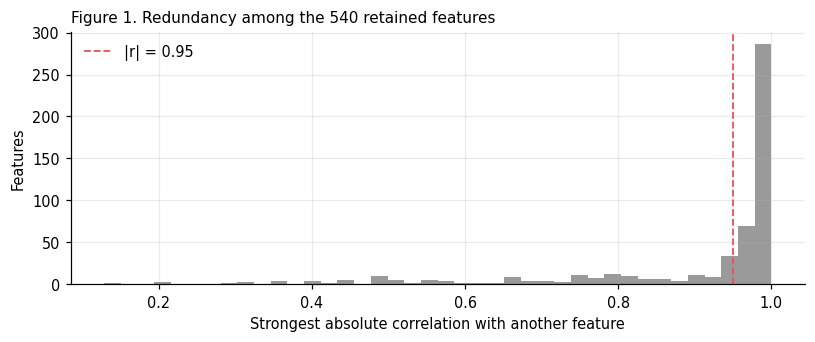

Features with a near-duplicate (|r| >= 0.95): 68%
Median strongest correlation: 0.98


In [9]:
corr = np.abs(np.corrcoef(X_dedup.to_numpy(), rowvar=False)); np.fill_diagonal(corr, 0)
max_r = corr.max(axis=1)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(max_r, bins=40, color=C_GREY)
ax.axvline(0.95, color=C_HIGH, ls="--", lw=1.2, label="|r| = 0.95")
ax.set(xlabel="Strongest absolute correlation with another feature", ylabel="Features"); ax.legend()
fig_title(ax, "Redundancy among the 540 retained features")
plt.tight_layout(); plt.show()
print(f"Features with a near-duplicate (|r| >= 0.95): {(max_r >= 0.95).mean():.0%}")
print(f"Median strongest correlation: {np.median(max_r):.2f}")

**The feature set is highly redundant.** Of the 540 retained features, 68% have a near-duplicate with an absolute correlation of at least 0.95, and the median feature's strongest correlation is 0.98. Distances computed on all features would therefore count the same information many times.

### 4.3 Differences in Feature Variance
In a Euclidean distance, each feature contributes in proportion to its variance. The variances of the supplied features are therefore compared.

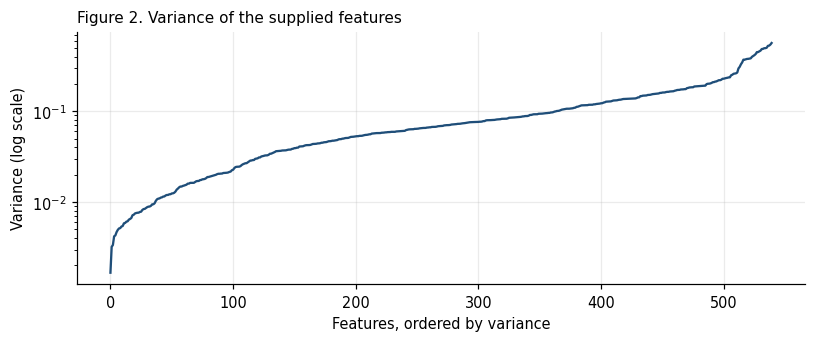

Largest variance / smallest variance: 339-fold
Lowest variance: tBodyAcc-mean()-Y (0.0017); highest: fBodyAccJerk-entropy()-X (0.565)


In [10]:
v = X_dedup.var().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(np.arange(len(v)), v.values, color=C_GLOBAL)
ax.set_yscale("log")
ax.set(xlabel="Features, ordered by variance", ylabel="Variance (log scale)")
fig_title(ax, "Variance of the supplied features")
plt.tight_layout(); plt.show()
print(f"Largest variance / smallest variance: {v.max() / v.min():.0f}-fold")
print(f"Lowest variance: {v.index[0]} ({v.iloc[0]:.4f}); highest: {v.index[-1]} ({v.iloc[-1]:.3f})")

**Feature variances span a 339-fold range.** The lowest-variance features are the means of body acceleration, which are close to zero by construction because gravity has been removed. The highest are entropy features, which differ strongly between still and moving windows. Without rescaling, a small number of high-variance features would dominate any distance.

### 4.4 Effect of Standardisation
Standardisation rescales every feature to unit variance, which removes the variance imbalance. Each family then contributes to distance in proportion to its number of features. The family shares of distance before and after standardisation are compared.

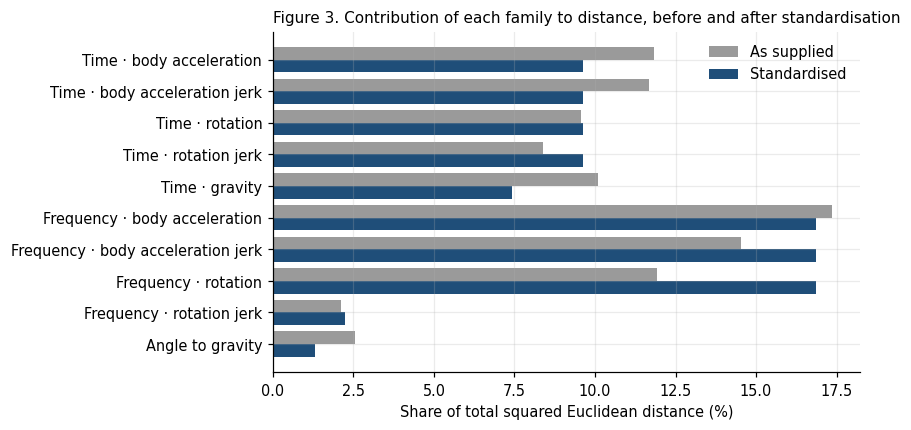

,As supplied,Standardised
Time · body acceleration,11.8,9.6
Time · body acceleration jerk,11.7,9.6
Time · rotation,9.6,9.6
Time · rotation jerk,8.4,9.6
Time · gravity,10.1,7.4
Frequency · body acceleration,17.3,16.9
Frequency · body acceleration jerk,14.5,16.9
Frequency · rotation,11.9,16.9
Frequency · rotation jerk,2.1,2.2
Angle to gravity,2.6,1.3


In [11]:
scaler = StandardScaler().fit(X_dedup)
S = pd.DataFrame(scaler.transform(X_dedup), columns=X_dedup.columns)
share_raw = X_dedup.var().groupby(fam_dedup).sum() / X_dedup.var().sum() * 100
share_std = fam_dedup.value_counts() / len(fam_dedup) * 100
shares = pd.DataFrame({"As supplied": share_raw, "Standardised": share_std}).reindex(FAMILIES)
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(FAMILIES))
ax.barh(y - 0.2, shares["As supplied"], 0.4, color=C_GREY, label="As supplied")
ax.barh(y + 0.2, shares["Standardised"], 0.4, color=C_GLOBAL, label="Standardised")
ax.set_yticks(y, [FAMILY_LABEL[f] for f in FAMILIES]); ax.invert_yaxis()
ax.set(xlabel="Share of total squared Euclidean distance (%)"); ax.legend()
fig_title(ax, "Contribution of each family to distance, before and after standardisation")
plt.tight_layout(); plt.show()
display(shares.rename(index=FAMILY_LABEL).round(1))

**Standardisation removes the variance imbalance but exposes an imbalance in family size.** After standardisation each family's share of distance equals its share of features:
* the three large frequency-domain families together account for half of all distance (16.9% each);
* the angle family accounts for 1.3%, and frequency-domain rotation jerk for 2.2%.

Orientation and rotation jerk therefore have almost no influence on distances, even though they describe different physical properties from the large families.

### 4.5 Principal Components Within Each Family
To remove redundancy without mixing physical meanings, a principal component analysis is fitted **separately within each family**. Components are retained until 70% of the family's variance is explained. This threshold is the lower end of the range conventionally recommended for cumulative-variance rules (70–90%; Jolliffe, 2002), and it keeps the dimension manageable for neighbourhood methods.

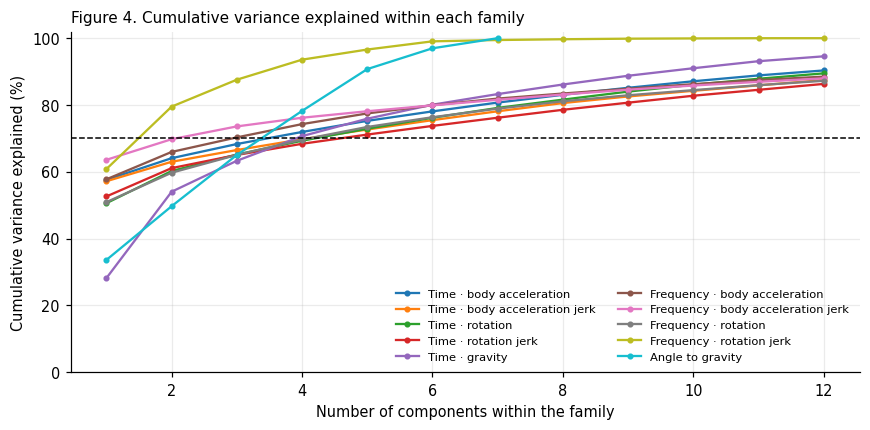

Family,Features,Components retained,Variance on first component,Dominant feature of first component
Time · body acceleration,52,4,58%,tBodyAcc-sma()
Time · body acceleration jerk,52,5,57%,tBodyAccJerk-sma()
Time · rotation,52,5,51%,tBodyGyroMag-mean()
Time · rotation jerk,52,5,53%,tBodyGyroJerk-sma()
Time · gravity,40,4,28%,tGravityAcc-std()-Z
Frequency · body acceleration,91,3,58%,fBodyAcc-sma()
Frequency · body acceleration jerk,91,3,64%,fBodyAccJerk-sma()
Frequency · rotation,91,5,51%,fBodyGyro-sma()
Frequency · rotation jerk,12,2,61%,fBodyBodyGyroJerkMag-std()
Angle to gravity,7,4,34%,"angle(X,gravityMean)"


In [12]:
family_pca = {}
for f in FAMILIES:
    cols = fam_dedup.index[fam_dedup == f]
    family_pca[f] = (cols, PCA(random_state=SEED).fit(S[cols]))
fig, ax = plt.subplots(figsize=(8, 4))
cmap = plt.get_cmap("tab10")
for j, f in enumerate(FAMILIES):
    cum = np.cumsum(family_pca[f][1].explained_variance_ratio_)[:12]
    ax.plot(np.arange(1, len(cum) + 1), cum * 100, marker="o", ms=3, color=cmap(j), label=FAMILY_LABEL[f])
ax.axhline(VAR_RETAIN * 100, color="black", ls="--", lw=1)
ax.set(xlabel="Number of components within the family", ylabel="Cumulative variance explained (%)", ylim=(0, 102))
ax.legend(fontsize=7.5, ncol=2, loc="lower right")
fig_title(ax, "Cumulative variance explained within each family")
plt.tight_layout(); plt.show()
rows = []
for f in FAMILIES:
    cols, p = family_pca[f]
    n = int(np.searchsorted(np.cumsum(p.explained_variance_ratio_), VAR_RETAIN) + 1)
    rows.append({"Family": FAMILY_LABEL[f], "Features": len(cols), "Components retained": n,
                 "Variance on first component": p.explained_variance_ratio_[0],
                 "Dominant feature of first component": cols[np.argmax(np.abs(p.components_[0]))]})
display(pd.DataFrame(rows).style.format({"Variance on first component": "{:.0%}"}).hide(axis="index"))

**Most families are summarised by a few components.** Between two and five components reach 70% of each family's variance, giving 40 components in total.

* In the acceleration and rotation families, the first component explains 51–64% of the variance. Its dominant feature is a magnitude summary (`sma()` or `Mag-mean()`), so it measures **movement intensity**.
* In the gravity and angle families, the first component explains only 28–34%. Their variance is spread across several components, which describe **device orientation** in different directions.

### 4.6 Equalising the Weight of Each Family
After within-family PCA, a family with a large first component would still dominate distances. Following Multiple Factor Analysis (Escofier and Pagès, 1994), each family's components are divided by the standard deviation of its first component, so that every family's dominant direction carries unit weight. The family shares of distance are then compared across the three representations.

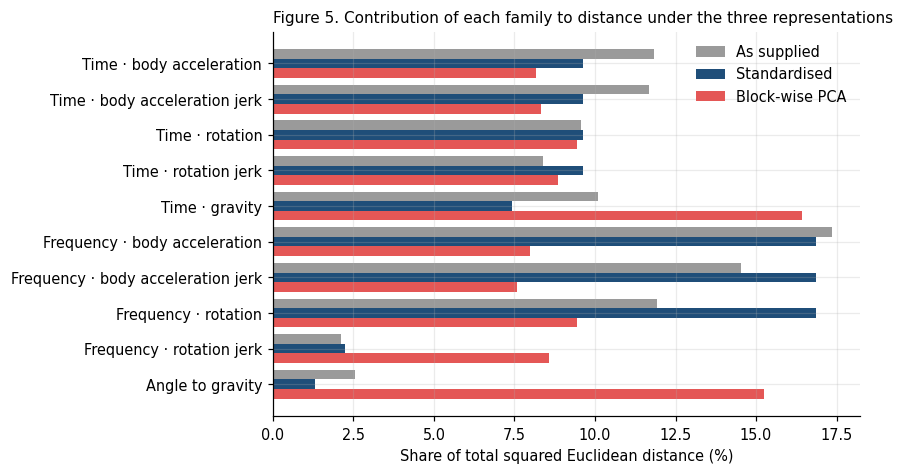

,As supplied,Standardised,Block-wise PCA
min,2.1,1.3,7.6
max,17.3,16.9,16.4


In [13]:
class BlockPCA:
    """Within-family PCA with Multiple Factor Analysis weighting."""
    def __init__(self, families, retain=VAR_RETAIN, n_fixed=None):
        self.families, self.retain, self.n_fixed = families, retain, n_fixed
    def fit(self, S):
        self.blocks_ = []
        for f in FAMILIES:
            cols = self.families.index[self.families == f]
            p = PCA(random_state=SEED).fit(S[cols])
            n = self.n_fixed or int(np.searchsorted(np.cumsum(p.explained_variance_ratio_), self.retain) + 1)
            self.blocks_.append((f, cols, p, min(n, len(cols)), np.sqrt(p.explained_variance_[0])))
        return self
    def transform(self, S):
        return np.hstack([p.transform(S[cols])[:, :n] / sd for f, cols, p, n, sd in self.blocks_])
    def axis_family(self):
        return np.concatenate([[f] * n for f, cols, p, n, sd in self.blocks_])

block = BlockPCA(fam_dedup).fit(S)
Z = block.transform(S)
AXIS_FAM = block.axis_family()
shares["Block-wise PCA"] = (pd.Series(Z.var(0)).groupby(AXIS_FAM).sum() / Z.var(0).sum() * 100).reindex(FAMILIES)
fig, ax = plt.subplots(figsize=(8, 4.4))
for k, (col, c) in enumerate(zip(shares.columns, [C_GREY, C_GLOBAL, C_HIGH])):
    ax.barh(y + (k - 1) * 0.27, shares[col], 0.27, color=c, label=col)
ax.set_yticks(y, [FAMILY_LABEL[f] for f in FAMILIES]); ax.invert_yaxis()
ax.set(xlabel="Share of total squared Euclidean distance (%)"); ax.legend()
fig_title(ax, "Contribution of each family to distance under the three representations")
plt.tight_layout(); plt.show()
display(shares.agg(["min", "max"]).round(1))

**Equal weighting greatly narrows the differences between families.** The range of family contributions narrows from 1.3–16.9% under standardisation to 7.6–16.4% under block-wise PCA.

The weighting is not exactly equal. Each family's *dominant* component carries the same weight, so families that retain more components carry more in total. Gravity (16.4%) and angle (15.2%) now have the largest shares, because their variance is spread across four components each. Orientation, which was almost invisible after standardisation, is therefore represented in the distances as a property in its own right.

### 4.7 The Shared Representation
The final representation has 40 axes and is used by every analysis that follows. Four alternatives are defined here only for the sensitivity analyses in Sections 9.3, 10.2 and 12: two other retention thresholds, a fixed three components per family, and a conventional global PCA with 50 components.

In [14]:
REPS = {"Block-wise PCA, 70% (main)": Z,
        "Block-wise PCA, 60%": BlockPCA(fam_dedup, 0.60).fit(S).transform(S),
        "Block-wise PCA, 80%": BlockPCA(fam_dedup, 0.80).fit(S).transform(S),
        "Block-wise PCA, 3 components per family": BlockPCA(fam_dedup, n_fixed=3).fit(S).transform(S),
        "Global PCA, 50 components": PCA(50, random_state=SEED).fit_transform(S)}
display(pd.Series({k: v.shape[1] for k, v in REPS.items()}, name="Dimensions").to_frame())

,Dimensions
"Block-wise PCA, 70% (main)",40
"Block-wise PCA, 60%",21
"Block-wise PCA, 80%",68
"Block-wise PCA, 3 components per family",30
"Global PCA, 50 components",50


## 5. Distributional Properties of the Features
Before examining structure, the shape of the feature distributions is described. Skewed or bimodal distributions can indicate distinct regimes in the data.

### 5.1 Skewness
Skewness measures asymmetry; values beyond ±1 indicate a strongly asymmetric distribution.

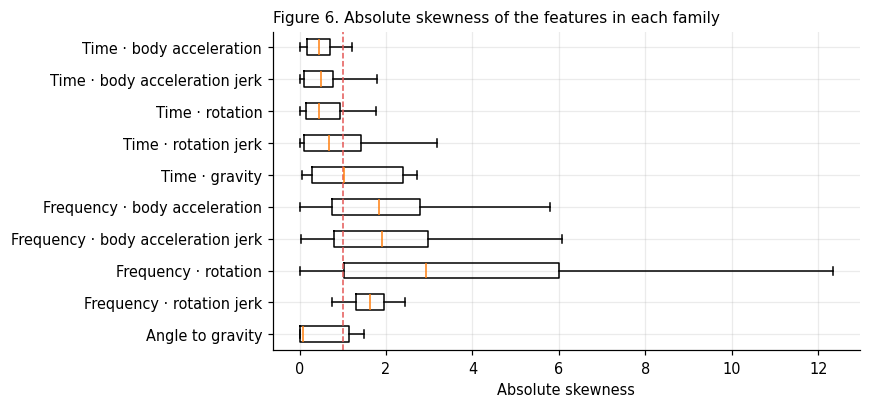

Features with |skewness| > 1: 51%


,Share with |skewness| > 1
Time · body acceleration,15%
Time · body acceleration jerk,23%
Time · rotation,23%
Time · rotation jerk,38%
Time · gravity,50%
Frequency · body acceleration,66%
Frequency · body acceleration jerk,67%
Frequency · rotation,76%
Frequency · rotation jerk,75%
Angle to gravity,29%


In [15]:
sk = pd.Series(skew(X_dedup, axis=0), index=X_dedup.columns)
fig, ax = plt.subplots(figsize=(8, 3.8))
data = [sk[fam_dedup == f].abs().values for f in FAMILIES]
ax.boxplot(data, orientation="horizontal", showfliers=False)
ax.set_yticks(range(1, len(FAMILIES) + 1), [FAMILY_LABEL[f] for f in FAMILIES])
ax.axvline(1, color=C_HIGH, ls="--", lw=1); ax.invert_yaxis()
ax.set(xlabel="Absolute skewness")
fig_title(ax, "Absolute skewness of the features in each family")
plt.tight_layout(); plt.show()
print(f"Features with |skewness| > 1: {(sk.abs() > 1).mean():.0%}")
display((sk.abs() > 1).groupby(fam_dedup).mean().reindex(FAMILIES).rename(index=FAMILY_LABEL).to_frame("Share with |skewness| > 1").style.format("{:.0%}"))

**Approximately half of the features are strongly skewed.** Skewness is most common in the frequency-domain families, where 66–76% of features exceed an absolute skewness of 1, and least common in time-domain body acceleration (15%). Frequency-domain features are often concentrated near their minimum, with a longer tail towards high values.

### 5.2 Bimodality-Coefficient Screening
Sarle's bimodality coefficient combines skewness and kurtosis. A value above 0.555 is a **screening heuristic**, not a direct count or statistical test of modes: highly skewed or other non-bimodal distributions can also exceed it (Pfister et al., 2013). The feature-level result is therefore descriptive; distributions of physically interpretable features are inspected separately.

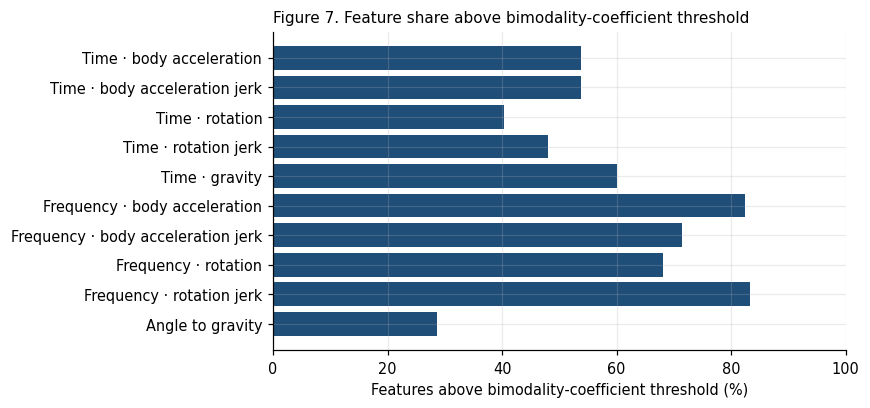

Features with bimodality coefficient > 0.555: 63%


In [16]:
def bimodality(x):
    n = len(x)
    return (skew(x)**2 + 1) / (kurtosis(x) + 3 * (n - 1)**2 / ((n - 2) * (n - 3)))
bc = X_dedup.apply(bimodality)
bimodal_share = (bc > 0.555).groupby(fam_dedup).mean().reindex(FAMILIES) * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh([FAMILY_LABEL[f] for f in FAMILIES], bimodal_share.values, color=C_GLOBAL)
ax.invert_yaxis(); ax.set(xlabel="Features above bimodality-coefficient threshold (%)", xlim=(0, 100))
fig_title(ax, "Feature share above bimodality-coefficient threshold")
plt.tight_layout(); plt.show()
print(f"Features with bimodality coefficient > 0.555: {(bc > 0.555).mean():.0%}")

**The bimodality coefficient exceeds 0.555 for 63% of features.** This occurs most often in frequency-domain families (68–83%) and least often in the angle family (29%). The result flags distributions worth examining; it **does not demonstrate that 63% of the features have two modes**.

### 5.3 An Intensity Feature
The mean magnitude of body acceleration summarises how much the body moves within a window.

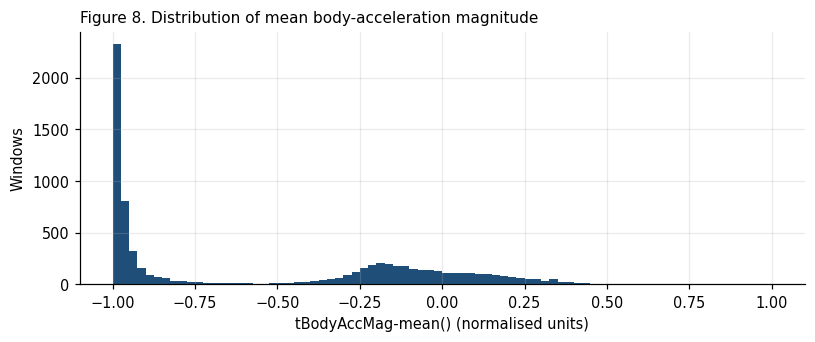

Bimodality coefficient: 0.73; windows below −0.9: 49%


In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(X_dedup["tBodyAccMag-mean()"], bins=80, color=C_GLOBAL)
ax.set(xlabel="tBodyAccMag-mean() (normalised units)", ylabel="Windows")
fig_title(ax, "Distribution of mean body-acceleration magnitude")
plt.tight_layout(); plt.show()
print(f"Bimodality coefficient: {bc['tBodyAccMag-mean()']:.2f}; windows below −0.9: {(X_dedup['tBodyAccMag-mean()'] < -0.9).mean():.0%}")

**The intensity feature has two clearly separated modes.** Almost half of all windows (49%) lie below −0.9, close to the minimum of the scale, and the remainder form a broad second mode. This is the pattern expected if windows fall into two regimes, one with very little movement and one with substantial movement.

### 5.4 An Orientation Feature
The angle between the device's X axis and gravity describes how the phone is oriented.

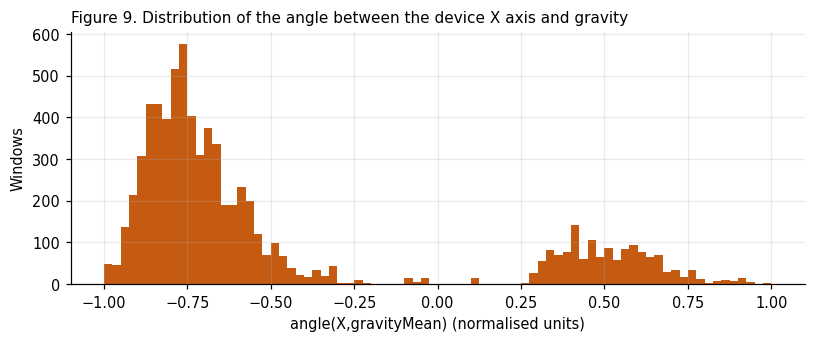

Bimodality coefficient: 0.88; windows above 0: 19%


In [18]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(X_dedup["angle(X,gravityMean)"], bins=80, color=C_LOCAL)
ax.set(xlabel="angle(X,gravityMean) (normalised units)", ylabel="Windows")
fig_title(ax, "Distribution of the angle between the device X axis and gravity")
plt.tight_layout(); plt.show()
print(f"Bimodality coefficient: {bc['angle(X,gravityMean)']:.2f}; windows above 0: {(X_dedup['angle(X,gravityMean)'] > 0).mean():.0%}")

**The orientation feature is also bimodal, but for a different reason.** About a fifth of windows (19%) form a separate mode of device orientation, distinct from the main mode. This bimodality reflects a difference in how the device is oriented, not in how much the body moves. Section 6.7 shows that it corresponds to lying down.

Together, Sections 5.3 and 5.4 suggest two independent sources of structure: **intensity**, which separates still from moving windows, and **orientation**, which separates postures.

## 6. Exploratory Assessment of Cluster Structure
This section asks whether the data contain cluster structure, and what form it takes, before any clustering result is interpreted.

### 6.1 The Principal Intensity Axis
The first axis of the time-domain body-acceleration family summarises movement intensity. Its distribution is examined for separate modes, and the density minimum between the two largest modes is located.

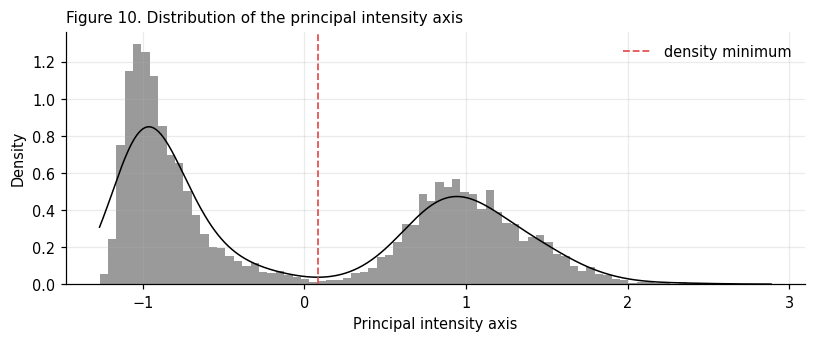

Windows above the density minimum: 45.7%


In [19]:
j_int = int(np.flatnonzero(AXIS_FAM == "t:Acc")[0])
intensity_axis = Z[:, j_int] * np.sign(np.corrcoef(Z[:, j_int], W.acc_rms)[0, 1])   # higher = more movement
grid = np.linspace(intensity_axis.min(), intensity_axis.max(), 600)
dens = gaussian_kde(intensity_axis)(grid)
peaks = [i for i in range(1, len(grid) - 1) if dens[i] > dens[i - 1] and dens[i] > dens[i + 1]]
p1, p2 = sorted(sorted(peaks, key=lambda i: dens[i])[-2:])
REGIME_CUT = grid[p1 + np.argmin(dens[p1:p2])]
W["regime"] = np.where(intensity_axis > REGIME_CUT, "higher intensity", "lower intensity")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(intensity_axis, bins=80, color=C_GREY, density=True)
ax.plot(grid, dens, color="black", lw=1)
ax.axvline(REGIME_CUT, color=C_HIGH, ls="--", lw=1.2, label="density minimum")
ax.set(xlabel="Principal intensity axis", ylabel="Density"); ax.legend()
fig_title(ax, "Distribution of the principal intensity axis")
plt.tight_layout(); plt.show()
print(f"Windows above the density minimum: {(W.regime == 'higher intensity').mean():.1%}")

**The intensity axis divides the windows into two regimes.** Its distribution has two well-separated modes, with a pronounced density minimum between them. The minimum places 45.7% of windows in a higher-intensity regime and the rest in a lower-intensity regime. These regimes are used to describe the preliminary anomaly results in Section 7, before any clustering is fitted.

### 6.2 Cluster Tendency
The Hopkins statistic compares distances from real windows to their nearest neighbours with distances from uniformly placed points to their nearest real window (Hopkins and Skellam, 1954). A value near 0.5 indicates no structure, and values near 1 indicate strong clustering tendency.

In [20]:
def hopkins(X, m=500, seed=SEED):
    r = np.random.default_rng(seed)
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    real = X[r.choice(len(X), m, replace=False)]
    unif = r.uniform(X.min(0), X.max(0), size=(m, X.shape[1]))
    w = nn.kneighbors(real)[0][:, 1]; u = nn.kneighbors(unif, n_neighbors=1)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())
H = [hopkins(Z, seed=s) for s in range(10)]
print(f"Hopkins statistic: mean {np.mean(H):.3f} over 10 samples (range {min(H):.3f}–{max(H):.3f})")

Hopkins statistic: mean 0.892 over 10 samples (range 0.889–0.894)


**The data show a strong clustering tendency.** The Hopkins statistic is 0.89, far above the value of 0.5 expected for data with no structure.

This value should be interpreted with caution. In 40 dimensions, uniformly placed reference points tend to fall in empty space, which pushes the statistic upwards. It is therefore treated as supporting evidence rather than proof of cluster structure.

### 6.3 Internal Validity of K-Means
K-Means is fitted for k = 2 to 9. The silhouette (Rousseeuw, 1987) measures how much closer windows are to their own cluster than to the next nearest one.

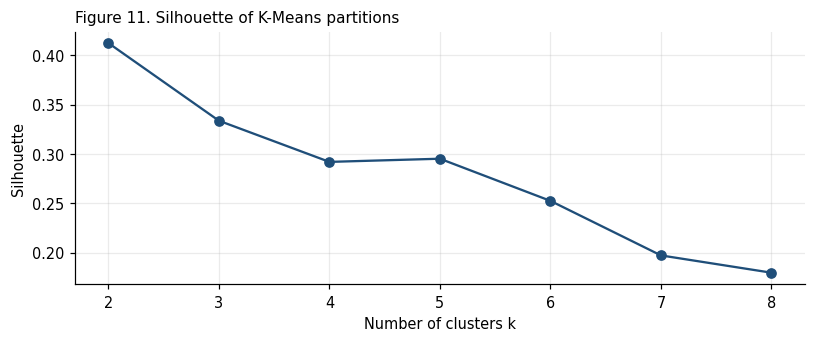

In [21]:
KM = {k: KMeans(k, n_init=10, random_state=SEED).fit(Z) for k in range(2, 10)}
km_valid = pd.DataFrame({k: {"Silhouette": silhouette_score(Z, KM[k].labels_, sample_size=4000, random_state=SEED),
                             "Davies–Bouldin": davies_bouldin_score(Z, KM[k].labels_),
                             "Calinski–Harabasz": calinski_harabasz_score(Z, KM[k].labels_)} for k in range(2, 9)}).T
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(km_valid.index, km_valid["Silhouette"], marker="o", color=C_GLOBAL)
ax.set(xlabel="Number of clusters k", ylabel="Silhouette")
fig_title(ax, "Silhouette of K-Means partitions")
plt.tight_layout(); plt.show()

**Two clusters give the clearest separation.** The silhouette is highest at k = 2 (0.41) and declines as k increases, with a minor plateau at k = 4–5. No finer partition approaches the separation of the two-cluster solution.

### 6.4 Model Selection for Gaussian Mixtures
Gaussian mixtures with spherical, diagonal and full covariance are fitted with 1 to 10 components. The Bayesian information criterion (BIC) balances fit against complexity; lower values are preferred.

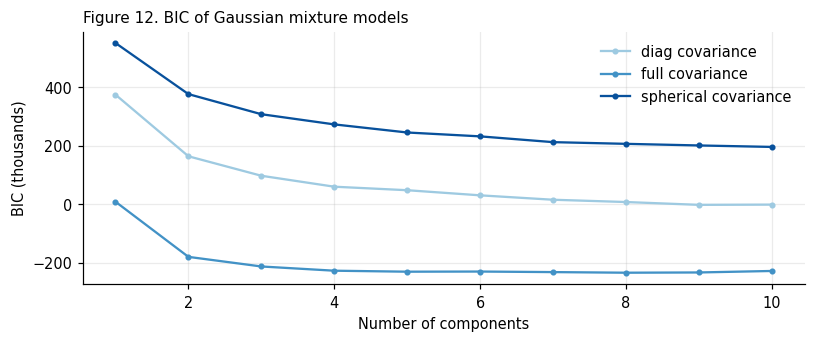

Number of components with the lowest BIC: {'diag': 9, 'full': 8, 'spherical': 10}


In [22]:
GMM, bic = {}, {}
for cov in ["spherical", "diag", "full"]:
    for k in range(1, 11):
        GMM[(cov, k)] = GaussianMixture(k, covariance_type=cov, reg_covar=1e-4, n_init=2, random_state=SEED).fit(Z)
        bic[(cov, k)] = GMM[(cov, k)].bic(Z)
bic = pd.Series(bic).unstack(0)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for cov, c in zip(bic.columns, ["#9ecae1", "#4292c6", "#08519c"]):
    ax.plot(bic.index, bic[cov] / 1e3, marker="o", ms=3, color=c, label=f"{cov} covariance")
ax.set(xlabel="Number of components", ylabel="BIC (thousands)"); ax.legend()
fig_title(ax, "BIC of Gaussian mixture models")
plt.tight_layout(); plt.show()
print("Number of components with the lowest BIC:", {cov: int(bic[cov].idxmin()) for cov in bic.columns})

**BIC favours many more components than the silhouette does.** For every covariance structure, BIC continues to improve up to 8–10 components. This indicates that the density within clusters is not Gaussian, so a mixture needs extra components to describe it. It does not, on its own, show that eight to ten natural groups exist. Section 9.1 compares the two-component mixtures with K-Means directly.

### 6.5 Density Structure
Density-based clustering separates dense regions from sparse ones. The distance from each window to its 15th nearest neighbour is sorted to show how density varies across the data.

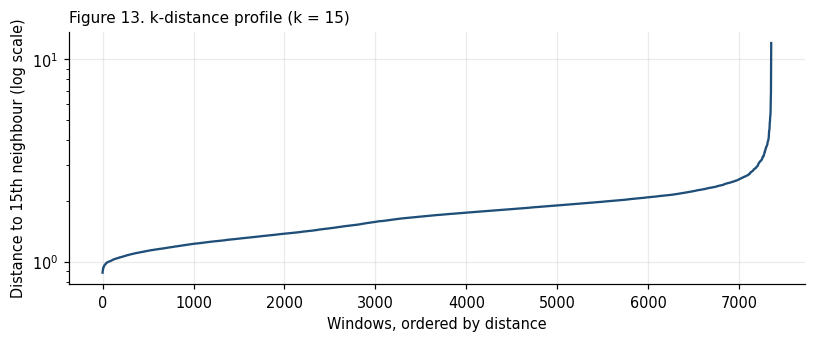

Distance to 15th neighbour: median 1.7, 90th percentile 2.3, 99th percentile 3.5


In [23]:
d_knn, i_knn = NearestNeighbors(n_neighbors=K_NN + 1).fit(Z).kneighbors(Z)
knn_dist = d_knn[:, K_NN]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(np.sort(knn_dist), color=C_GLOBAL); ax.set_yscale("log")
ax.set(xlabel="Windows, ordered by distance", ylabel="Distance to 15th neighbour (log scale)")
fig_title(ax, "k-distance profile (k = 15)")
plt.tight_layout(); plt.show()
q = np.quantile(knn_dist, [0.5, 0.9, 0.99])
print(f"Distance to 15th neighbour: median {q[0]:.1f}, 90th percentile {q[1]:.1f}, 99th percentile {q[2]:.1f}")

**Density varies smoothly, with a short tail of isolated windows.** Most windows have their 15th neighbour within a narrow range of distances (median 1.7, 90th percentile 2.3), but the sparsest 1% are at least twice as far away (3.5 or more).

The profile has no sharp bend that would separate dense clusters from noise at a single density level. Density-based clustering is therefore likely to be sensitive to its density parameter, which Section 9.4.3 confirms.

### 6.6 Low-Dimensional Projections
Three projections show the data in two dimensions. Each point is coloured by local density, measured as the negative logarithm of the distance to the 15th nearest neighbour. Distances between distant groups in t-SNE and UMAP are not meaningful; only neighbourhoods are.

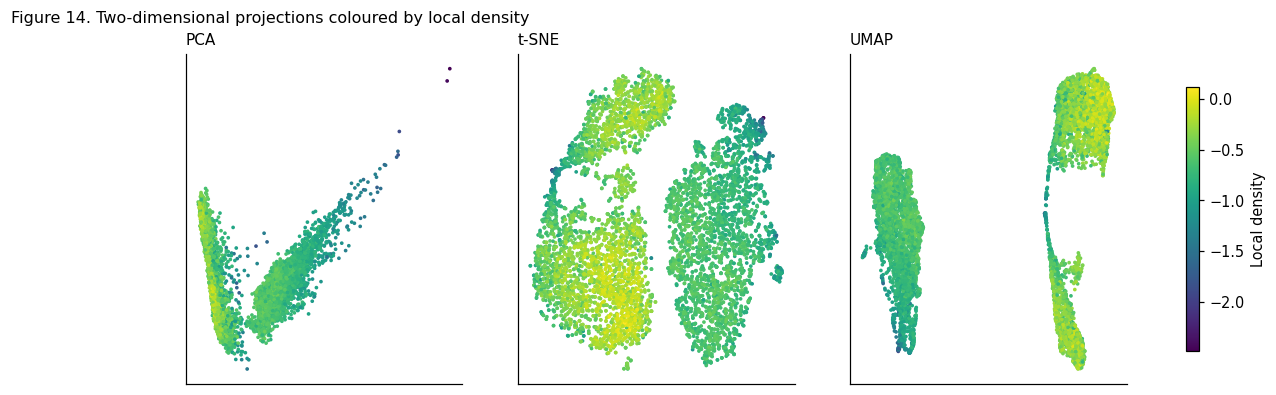

In [24]:
emb = {"PCA": PCA(2, random_state=SEED).fit_transform(Z),
       "t-SNE": TSNE(2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Z)}
TSNE_XY = emb["t-SNE"]
if HAS_UMAP:
    emb["UMAP"] = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(Z)
fig, ax = plt.subplots(1, len(emb), figsize=(4.6 * len(emb), 3.9))
for a, (name, E) in zip(np.atleast_1d(ax), emb.items()):
    sc = a.scatter(E[:, 0], E[:, 1], c=-np.log(knn_dist), s=2, cmap="viridis", rasterized=True)
    a.set(title=name, xticks=[], yticks=[]); a.grid(False)
fig.colorbar(sc, ax=ax, label="Local density", shrink=0.8)
fig_title(fig, "Two-dimensional projections coloured by local density")
plt.show()

**All three projections show two separate masses.** The lower-intensity mass is compact and dense. The higher-intensity mass is larger, less dense and internally heterogeneous, and its periphery contains the sparsest windows.

Each candidate clustering approach is therefore plausible:
* the two masses suggest compact clusters (K-Means);
* their different shapes and spreads suggest flexible mixtures;
* the substructure within the masses suggests a hierarchy;
* the variation in density suggests density-based clustering.

### 6.7 Correspondence with Recorded Activities
The t-SNE projection is now coloured by the recorded activity, to interpret the structure already observed.

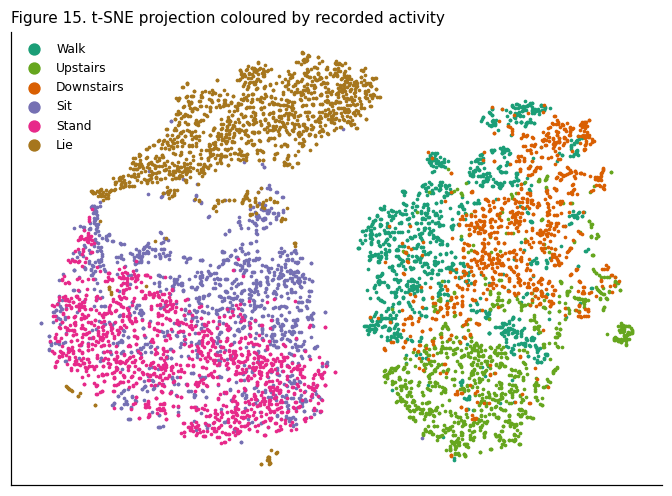

In [25]:
pal = dict(zip(ACT_ORDER, ["#1b9e77", "#66a61e", "#d95f02", "#7570b3", "#e7298a", "#a6761d"]))
fig, ax = plt.subplots(figsize=(6.2, 4.6))
for a_ in ACT_ORDER:
    m = act == a_
    ax.scatter(emb["t-SNE"][m, 0], emb["t-SNE"][m, 1], s=2, color=pal[a_], label=ACT_SHORT[a_], rasterized=True)
ax.set(xticks=[], yticks=[]); ax.grid(False); ax.legend(markerscale=5, fontsize=8)
fig_title(ax, "t-SNE projection coloured by recorded activity")
plt.tight_layout(); plt.show()

For each activity, the table shows the activities of the ten nearest neighbours of its windows in the full representation.

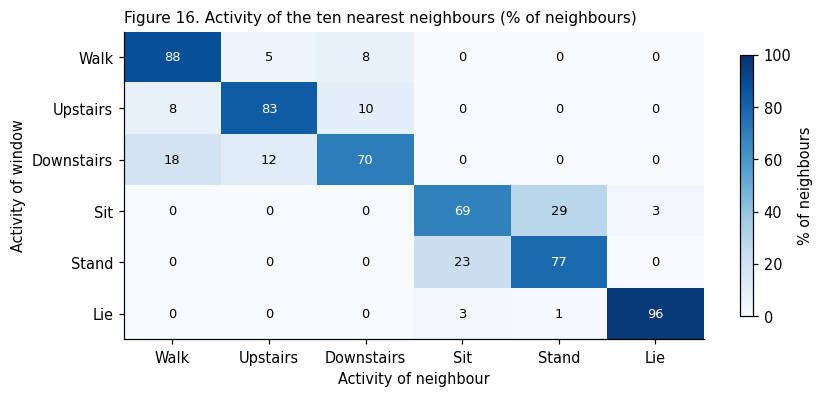

In [26]:
nb_act = act[i_knn[:, 1:11]]
mix = pd.DataFrame([pd.Series(nb_act[act == a_].ravel()).value_counts(normalize=True).reindex(ACT_ORDER, fill_value=0)
                    for a_ in ACT_ORDER], index=ACT_ORDER).rename(index=ACT_SHORT, columns=ACT_SHORT) * 100
heatmap(mix, "Activity of the ten nearest neighbours (% of neighbours)", fmt="{:.0f}", vmin=0, vmax=100,
        xlabel="Activity of neighbour", ylabel="Activity of window", cbar_label="% of neighbours")

**The two masses correspond to static and dynamic activities, but the six activities are not equally separable.**
* Lying forms a coherent region: 96% of its neighbours are also lying.
* Sitting and standing overlap substantially: 23–29% of their neighbours carry the other label.
* Among the dynamic activities, walking downstairs is the least coherent: only 70% of its neighbours share its label, and 18% are walking.

The difference between sitting and standing, and the differences among the walking activities, are small compared with the dominant contrast between still and moving windows.

## 7. Preliminary Anomaly Screening

### 7.1 Anomaly Scores
The baseline anomaly score is the **distance to the 15th nearest other window**, a standard global distance-based score (Ramaswamy et al., 2000). A second score, the reconstruction error of a PCA model of the representation, measures departure from the dominant linear structure rather than distance from neighbours. The two are compared on their top 5% of windows.

In [27]:
def top_flags(score, q=TOP):
    score = np.asarray(score)
    return score > np.quantile(score, 1 - q)

def jaccard(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    return (a & b).sum() / max(1, (a | b).sum())

W["score_knn"] = knn_dist
W["flag"] = top_flags(knn_dist)
W["score_pct"] = pd.Series(knn_dist).rank(pct=True).to_numpy()
pca_rec = PCA(0.80, random_state=SEED).fit(Z)
rec_err = ((Z - pca_rec.inverse_transform(pca_rec.transform(Z)))**2).sum(1)
print(f"Agreement between the k-NN and PCA-reconstruction shortlists (Jaccard): {jaccard(W.flag, top_flags(rec_err)):.2f}")
print(f"Rank correlation between the two scores: {spearmanr(knn_dist, rec_err)[0]:.2f}")

Agreement between the k-NN and PCA-reconstruction shortlists (Jaccard): 0.44
Rank correlation between the two scores: 0.84


**The two scores capture related but different notions of unusualness.** Their rankings are strongly correlated (Spearman 0.84), but their top-5% shortlists overlap only moderately (Jaccard 0.44). Distance from one's neighbours and departure from the dominant linear structure therefore pick out partly different windows. The k-NN score is used as the baseline from here on.

### 7.2 Threshold Selection
A threshold is needed to obtain a shortlist of unusual windows. The distribution of the k-NN score is examined for a natural break.

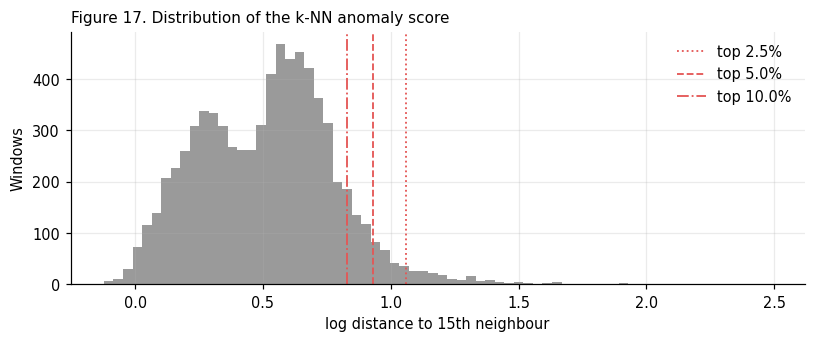

In [28]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(np.log(knn_dist), bins=70, color=C_GREY)
for q, ls in zip(SHORTLISTS, [":", "--", "-."]):
    ax.axvline(np.log(np.quantile(knn_dist, 1 - q)), color=C_HIGH, ls=ls, lw=1.2, label=f"top {q:.1%}")
ax.set(xlabel="log distance to 15th neighbour", ylabel="Windows"); ax.legend()
fig_title(ax, "Distribution of the k-NN anomaly score")
plt.tight_layout(); plt.show()

**The score distribution has no natural break.** It declines smoothly into a long upper tail, so no threshold separates anomalies from ordinary windows. The top 5% is therefore used as a working shortlist. Shortlists of 2.5% and 10% are reported alongside it to show that the conclusions do not depend on this choice.

The top 5% of windows are shown on the t-SNE projection of Section 6.6.

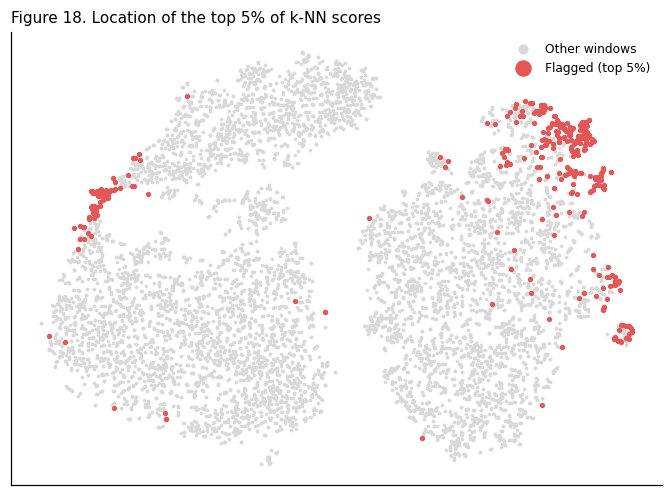

In [29]:
fig, ax = plt.subplots(figsize=(6.2, 4.6))
map_plot(ax, highlight=W.flag.to_numpy(), title="Flagged (top 5%)")
fig_title(ax, "Location of the top 5% of k-NN scores")
plt.tight_layout(); plt.show()

**Flagged windows lie at the edges of the two masses.** Most are in the higher-intensity mass, concentrated at its periphery and in small outlying groups. In the lower-intensity mass, flags form one compact group at its left edge, between the regions occupied by lying and by sitting and standing, with a few others scattered at its margins. None lie in the dense interior of either mass.

### 7.3 Flags by Position Within the Episode
Flag rates are compared between the start, interior and end of recording episodes, separately for the two intensity regimes of Section 6.1.

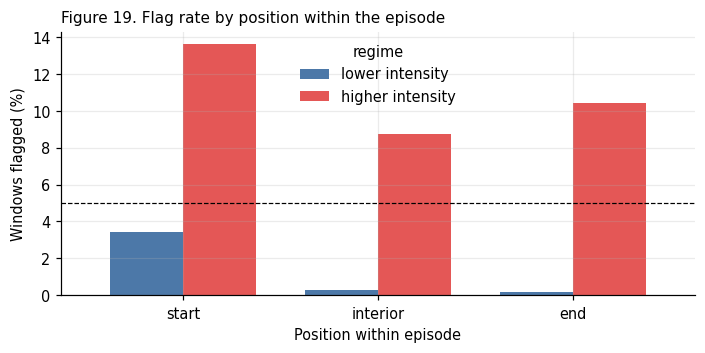

Windows  Flagged (%)  Mean score percentile
regime           position                                             
higher intensity end           689        10.45                   0.74
                 interior     1939         8.77                   0.71
                 start         734        13.62                   0.78
lower intensity  end           502         0.20                   0.28
                 interior     3023         0.30                   0.27
                 start         465         3.44                   0.59

In [30]:
pos_rate = W.pivot_table(index="position", columns="regime", values="flag", aggfunc="mean").reindex(["start", "interior", "end"]) * 100
fig, ax = plt.subplots(figsize=(6.5, 3.3))
pos_rate[["lower intensity", "higher intensity"]].plot.bar(ax=ax, color=[C_LOW, C_HIGH], rot=0, width=0.75)
ax.axhline(5, color="black", ls="--", lw=0.8)
ax.set(xlabel="Position within episode", ylabel="Windows flagged (%)")
fig_title(ax, "Flag rate by position within the episode")
plt.tight_layout(); plt.show()
screen = W.groupby(["regime", "position"]).agg(Windows=("flag", "size"), **{"Flagged (%)": ("flag", "mean"),
                                                "Mean score percentile": ("score_pct", "mean")})
screen["Flagged (%)"] *= 100
display(screen.round(2))

**In the lower-intensity regime, flags occur almost only at the start of episodes.** The flag rate is 3.4% in the first two windows of an episode, against 0.3% in the interior and 0.2% at the end. The threshold-free mean score percentile shows the same pattern: 0.59 at the start against 0.27–0.28 elsewhere.

This is consistent with extra movement around the beginning of recorded episodes; a removed postural transition is one possible explanation, but the actual transition is not annotated or observed directly. In the higher-intensity regime, flag rates are high throughout (8.8–13.6%), with only a modest increase at the start and end.

### 7.4 Flags by Change Within the Window
A window in which body-acceleration energy or estimated gravity direction changes sharply may reflect movement within an otherwise quiet recording; it is not itself evidence of an annotated transition. Each window is ranked within its regime by the larger of its energy-change and tilt-change percentiles, and flag rates are compared across deciles.

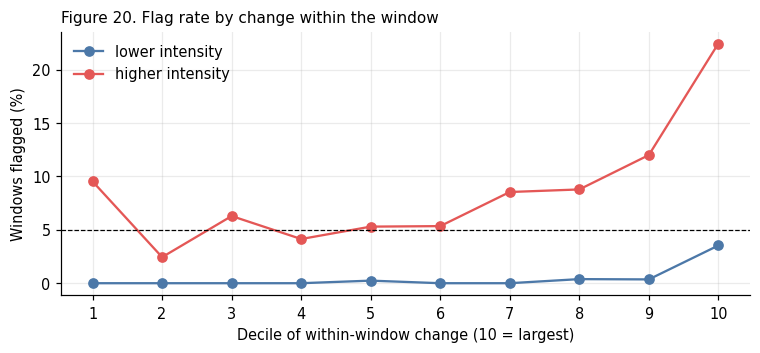

change_decile,1,2,3,4,5,6,7,8,9,10
regime,,,,,,,,,,
higher intensity,9.5,2.4,6.3,4.1,5.3,5.3,8.5,8.8,12.0,22.4
lower intensity,0.0,0.0,0.0,0.0,0.2,0.0,0.0,0.4,0.4,3.5


In [31]:
W["change_pct"] = np.maximum(W.groupby("regime").energy_change.rank(pct=True), W.groupby("regime").tilt_change.rank(pct=True))
W["change_decile"] = np.minimum((W.change_pct * 10).astype(int), 9) + 1
fig, ax = plt.subplots(figsize=(7, 3.3))
for reg, c in [("lower intensity", C_LOW), ("higher intensity", C_HIGH)]:
    r_ = W[W.regime == reg].groupby("change_decile").flag.mean() * 100
    ax.plot(r_.index, r_.values, marker="o", color=c, label=reg)
ax.axhline(5, color="black", ls="--", lw=0.8)
ax.set(xlabel="Decile of within-window change (10 = largest)", ylabel="Windows flagged (%)", xticks=range(1, 11)); ax.legend()
fig_title(ax, "Flag rate by change within the window")
plt.tight_layout(); plt.show()
display((W.pivot_table(index="change_decile", columns="regime", values="flag", aggfunc="mean") * 100).round(1).T)

**Unusual low-intensity windows are associated with within-window change.** This analysis examines whether a flagged window also shows a large change in body-acceleration energy or **estimated gravity direction**. The plot and table should be interpreted as associations between two measured properties, not a direct count of postural transitions.

* In the **lower-intensity** regime, flags are almost confined to the top decile of within-window change (3.5%, against at most 0.4% in deciles 1–9).
* In the **higher-intensity** regime, the flag rate also peaks in the top decile (22.4%), but it is never near zero and is elevated in the lowest decile too (9.5%).

Unusual static windows therefore almost always contain a marked change, whereas unusual dynamic windows occur both with and without one; in dynamic movement a high anomaly score is not equivalent to a sudden change.

### 7.5 Flags by Participant
Participants contribute similar numbers of windows, so their flag rates can be compared directly.

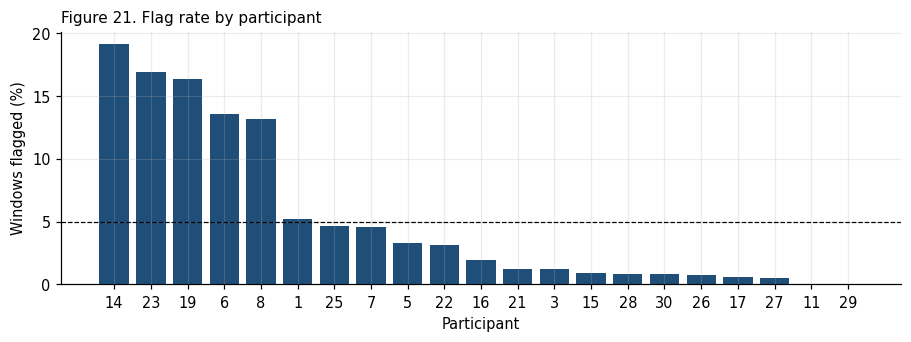

Share of all flags held by the five most-flagged participants: 72%


In [32]:
person_rate = W.groupby("subject").flag.mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.bar(person_rate.index.astype(str), person_rate.values, color=C_GLOBAL)
ax.axhline(5, color="black", ls="--", lw=0.8)
ax.set(xlabel="Participant", ylabel="Windows flagged (%)")
fig_title(ax, "Flag rate by participant")
plt.tight_layout(); plt.show()
print(f"Share of all flags held by the five most-flagged participants: {W[W.flag].subject.value_counts().head(5).sum() / W.flag.sum():.0%}")

**Flags are concentrated among a few participants.** Five participants hold 72% of all flags. Several have flag rates of 12–19%, three to four times the overall 5%, while most others are below 5%. Section 11 examines whether this reflects consistent differences in how these people move.

### 7.6 Correspondence with Recorded Activities
Flag rates by activity are expressed as a ratio to the shortlist proportion, so that a value of 1 indicates a proportional share.

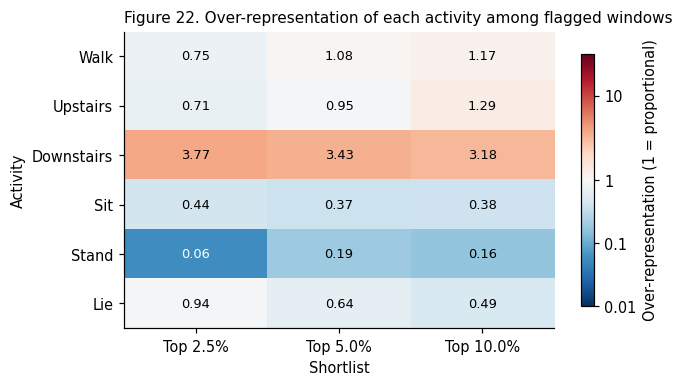

In [33]:
rates_act = pd.DataFrame({f"Top {q:.1%}": pd.Series(top_flags(knn_dist, q)).groupby(act).mean() / q for q in SHORTLISTS})
heatmap(rates_act.reindex(ACT_ORDER).rename(index=ACT_SHORT), "Over-representation of each activity among flagged windows",
        fmt="{:.2f}", ratio=True, xlabel="Shortlist", ylabel="Activity", cbar_label="Over-representation (1 = proportional)",
        figsize=(6.2, 3.6))

**Walking downstairs is flagged more than three times as often as its proportional share.** This holds at every shortlist size (3.2–3.8 times), whereas standing and sitting are strongly under-represented. Section 10 tests whether this reflects the variability of the movement or the global reference used by the score.

## 8. Research Questions
The exploration produced three observations:
* the representation contains two dominant concentrations of windows, with heterogeneous substructure (Section 6);
* the global anomaly score concentrates in the higher-intensity region and among a few participants (Sections 7.3 and 7.5);
* in the lower-intensity region, flags occur almost only at the start of recording episodes (Section 7.3).

These observations motivate three research questions, each divided into sub-questions that correspond to the subsections that follow.

**RQ1.** *Does human movement naturally organise into distinct categories, or into broader families containing overlapping and more specialised patterns?*
* What is the dominant global structure, and how many clusters does the evidence support? (§9.1)
* Is this structure stable across participants, and at what finer resolution does it remain reproducible? (§9.2)
* Is it robust to the choice of representation and clustering algorithm? (§9.3)
* Does finer structure exist within the broad families, and does it reflect movement or individual participants? (§9.4)
* Which physical characteristics distinguish the clusters? (§9.5)

**RQ2.** *Are some forms of movement inherently more variable than others, and does this variability explain why they appear disproportionately unusual?*
* Do the clusters differ in variability, and does their over-representation among flagged windows depend on the detector's reference population? (§10.1)
* Is this pattern robust to neighbourhood size, threshold and representation? (§10.2)
* Does equalising within-cluster spread remove the over-representation, and how does it depend on the number of reference clusters? (§10.3)
* Do flagged windows lie between clusters or beyond them, and what characterises them physically? (§10.4)

**RQ3.** *Do unusual observations represent consistent differences in how individuals move, or isolated departures from otherwise typical behaviour?*
* How is variation in the anomaly score divided between participants, episodes and individual windows? (§11.1)
* Are participant-level anomaly rates reproducible across independent episodes? (§11.2)
* Are these findings robust to the detector and to participant-level offsets? (§11.3)
* What observable contexts and recurring patterns accompany flagged windows? (§11.4)
* How are recurrent differences associated with movement intensity and estimated orientation, and what remains unresolved? (§11.5)

## 9. RQ1: The Organisation of Human Movement
Four clustering approaches are used, each to test one assumption:
* **K-Means**, the principal method, assumes compact clusters of similar size;
* **Gaussian mixtures** relax the assumption about cluster shape and give soft membership;
* **Ward's hierarchical clustering** tests whether the structure is nested;
* **HDBSCAN** (Campello et al., 2013) treats clusters as dense regions separated by sparse space, and can leave windows unassigned.

### 9.1 Selection of the Global Partition

#### 9.1.1 Internal Validity Indices
The number of clusters is chosen from three internal indices: the silhouette and Calinski–Harabasz index (higher is better) and the Davies–Bouldin index (lower is better).

In [34]:
K_BROAD = int(km_valid["Silhouette"].idxmax())
display(km_valid.style.format({"Silhouette": "{:.3f}", "Davies–Bouldin": "{:.2f}", "Calinski–Harabasz": "{:.0f}"})
        .highlight_max(subset=["Silhouette", "Calinski–Harabasz"], color="#dbe9f6")
        .highlight_min(subset=["Davies–Bouldin"], color="#dbe9f6"))
lab2 = KM[K_BROAD].labels_
hi = int(np.argmax([intensity_axis[lab2 == c].mean() for c in range(K_BROAD)]))
fam = (lab2 == hi).astype(int)                       # 1 = higher-intensity family
W["family"] = fam
FAM_NAME = {0: "Low-intensity family", 1: "High-intensity family"}
print(f"Selected k = {K_BROAD}; family sizes: {np.bincount(fam).tolist()} windows")
print(f"Agreement with the intensity regimes of Section 6.1: ARI = {adjusted_rand_score(fam, (W.regime == 'higher intensity').astype(int)):.3f}")

,Silhouette,Davies–Bouldin,Calinski–Harabasz
2,0.412,1.02,6188
3,0.334,1.16,4378
4,0.292,1.46,3736
5,0.295,1.34,3208
6,0.252,1.57,2843
7,0.197,1.66,2585
8,0.180,1.71,2339


Selected k = 2; family sizes: [4065, 3287] windows
Agreement with the intensity regimes of Section 6.1: ARI = 0.960


**All three indices select two clusters.** At k = 2 the silhouette (0.41) and Calinski–Harabasz index (6,188) are highest, and the Davies–Bouldin index (1.02) is lowest. The two clusters are of similar size (4,065 and 3,287 windows) and coincide almost exactly with the intensity regimes of Section 6.1 (ARI 0.96). They are referred to as the **low-intensity family** and the **high-intensity family**.

The two families are shown on the t-SNE projection.

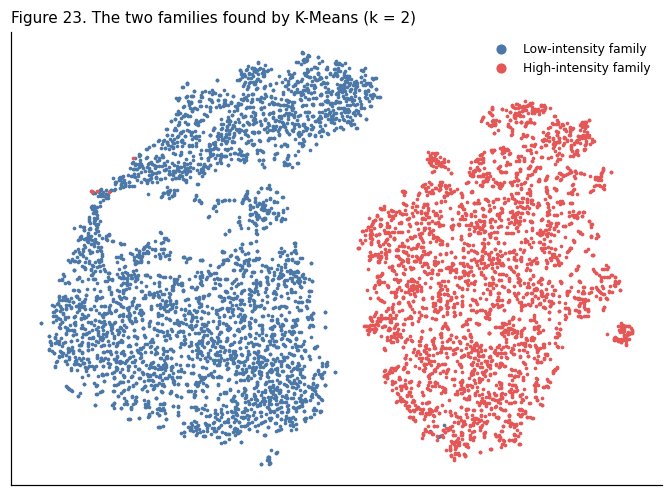

In [35]:
fig, ax = plt.subplots(figsize=(6.2, 4.6))
map_plot(ax, values=np.array([FAM_NAME[f] for f in fam]), colours={FAM_NAME[0]: C_LOW, FAM_NAME[1]: C_HIGH})
fig_title(ax, "The two families found by K-Means (k = 2)")
plt.tight_layout(); plt.show()

**The two families correspond to the two masses of the projection.** The boundary between them follows the gap between the masses, with almost no windows of one family inside the other's region.

#### 9.1.2 Agreement with Gaussian Mixture Models
If the two-cluster structure does not depend on the assumption of compact clusters, Gaussian mixtures should recover the same partition.

In [36]:
gmm_rows = []
for cov in bic.columns:
    g2 = GMM[(cov, 2)]
    gmm_rows.append({"Covariance": cov, "Components with lowest BIC": int(bic[cov].idxmin()),
                     "Agreement with K-Means at k = 2 (ARI)": adjusted_rand_score(lab2, g2.predict(Z)),
                     "Windows with membership probability < 0.9": (g2.predict_proba(Z).max(1) < 0.9).mean()})
display(pd.DataFrame(gmm_rows).style.format({"Agreement with K-Means at k = 2 (ARI)": "{:.3f}",
                                             "Windows with membership probability < 0.9": "{:.1%}"}).hide(axis="index"))

Covariance,Components with lowest BIC,Agreement with K-Means at k = 2 (ARI),Windows with membership probability < 0.9
diag,9,0.960,0.1%
full,8,0.870,0.1%
spherical,10,0.960,0.1%


**Gaussian mixtures recover the same two families.**
* With diagonal or spherical covariance, the two-component mixture agrees with K-Means almost exactly (ARI 0.96).
* With full covariance, agreement is lower (ARI 0.87), because the flexible components begin to model the elongated shape of the high-intensity family.
* Fewer than 0.2% of windows have uncertain membership.

The two-family structure therefore does not depend on the assumption of compact clusters. The BIC preference for 8–10 components (Section 6.4) is not matched by any validity index, so it is interpreted as the mixture describing non-Gaussian density within the families.

#### 9.1.3 Correspondence with Recorded Activities

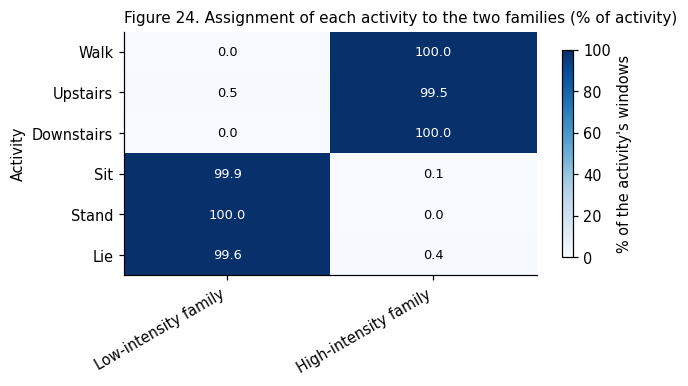

Agreement with the static/dynamic distinction: 99.8% of windows (ARI = 0.993)


In [37]:
ct = pd.crosstab(pd.Series(act, name="Activity"), pd.Series(fam, name="Family"), normalize="index").reindex(ACT_ORDER) * 100
ct.columns = [FAM_NAME[c] for c in ct.columns]
heatmap(ct.rename(index=ACT_SHORT), "Assignment of each activity to the two families (% of activity)", fmt="{:.1f}",
        vmin=0, vmax=100, ylabel="Activity", cbar_label="% of the activity's windows", figsize=(6, 3.6))
dynamic = np.isin(act, ACT_ORDER[:3])
print(f"Agreement with the static/dynamic distinction: {(fam == dynamic).mean():.1%} of windows (ARI = {adjusted_rand_score(dynamic, fam):.3f})")

**The two families correspond to the static and dynamic activities.** They agree with the static/dynamic distinction for 99.8% of windows (ARI 0.993), and no activity has more than 0.5% of its windows in the other family.

### 9.2 Stability Under Participant Resampling

#### 9.2.1 Reproducibility Across Participants and Initialisations
A structure that reflects human movement, rather than the particular people recorded, should be reproduced when the participants change. K-Means is refitted twenty times on 17 of the 21 participants, and each refitted model is compared with the reference model on the four withheld participants. Sensitivity to initialisation is assessed with ten single-start fits.

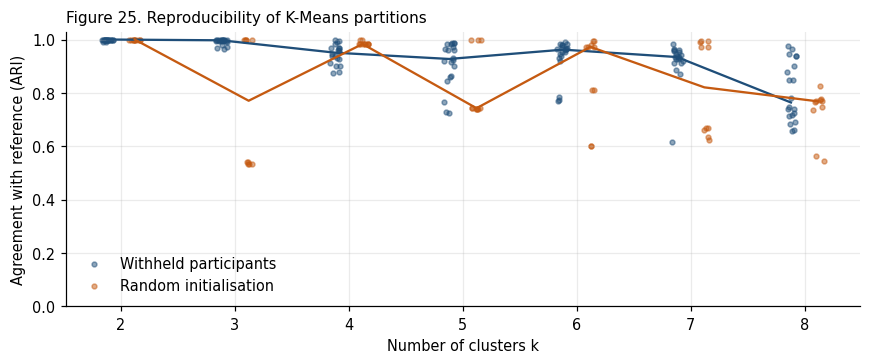

median                                         min                      
test Random initialisation Withheld participants Random initialisation Withheld participants
k                                                                                           
2                    1.000                 1.000                 1.000                 0.991
3                    0.770                 0.997                 0.532                 0.965
4                    0.983                 0.951                 0.983                 0.873
5                    0.742                 0.927                 0.738                 0.723
6                    0.972                 0.962                 0.600                 0.768
7                    0.821                 0.934                 0.624                 0.614
8                    0.768                 0.764                 0.546                 0.659

In [38]:
people = np.unique(subj)
r_ = np.random.default_rng(SEED)
stab = []
for k in range(2, 9):
    for rep in range(20):
        keep = np.isin(subj, r_.choice(people, 17, replace=False))
        alt = KMeans(k, n_init=5, random_state=rep).fit(Z[keep])
        stab.append({"k": k, "test": "Withheld participants", "ARI": adjusted_rand_score(KM[k].predict(Z[~keep]), alt.predict(Z[~keep]))})
    for s in range(10):
        stab.append({"k": k, "test": "Random initialisation", "ARI": adjusted_rand_score(KM[k].labels_, KMeans(k, n_init=1, random_state=100 + s).fit_predict(Z))})
stab = pd.DataFrame(stab)
fig, ax = plt.subplots(figsize=(8, 3.4))
for t, c, dx in [("Withheld participants", C_GLOBAL, -0.12), ("Random initialisation", C_LOCAL, 0.12)]:
    s_ = stab[stab.test == t]
    ax.scatter(s_.k + dx + np.random.default_rng(1).uniform(-0.05, 0.05, len(s_)), s_.ARI, s=10, alpha=0.5, color=c, label=t)
    med = s_.groupby("k").ARI.median(); ax.plot(med.index + dx, med.values, color=c, lw=1.5)
ax.set(xlabel="Number of clusters k", ylabel="Agreement with reference (ARI)", ylim=(0, 1.03)); ax.legend(loc="lower left")
fig_title(ax, "Reproducibility of K-Means partitions")
plt.tight_layout(); plt.show()
display(stab.groupby(["k", "test"]).ARI.agg(["median", "min"]).unstack().round(3))

**The two families are reproduced exactly; finer partitions are less secure.**
* **k = 2** is reproduced on withheld participants in every replicate (median ARI 1.00, minimum 0.99) and does not depend on initialisation.
* **k = 3 to 7** are also largely reproduced on withheld participants (median ARI 0.93–1.00), but the worst cases are much lower (0.61–0.97).
* Under single random starts, **k = 3, 5 and 7** often converge to different solutions (median ARI 0.74–0.82), whereas k = 4 and k = 6 are reproduced (0.98 and 0.97).

Stability alone therefore does not identify a unique finer resolution.

#### 9.2.2 Choice of a Finer Resolution
RQ2 and RQ3 need a finer partition as a reference. The resolution is chosen as the smallest k at which the partition contains a small cluster (under 5% of windows) that is reproduced, with a best-match Jaccard index of at least 0.9, at every larger k up to 9.

In [39]:
def best_jaccard(mask, labels):
    return max(jaccard(mask, labels == c) for c in np.unique(labels))
persistent = {}
for k in range(3, 9):
    L = KM[k].labels_
    small = [c for c in range(k) if (L == c).mean() < 0.05]
    persistent[k] = any(all(best_jaccard(L == c, KM[kk].labels_) >= 0.9 for kk in range(k + 1, 10)) for c in small)
K_FINE = min(k for k, v in persistent.items() if v)
fine = KM[K_FINE].labels_
display(pd.Series(persistent, name="Contains a persistent small cluster").to_frame())
print(f"Selected fine resolution: k = {K_FINE}; cluster sizes {sorted(np.bincount(fine).tolist())}")

,Contains a persistent small cluster
3,False
4,False
5,False
6,True
7,True
8,True


Selected fine resolution: k = 6; cluster sizes [229, 326, 1349, 1458, 1505, 2485]


**The exploratory fine resolution is k = 6.** At this resolution a cluster of 326 windows separates for the first time, and it is reproduced exactly at every larger k examined. No smaller k contains a small cluster that persists in this way. The fine partition has clusters of 229, 326, 1,349, 1,458, 1,505 and 2,485 windows. This is a reproducible resolution useful for examining rare subgroups, **not proof that six is the natural number of movement categories**. Section 9.4.6 shows that its six clusters do not correspond to the six recorded activities.

### 9.3 Sensitivity to Representation and Algorithm
The broad and fine partitions are recomputed with the alternative representations of Section 4.7 and with the two alternative algorithms. Agreement with the main partition is measured by the adjusted Rand index (ARI).

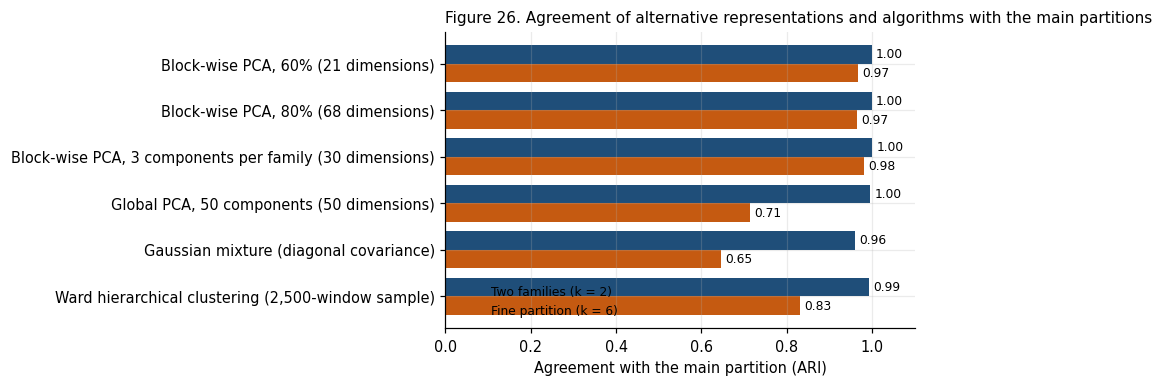

In [40]:
rob = []
for name, R in REPS.items():
    if name.endswith("(main)"):
        continue
    rob.append({"Comparison": f"Representation: {name} ({R.shape[1]} dimensions)",
                "k = 2": adjusted_rand_score(lab2, KMeans(2, n_init=10, random_state=SEED).fit_predict(R)),
                f"k = {K_FINE}": adjusted_rand_score(fine, KMeans(K_FINE, n_init=10, random_state=SEED).fit_predict(R))})
rob.append({"Comparison": "Algorithm: Gaussian mixture (diagonal covariance)",
            "k = 2": adjusted_rand_score(lab2, GMM[("diag", 2)].predict(Z)),
            f"k = {K_FINE}": adjusted_rand_score(fine, GMM[("diag", K_FINE)].predict(Z))})
idx_w = np.random.default_rng(SEED).choice(len(Z), 2500, replace=False)
ward = linkage(Z[idx_w], method="ward")
rob.append({"Comparison": "Algorithm: Ward hierarchical clustering (2,500-window sample)",
            "k = 2": adjusted_rand_score(lab2[idx_w], fcluster(ward, 2, "maxclust")),
            f"k = {K_FINE}": adjusted_rand_score(fine[idx_w], fcluster(ward, K_FINE, "maxclust"))})
rob = pd.DataFrame(rob).set_index("Comparison")
fig, ax = plt.subplots(figsize=(8.5, 3.6))
yy = np.arange(len(rob))
ax.barh(yy - 0.2, rob["k = 2"], 0.4, color=C_GLOBAL, label="Two families (k = 2)")
ax.barh(yy + 0.2, rob[f"k = {K_FINE}"], 0.4, color=C_LOCAL, label=f"Fine partition (k = {K_FINE})")
for i, (a2, a6) in enumerate(zip(rob["k = 2"], rob[f"k = {K_FINE}"])):
    ax.text(a2 + 0.01, i - 0.2, f"{a2:.2f}", va="center", fontsize=8); ax.text(a6 + 0.01, i + 0.2, f"{a6:.2f}", va="center", fontsize=8)
ax.set_yticks(yy, [c.replace("Representation: ", "").replace("Algorithm: ", "") for c in rob.index]); ax.invert_yaxis()
ax.set(xlim=(0, 1.1), xlabel="Agreement with the main partition (ARI)"); ax.legend(loc="lower left", fontsize=8)
fig_title(ax, "Agreement of alternative representations and algorithms with the main partitions")
plt.tight_layout(); plt.show()

**The two families are robust; the fine partition depends on how features are weighted and on the clustering assumption.**
* At **k = 2**, every alternative representation and both alternative algorithms reproduce the same partition (ARI 0.96–1.00).
* At **k = 6**, the alternative block-wise representations agree closely (ARI 0.97–0.98), which supports the choice of a 70% threshold.
* The fine partition changes under the global 50-component PCA (0.71), the Gaussian mixture (0.65) and, to a lesser degree, Ward's method (0.83).

### 9.4 Hierarchical and Density-Based Substructure

#### 9.4.1 Hierarchical Structure
Ward's dendrogram shows the height at which groups merge. If the structure is nested, further divisions should be as distinct as the first; if not, merge heights below the top should be similar to one another.

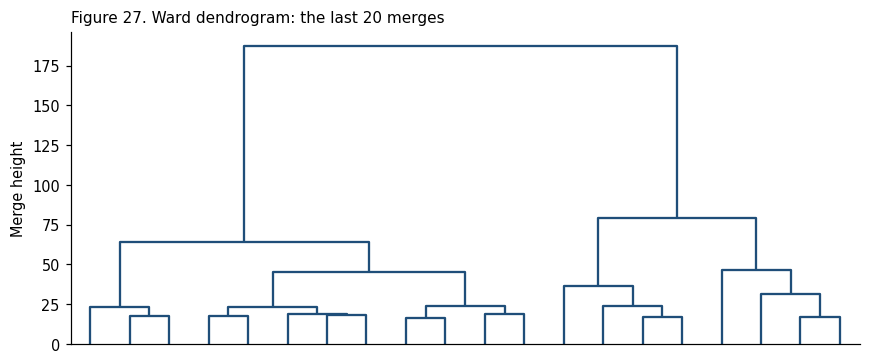

Ratio of each merge height to the next lower one, from the top: [2.37, 1.24, 1.37, 1.03, 1.25]


In [41]:
heights = ward[:, 2]
fig, ax = plt.subplots(figsize=(8, 3.4))
dendrogram(ward, truncate_mode="lastp", p=20, ax=ax, color_threshold=0, above_threshold_color=C_GLOBAL, no_labels=True)
ax.set(ylabel="Merge height"); ax.grid(False)
fig_title(ax, "Ward dendrogram: the last 20 merges")
plt.tight_layout(); plt.show()
print("Ratio of each merge height to the next lower one, from the top:", np.round(heights[-1:-6:-1] / heights[-2:-7:-1], 2).tolist())

**The hierarchy has one dominant division.** The final merge is 2.37 times the height of the one below it, whereas every lower ratio lies between 1.03 and 1.37. The division into two families is far more distinct than any division within them, and the lower levels of the hierarchy show no comparably clear divisions.

#### 9.4.2 Structure Within Each Family
K-Means is fitted separately within each family to test whether it contains well-separated sub-clusters.

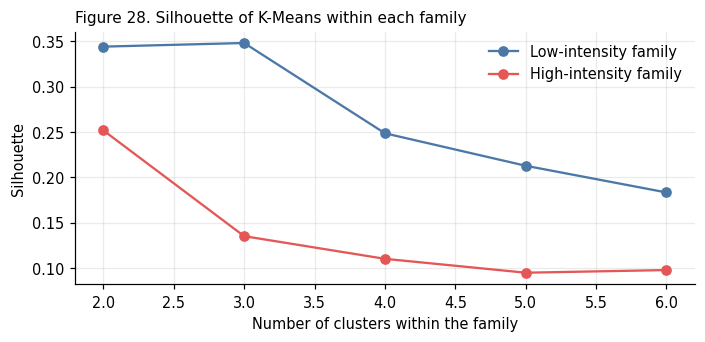

,Low-intensity family,High-intensity family
2,0.344,0.252
3,0.348,0.135
4,0.249,0.110
5,0.213,0.095
6,0.183,0.098


In [42]:
within_sil = pd.DataFrame({FAM_NAME[f]: {k: silhouette_score(Z[fam == f], KMeans(k, n_init=10, random_state=SEED).fit_predict(Z[fam == f]),
                                                    sample_size=3000, random_state=SEED) for k in range(2, 7)} for f in (0, 1)})
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for f, c in [(0, C_LOW), (1, C_HIGH)]:
    ax.plot(within_sil.index, within_sil[FAM_NAME[f]], marker="o", color=c, label=FAM_NAME[f])
ax.set(xlabel="Number of clusters within the family", ylabel="Silhouette"); ax.legend()
fig_title(ax, "Silhouette of K-Means within each family")
plt.tight_layout(); plt.show()
display(within_sil.round(3))

**The dynamic family has weak internal structure.**
* In the **low-intensity family**, the silhouette is highest at two or three clusters (0.34–0.35), indicating moderate substructure.
* In the **high-intensity family**, it falls from 0.25 at two clusters to 0.10–0.14 for three or more, so any division of dynamic movement into sub-clusters is weakly separated.

#### 9.4.3 Density-Based Structure
HDBSCAN is applied with a minimum cluster size of 50 and four values of its density parameter, `min_samples`. Windows in regions that are not dense enough are left unassigned.

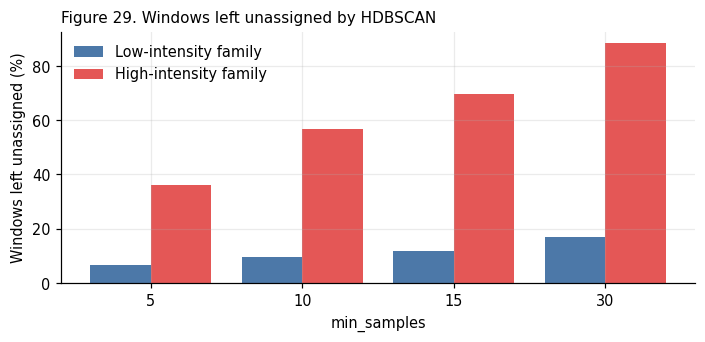

,Clusters,Unassigned,"Unassigned, low-intensity family","Unassigned, high-intensity family"
5,2,19.9%,6.7%,36.2%
10,2,30.7%,9.6%,56.7%
15,2,37.7%,11.8%,69.6%
30,2,48.8%,16.9%,88.3%


In [43]:
hdb_rows, HDB = {}, {}
for ms in [5, 10, 15, 30]:
    L = HDBSCAN(min_cluster_size=50, min_samples=ms).fit_predict(Z)
    HDB[ms] = L
    hdb_rows[ms] = {"Clusters": int(L.max() + 1), "Unassigned": (L < 0).mean(),
                    "Unassigned, low-intensity family": (L[fam == 0] < 0).mean(),
                    "Unassigned, high-intensity family": (L[fam == 1] < 0).mean()}
hd = pd.DataFrame(hdb_rows).T
fig, ax = plt.subplots(figsize=(6.5, 3.2))
x_ = np.arange(len(hd))
ax.bar(x_ - 0.2, hd["Unassigned, low-intensity family"] * 100, 0.4, color=C_LOW, label="Low-intensity family")
ax.bar(x_ + 0.2, hd["Unassigned, high-intensity family"] * 100, 0.4, color=C_HIGH, label="High-intensity family")
ax.set(xticks=x_, xticklabels=hd.index, xlabel="min_samples", ylabel="Windows left unassigned (%)"); ax.legend()
fig_title(ax, "Windows left unassigned by HDBSCAN")
plt.tight_layout(); plt.show()
display(hd.style.format({"Clusters": "{:.0f}", "Unassigned": "{:.1%}", "Unassigned, low-intensity family": "{:.1%}",
                         "Unassigned, high-intensity family": "{:.1%}"}))

**Density-based clustering finds only the two families, and leaves much of the dynamic family unassigned.** HDBSCAN finds exactly two clusters at every setting, but the share of unassigned windows grows from 20% to 49% as the density requirement increases. Almost all unassigned windows are in the high-intensity family:
* 36–88% of the high-intensity family is unassigned;
* only 7–17% of the low-intensity family is unassigned.

Under these HDBSCAN configurations, the dynamic family does not resolve into well-covered, high-density sub-clusters. This does not rule out meaningful structure at other scales or under different distance assumptions.

The solution with `min_samples = 15` is shown on the t-SNE projection.

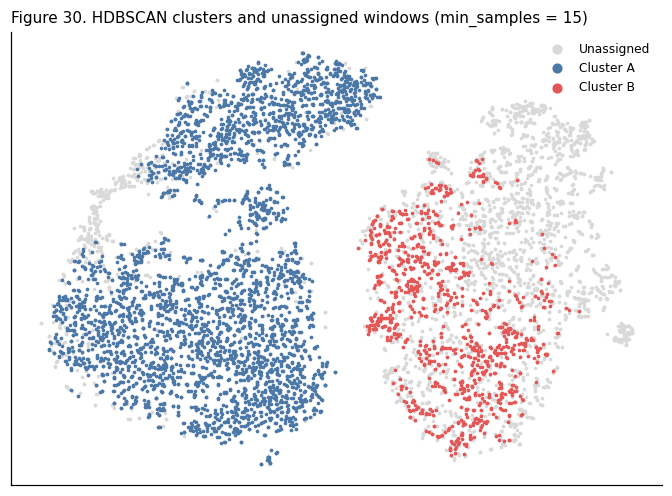

In [44]:
hdb_lab = np.where(HDB[15] < 0, "Unassigned", np.where(HDB[15] == np.bincount(HDB[15][HDB[15] >= 0]).argmax(), "Cluster A", "Cluster B"))
fig, ax = plt.subplots(figsize=(6.2, 4.6))
map_plot(ax, values=hdb_lab, colours={"Unassigned": "#D9D9D9", "Cluster A": C_LOW, "Cluster B": C_HIGH})
fig_title(ax, "HDBSCAN clusters and unassigned windows (min_samples = 15)")
plt.tight_layout(); plt.show()

**HDBSCAN keeps the dense core of the low-intensity family and only patches of the high-intensity family.** In the lower-intensity mass, almost all windows are assigned to one cluster, and unassigned windows appear only at its margins. In the higher-intensity mass, the assigned windows form scattered patches, and much of the mass, including most of its right-hand side, is left unassigned. Density-based clustering therefore treats much of the dynamic family as too sparse to form a cluster.

#### 9.4.4 Association with Participant Identity
If finer clusters increasingly describe individuals rather than movements, their association with participant identity should grow with k. Association is measured by adjusted mutual information (AMI), which is close to 0 for unrelated partitions.

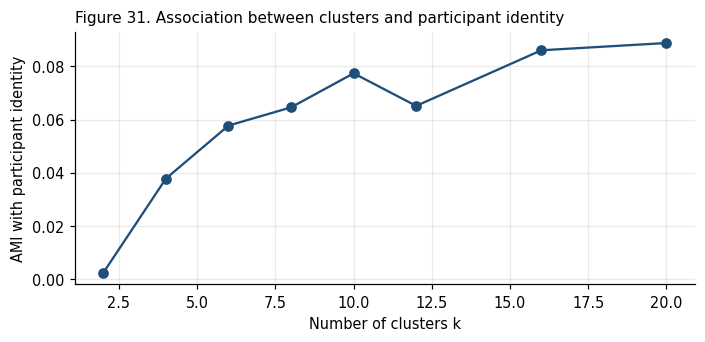

In [45]:
ks_ami = [2, 4, 6, 8, 10, 12, 16, 20]
ami_person = pd.Series({k: adjusted_mutual_info_score(subj, (KM[k].labels_ if k in KM else KMeans(k, n_init=4, random_state=SEED).fit_predict(Z)))
                        for k in ks_ami})
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(ami_person.index, ami_person.values, marker="o", color=C_GLOBAL)
ax.set(xlabel="Number of clusters k", ylabel="AMI with participant identity")
fig_title(ax, "Association between clusters and participant identity")
plt.tight_layout(); plt.show()

**Finer clusters are increasingly associated with individual participants.** The adjusted mutual information with participant identity rises steadily from 0.003 at k = 2 to 0.09 at k = 20. The association remains weak in absolute terms, but its steady growth shows that as the partition becomes finer, part of what it captures is the individual rather than the movement.

#### 9.4.5 Composition of the Fine Clusters
The fine clusters are named by family (L for low-intensity, H for high-intensity) and ordered by mean intensity. Clusters holding fewer than 5% of windows are marked with an asterisk.

In [46]:
order = sorted(range(K_FINE), key=lambda c: (round(fam[fine == c].mean()), intensity_axis[fine == c].mean()))
FINE_NAME, counters = {}, {0: 0, 1: 0}
for c in order:
    f_ = int(round(fam[fine == c].mean())); counters[f_] += 1
    FINE_NAME[c] = f"{'L' if f_ == 0 else 'H'}{counters[f_]}" + ("*" if (fine == c).mean() < 0.05 else "")
W["fine"] = [FINE_NAME[c] for c in fine]
fine_tab = pd.DataFrame({"Windows": W.fine.value_counts(),
                         "Share in one family": pd.crosstab(W.fine, W.family, normalize="index").max(axis=1),
                         "Participants": W.groupby("fine").subject.nunique(),
                         "Share from five largest contributors": W.groupby("fine").subject.agg(lambda s: s.value_counts().head(5).sum() / len(s)),
                         "Mean intensity (g)": W.groupby("fine").acc_rms.mean()})
display(fine_tab.sort_index().style.format({"Share in one family": "{:.1%}", "Share from five largest contributors": "{:.0%}",
                                            "Mean intensity (g)": "{:.3f}"}))

,Windows,Share in one family,Participants,Share from five largest contributors,Mean intensity (g)
fine,,,,,
H1,1458,99.5%,21,47%,0.320
H2,1505,100.0%,20,37%,0.391
H3*,326,100.0%,10,83%,0.455
L1,1349,100.0%,21,34%,0.015
L2,2485,100.0%,21,31%,0.018
L3*,229,97.4%,21,46%,0.166


**The fine partition is nested within the families and contains two rare clusters.** Every fine cluster lies within a single family (97–100% of its windows).
* **H3\*** (326 windows) has the highest intensity of any cluster. It is drawn from only 10 participants, and 83% of its windows come from five of them.
* **L3\*** (229 windows) lies in the low-intensity family but has about ten times the intensity of L1 and L2. It is drawn from all 21 participants.

The four larger clusters each include 20 or 21 participants.

The six fine clusters are shown on the t-SNE projection. The two rare clusters are drawn in strong colours.

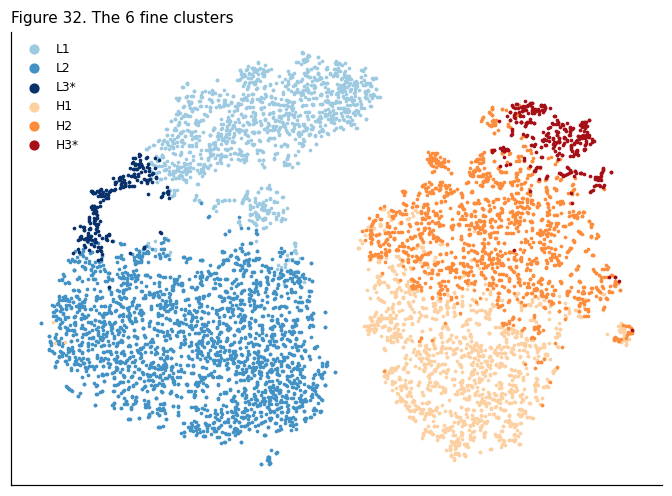

In [47]:
FINE_COL = {"L1": "#9ECAE1", "L2": "#4292C6", "L3*": "#08306B", "H1": "#FDD0A2", "H2": "#FD8D3C", "H3*": "#A50F15"}
fig, ax = plt.subplots(figsize=(6.2, 4.6))
map_plot(ax, values=W.fine.to_numpy(), colours=FINE_COL)
fig_title(ax, f"The {K_FINE} fine clusters")
plt.tight_layout(); plt.show()

**The fine clusters divide each mass into regions, and the rare clusters lie at the margins.** In the lower-intensity mass, L1 occupies the upper region and L2 the lower region, and L3\* lies at the left edge between them. In the higher-intensity mass, H2 occupies the upper region and H1 the lower region, and H3\* forms an outlying group at the top-right edge.

#### 9.4.6 Correspondence with Recorded Activities

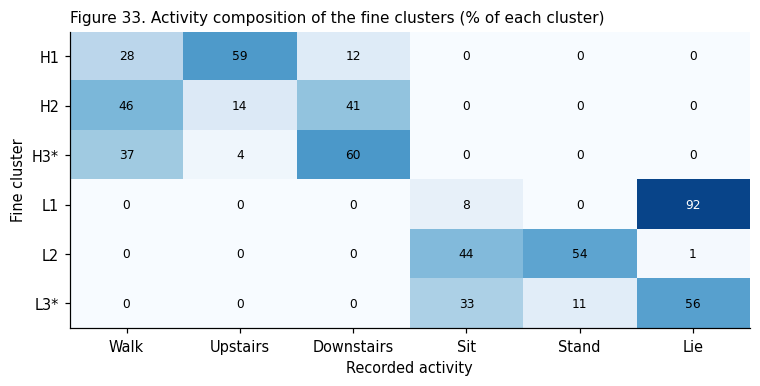

Agreement with the six activities: ARI = 0.501, AMI = 0.610; AMI with participant identity = 0.058


In [48]:
comp = pd.crosstab(W.fine, pd.Series(act, name="activity"), normalize="index").reindex(columns=ACT_ORDER, fill_value=0) * 100
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.imshow(comp.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(6), [ACT_SHORT[a_] for a_ in ACT_ORDER]); ax.set_yticks(range(len(comp)), comp.index)
for i in range(comp.shape[0]):
    for j in range(comp.shape[1]):
        ax.text(j, i, f"{comp.values[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if comp.values[i, j] > 60 else "black")
ax.grid(False); ax.set(xlabel="Recorded activity", ylabel="Fine cluster")
fig_title(ax, "Activity composition of the fine clusters (% of each cluster)")
plt.tight_layout(); plt.show()
print(f"Agreement with the six activities: ARI = {adjusted_rand_score(act, fine):.3f}, AMI = {adjusted_mutual_info_score(act, fine):.3f}; "
      f"AMI with participant identity = {adjusted_mutual_info_score(subj, fine):.3f}")

**The fine clusters do not reproduce the six activities.** Agreement with the activities is moderate (ARI 0.50, AMI 0.61).
* **L1** is almost entirely lying (92%).
* **L2** contains sitting and standing in almost equal proportions.
* **H1** is mostly upstairs walking, and **H2** combines walking with downstairs walking.
* **H3\*** is 60% downstairs and 37% walking.
* **L3\*** contains windows from all three static postures, most often lying.

L3\* is therefore not a posture of its own but a group of static windows that contain movement.

#### 9.4.7 Orientation Differences Between Sitting and Standing
Sitting and standing share a cluster. The gravity and angle feature that best separates them is identified, and its median value is compared for each participant.

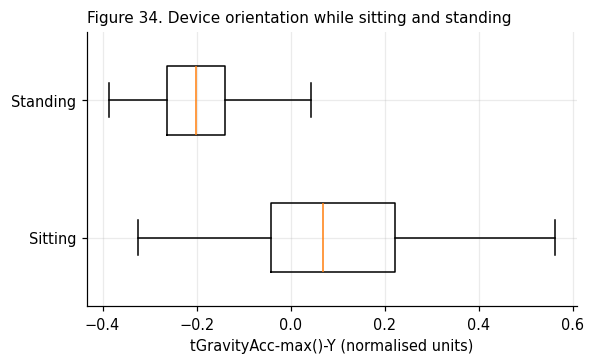

Strongest feature: tGravityAcc-max()-Y, Cohen's d = 2.04; same direction for 20 of 21 participants


In [49]:
static_ss = np.isin(act, ["SITTING", "STANDING"])
grav_feats = [c for c in X_dedup.columns if fam_dedup[c] in ("t:Gravity", "Angle")]
d_ss = {}
for c in grav_feats:
    a1, a2 = X_dedup.loc[act == "SITTING", c], X_dedup.loc[act == "STANDING", c]
    d_ss[c] = (a1.mean() - a2.mean()) / np.sqrt((a1.var() + a2.var()) / 2)
tilt_feat = max(d_ss, key=lambda c: abs(d_ss[c]))
pm = pd.DataFrame({"subject": subj, "act": act, "v": X_dedup[tilt_feat]})[static_ss].groupby(["subject", "act"]).v.median().unstack()
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.boxplot([X_dedup.loc[act == "SITTING", tilt_feat], X_dedup.loc[act == "STANDING", tilt_feat]],
           orientation="horizontal", showfliers=False, widths=0.5)
ax.set_yticks([1, 2], ["Sitting", "Standing"]); ax.set(xlabel=f"{tilt_feat} (normalised units)")
fig_title(ax, "Device orientation while sitting and standing")
plt.tight_layout(); plt.show()
print(f"Strongest feature: {tilt_feat}, Cohen's d = {d_ss[tilt_feat]:.2f}; same direction for "
      f"{(np.sign(pm['SITTING'] - pm['STANDING']) == np.sign(d_ss[tilt_feat])).sum()} of {len(pm)} participants")

**Sitting and standing differ clearly in device orientation, but their distributions overlap.** The strongest separating feature is `tGravityAcc-max()-Y` (|d| = 2.04), and the difference has the same direction for 20 of 21 participants.

The overlap arises because participants differ in their baseline orientation, so one person's sitting value can resemble another person's standing value. A partition based on overall similarity across participants therefore merges the two postures.

### 9.5 Physical Characterisation of the Clusters

#### 9.5.1 Distinguishing Feature Families
For each fine cluster, the standardised mean difference (Cohen's d) between the cluster and the other windows of its family is computed for every feature, and averaged in absolute value within each feature family.

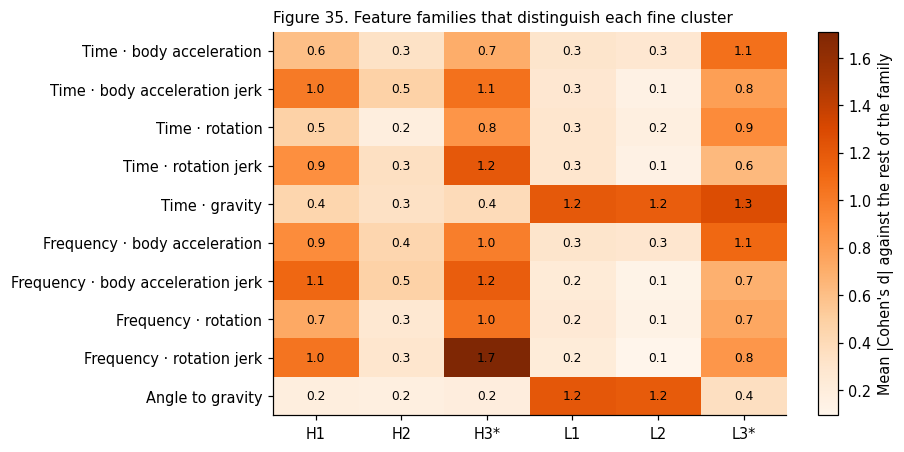

In [50]:
Sv = S.to_numpy()
dmat = {}
for c in sorted(FINE_NAME, key=lambda c: FINE_NAME[c]):
    m = fine == c
    rest = (fam == int(round(fam[m].mean()))) & ~m
    d = (Sv[m].mean(0) - Sv[rest].mean(0)) / np.sqrt((Sv[m].var(0) + Sv[rest].var(0)) / 2)
    dmat[FINE_NAME[c]] = pd.Series(np.abs(d), index=S.columns).groupby(fam_dedup).mean()
dmat = pd.DataFrame(dmat).reindex(FAMILIES).rename(index=FAMILY_LABEL)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
im = ax.imshow(dmat.values, cmap="Oranges", aspect="auto")
ax.set_xticks(range(dmat.shape[1]), dmat.columns); ax.set_yticks(range(dmat.shape[0]), dmat.index)
for i in range(dmat.shape[0]):
    for j in range(dmat.shape[1]):
        ax.text(j, i, f"{dmat.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im, ax=ax, label="Mean |Cohen's d| against the rest of the family")
fig_title(ax, "Feature families that distinguish each fine cluster")
plt.tight_layout(); plt.show()

**Each fine cluster is defined by a distinct set of physical properties.**
* **H3\*** differs from other dynamic windows mainly in the jerk families (mean |d| 1.1–1.7, largest for frequency-domain rotation jerk) and hardly at all in gravity or angle (0.2–0.4). It is distinguished by abrupt, vigorous movement, not by device orientation.
* **L1 and L2** are separated almost entirely by the gravity and angle families (|d| ≈ 1.2): they differ in orientation, not in movement.
* **L3\*** differs in both movement (|d| up to 1.1) and orientation (1.3), consistent with windows in which the body moves and the device changes orientation.
* **H1 and H2** differ more modestly, mainly in jerk.

#### 9.5.2 Raw-Signal Profiles
The raw-signal descriptors of Section 2.4 give the same comparison in physical units.

In [51]:
raw_profile = W.groupby("fine")[["acc_rms", "gyro_rms", "dom_freq", "tilt_change"]].median()
raw_profile.columns = ["Intensity (g)", "Rotation (rad/s)", "Dominant frequency (Hz)", "Tilt change (°)"]
display(raw_profile.round(3))

,Intensity (g),Rotation (rad/s),Dominant frequency (Hz),Tilt change (°)
fine,,,,
H1,0.314,0.786,1.953,1.456
H2,0.389,0.864,3.516,1.229
H3*,0.447,1.198,1.953,1.509
L1,0.012,0.027,0.781,0.325
L2,0.012,0.029,0.391,0.444
L3*,0.136,0.291,0.391,11.569


**The raw signals confirm these differences in physical units.**
* H3\* has the highest intensity and rotation of any cluster (0.45 g and 1.20 rad/s).
* H1 and H2 differ clearly in dominant frequency (1.95 Hz against 3.52 Hz), which suggests different stepping patterns.
* L1 and L2 have almost no movement (0.012 g) and almost no change in estimated gravity direction (0.3–0.4°). L3\* has about ten times their intensity (0.14 g) and a median gravity-direction change of 11.6°, roughly thirty times theirs. This is consistent with windows in which the phone's orientation shifts within a nominally static recording.

### 9.6 Summary
Human movement in this dataset organises into **two broad families**, low-intensity (static) and high-intensity (dynamic) movement, rather than into six distinct categories.

* **The two families are robust.** They are preferred by every validity index, reproduced exactly on withheld participants, unchanged across representations and algorithms, and correspond to the static/dynamic distinction for 99.8% of windows.
* **Structure below the families is weaker and nested.** The hierarchy has one dominant division, the dynamic family has little internal separation, and density-based clustering finds no compact sub-clusters within it.
* **A six-cluster partition is reproducible but method-dependent.** It is reproduced across participants (median ARI 0.96), but changes with the representation and the algorithm (ARI 0.65–0.83).
* **The fine clusters describe physical properties, not activities.** They separate orientation within static movement and intensity within dynamic movement (ARI with the activities 0.50).
* **Two clusters are small and specialised.** H3\* is a vigorous cluster drawn mainly from five participants, and L3\* is a cluster of static windows that contain movement.

Movement is therefore organised into broad families containing overlapping, more specialised patterns, some of which are partly specific to individuals.

## 10. RQ2: Movement Variability and Apparent Unusualness
A distance-based detector will, almost by construction, give high scores to windows in sparse, widely spread regions. The question is therefore not whether variable clusters are flagged more often by such a detector. It is whether that over-representation is a property of the movements, or of the reference used to judge them.

Five detectors are compared, all applied to the shared representation:
* three with a **global** reference: the k-NN distance, Isolation Forest (Liu et al., 2008), and the negative log-likelihood of a Gaussian mixture;
* two with a **local** reference: the Local Outlier Factor (LOF; Breunig et al., 2000), and the distance to the window's own cluster centre divided by that cluster's median distance (the **relative centroid distance**).

### 10.1 Cluster Dispersion and the Detector's Reference Population

#### 10.1.1 Dispersion of the Fine Clusters
Dispersion is measured as the mean squared distance of a cluster's windows from its centre.

In [52]:
centres = KM[K_FINE].cluster_centers_
own_d = np.linalg.norm(Z - centres[fine], axis=1)
dispersion = pd.Series(own_d**2).groupby(W.fine).mean()
order_c = dispersion.sort_values().index.tolist()
display(pd.DataFrame({"Windows": W.fine.value_counts(), "Dispersion": dispersion}).reindex(order_c).round(2))

,Windows,Dispersion
fine,,
L1,1349,3.62
L2,2485,3.67
H1,1458,5.40
H2,1505,6.37
L3*,229,11.67
H3*,326,12.61


**The two rare clusters are the most widely spread.** L3\* and H3\* have dispersions of 11.7 and 12.6, about two to three times those of the other clusters (3.6–6.4). The static clusters L1 and L2 are the most compact.

#### 10.1.2 Over-Representation by Detector
For each detector, a cluster's **over-representation** is its share of flagged windows divided by its share of all windows; a value of 1 is proportional. The 95% intervals come from resampling participants with replacement.

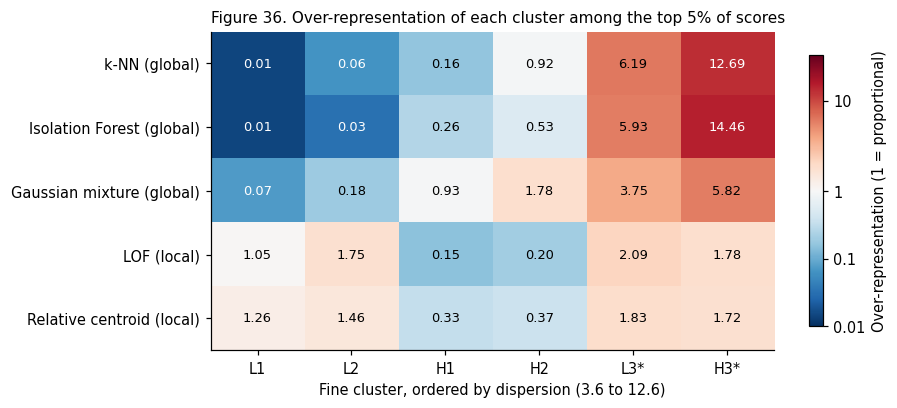

In [53]:
rel_centroid = own_d / pd.Series(own_d).groupby(fine).median().reindex(fine).to_numpy()
gmm_fine = GaussianMixture(K_FINE, covariance_type="full", reg_covar=1e-4, n_init=2, random_state=SEED).fit(Z)
SCORES = {"k-NN distance": knn_dist,
          "Isolation Forest": -IsolationForest(n_estimators=300, random_state=SEED).fit(Z).score_samples(Z),
          "Gaussian mixture likelihood": -gmm_fine.score_samples(Z),
          "Local Outlier Factor": -LocalOutlierFactor(n_neighbors=20).fit(Z).negative_outlier_factor_,
          "Relative centroid distance": rel_centroid}
GLOBAL_DET = ["k-NN distance", "Isolation Forest", "Gaussian mixture likelihood"]
FLAGS = {k: top_flags(v) for k, v in SCORES.items()}

def boot_ratio(flags, groups, n_boot=N_BOOT, seed=SEED):
    """Over-representation with participant-level bootstrap 95% intervals."""
    d = pd.DataFrame({"s": subj, "g": groups, "f": np.asarray(flags, int)})
    n = d.pivot_table(index="s", columns="g", values="f", aggfunc="size", fill_value=0)
    k = d.pivot_table(index="s", columns="g", values="f", aggfunc="sum", fill_value=0)
    point = (k.sum() / n.sum()) / (k.values.sum() / n.values.sum())
    r = np.random.default_rng(seed); B = []
    for _ in range(n_boot):
        s = r.choice(n.index, len(n.index), replace=True)
        kn, nn = k.loc[s].sum(), n.loc[s].sum()
        B.append((kn / nn) / (kn.sum() / nn.sum()))
    B = pd.DataFrame(B)
    return pd.DataFrame({"ratio": point, "lo": B.quantile(0.025), "hi": B.quantile(0.975)})

OVER = {det: boot_ratio(FLAGS[det], W.fine.to_numpy()).reindex(order_c) for det in SCORES}
DET_SHORT = {"k-NN distance": "k-NN (global)", "Isolation Forest": "Isolation Forest (global)",
             "Gaussian mixture likelihood": "Gaussian mixture (global)", "Local Outlier Factor": "LOF (local)",
             "Relative centroid distance": "Relative centroid (local)"}
over_tab = pd.concat({DET_SHORT[det]: OVER[det].ratio for det in SCORES}, axis=1).T
over_tab.columns = order_c
heatmap(over_tab, "Over-representation of each cluster among the top 5% of scores", fmt="{:.2f}", ratio=True,
        xlabel=f"Fine cluster, ordered by dispersion ({dispersion.min():.1f} to {dispersion.max():.1f})",
        cbar_label="Over-representation (1 = proportional)", figsize=(8.5, 3.8))

**Global detectors over-represent the widely spread clusters; local detectors do so much less.**
* Under the **global** detectors, L3\* receives 3.8–6.2 times its proportional share of flags and H3\* 5.8–14.5 times, while the compact clusters L1 and L2 are almost never flagged (at most 0.2 times).
* Under the **local** detectors, the rare clusters are still over-represented, but far less (1.7–2.1 times), and the static clusters receive a proportional or greater share (1.05–1.75 times).

#### 10.1.3 Relationship Between Dispersion and Over-Representation

In [54]:
rho = pd.Series({det: spearmanr(dispersion.reindex(order_c), OVER[det].ratio)[0] for det in SCORES},
                name="Spearman correlation: dispersion vs over-representation")
display(rho.to_frame().round(2))

,Spearman correlation: dispersion vs over-representation
k-NN distance,1.00
Isolation Forest,1.00
Gaussian mixture likelihood,1.00
Local Outlier Factor,0.49
Relative centroid distance,0.49


**For global detectors, over-representation follows dispersion exactly.** Across the six clusters, the rank correlation between dispersion and over-representation is 1.00 for all three global detectors, but only 0.49 for the two local detectors.

#### 10.1.4 Agreement Between Detectors

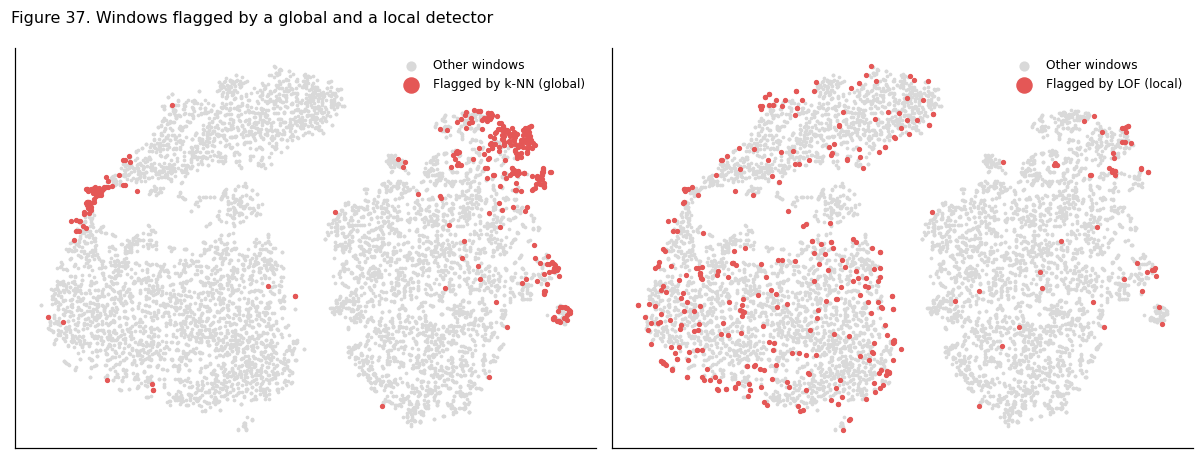

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
map_plot(ax[0], highlight=FLAGS["k-NN distance"], title="Flagged by k-NN (global)")
map_plot(ax[1], highlight=FLAGS["Local Outlier Factor"], title="Flagged by LOF (local)")
fig_title(fig, "Windows flagged by a global and a local detector")
plt.tight_layout(); plt.show()

**The two kinds of detector flag different regions.**
* The **global** k-NN detector flags windows at the periphery of the higher-intensity mass, and one compact group at the edge of the lower-intensity mass (the L3\* region).
* The **local** LOF detector flags windows scattered throughout the lower-intensity mass, including its dense interior, and comparatively few in the higher-intensity mass.

A local detector flags a window whenever it is sparse relative to its own neighbourhood, even inside a compact region; a global detector flags only windows that are far from everything.

The overlap between the shortlists of all five detectors is measured by the Jaccard index (1 = identical shortlists).

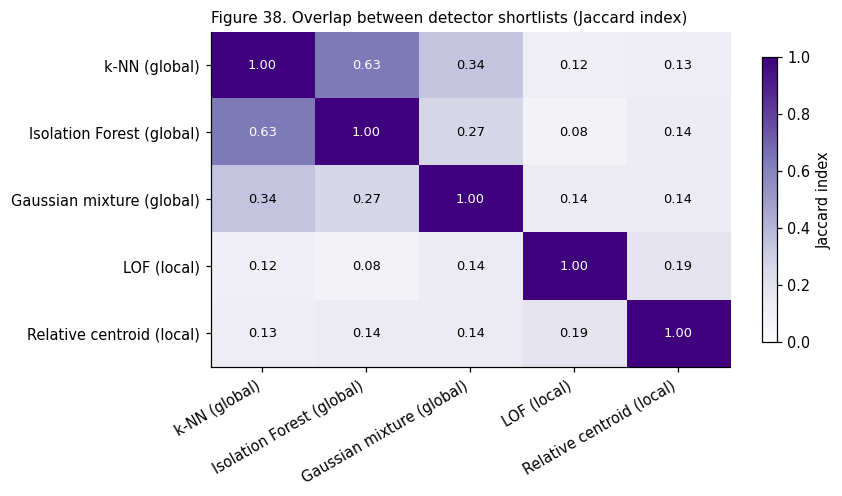

In [56]:
jac = pd.DataFrame({DET_SHORT[a]: {DET_SHORT[b]: jaccard(FLAGS[a], FLAGS[b]) for b in SCORES} for a in SCORES})
heatmap(jac, "Overlap between detector shortlists (Jaccard index)", fmt="{:.2f}", vmin=0, vmax=1, cmap="Purples",
        cbar_label="Jaccard index", figsize=(8, 4.6))

**Global and local detectors identify largely different windows.** The three global detectors agree with one another only partly (Jaccard 0.27–0.63), and the two local detectors agree with each other even less (0.19). Agreement between global and local detectors is very low (0.08–0.14).

#### 10.1.5 Correspondence with Recorded Activities
The same comparison by activity, with 95% participant-bootstrap intervals.

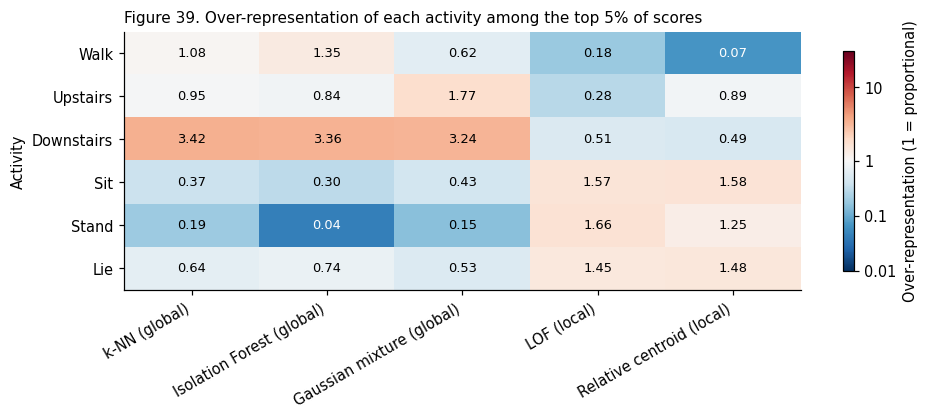

Walking downstairs, k-NN (global): 3.42 (95% interval 2.44–3.96)
Walking downstairs, LOF (local): 0.51 (95% interval 0.13–1.02)


In [57]:
OVER_ACT = {det: boot_ratio(FLAGS[det], act).reindex(ACT_ORDER) for det in SCORES}
heatmap(pd.DataFrame({DET_SHORT[d]: OVER_ACT[d].ratio for d in SCORES}).rename(index=ACT_SHORT),
        "Over-representation of each activity among the top 5% of scores", fmt="{:.2f}", ratio=True,
        ylabel="Activity", cbar_label="Over-representation (1 = proportional)", figsize=(9, 3.9))
for d in ["k-NN distance", "Local Outlier Factor"]:
    r__ = OVER_ACT[d].loc["WALKING_DOWNSTAIRS"]
    print(f"Walking downstairs, {DET_SHORT[d]}: {r__.ratio:.2f} (95% interval {r__.lo:.2f}–{r__.hi:.2f})")

**Whether walking downstairs appears unusual depends on the reference.**
* Under the global detectors, walking downstairs receives 3.2–3.4 times its proportional share, with intervals well above 1.
* Under the local detectors, it receives only about half its share (0.49–0.51).
* The static postures show the reverse pattern: under-represented by the global detectors and over-represented by the local ones (1.25–1.66).

### 10.2 Sensitivity Analysis
The over-representation of the two rare clusters is recomputed for one global detector (k-NN) and one local detector (LOF), varying the neighbourhood size, the shortlist proportion and the representation. Cluster membership is held fixed, so only the detector setting changes.

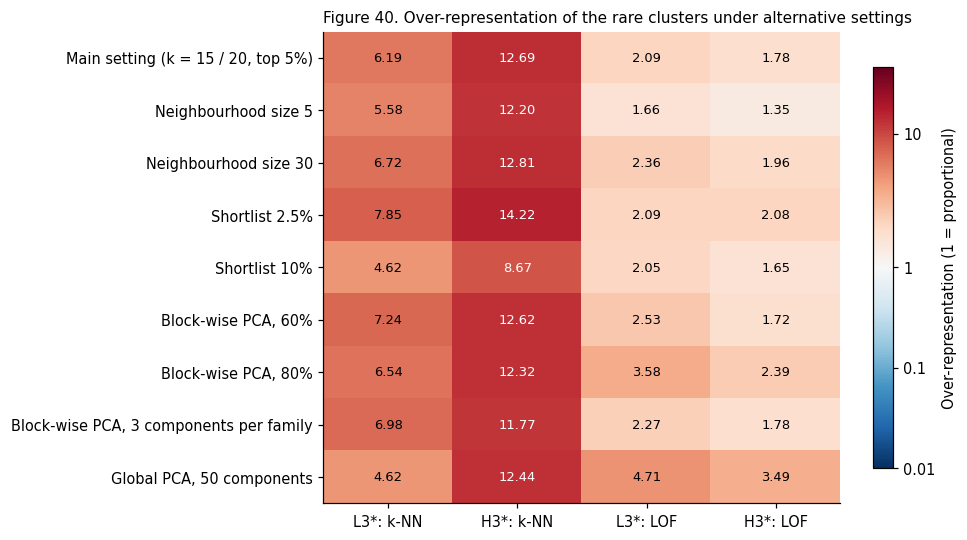

In [58]:
RARE = [n for n in FINE_NAME.values() if n.endswith("*")]
def over(flags, name):
    m = (W.fine == name).to_numpy(); f = np.asarray(flags)
    return f[m].mean() / f.mean()
def knn_score(R, k=K_NN):
    return NearestNeighbors(n_neighbors=k + 1).fit(R).kneighbors(R)[0][:, k]
def lof_score(R, k=20):
    return -LocalOutlierFactor(n_neighbors=k).fit(R).negative_outlier_factor_
rows = []
for label, sk_, sl_, q in [("Main setting (k = 15 / 20, top 5%)", knn_score(Z), lof_score(Z), TOP),
                           ("Neighbourhood size 5", knn_score(Z, 5), lof_score(Z, 5), TOP),
                           ("Neighbourhood size 30", knn_score(Z, 30), lof_score(Z, 30), TOP),
                           ("Shortlist 2.5%", knn_dist, SCORES["Local Outlier Factor"], 0.025),
                           ("Shortlist 10%", knn_dist, SCORES["Local Outlier Factor"], 0.10)]:
    rows.append({"Setting": label, **{f"{n}: k-NN": over(top_flags(sk_, q), n) for n in RARE},
                 **{f"{n}: LOF": over(top_flags(sl_, q), n) for n in RARE}})
for name, R in REPS.items():
    if name.endswith("(main)"):
        continue
    sk_, sl_ = knn_score(R), lof_score(R)
    rows.append({"Setting": f"Representation: {name}", **{f"{n}: k-NN": over(top_flags(sk_), n) for n in RARE},
                 **{f"{n}: LOF": over(top_flags(sl_), n) for n in RARE}})
sens = pd.DataFrame(rows).set_index("Setting")
sens.index = [i.replace("Representation: ", "") for i in sens.index]
heatmap(sens, "Over-representation of the rare clusters under alternative settings", fmt="{:.2f}", ratio=True,
        cbar_label="Over-representation (1 = proportional)", figsize=(9, 5))

**The global result is robust; the local result is consistently much weaker.**
* Under **k-NN**, H3\* is over-represented 8.7–14.2 times and L3\* 4.6–7.9 times in every setting.
* Under **LOF** with the block-wise representations, the over-representation is much smaller (1.4–2.4 for H3\*, 1.7–3.6 for L3\*), but remains above 1.
* LOF's over-representation is largest under the global 50-component PCA (3.5 and 4.7), whose unequal family weighting lets intensity dominate local densities as well.

### 10.3 Spread Equalisation and Reference Resolution

#### 10.3.1 Equalising Within-Cluster Spread
If spread explains the over-representation, removing differences in spread should remove it. Each fine cluster is rescaled about its own centre so that all clusters have the same total spread, and the two global detectors are applied again.

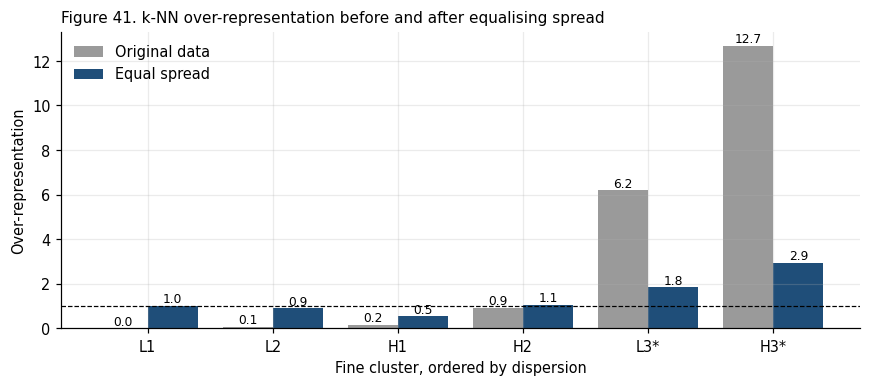

Isolation Forest, L3*: 5.9 before, 2.3 after equalisation
Isolation Forest, H3*: 14.5 before, 10.4 after equalisation
Flags retained after equalisation (k-NN): 159 of 368 (43%); 84% of them in the high-intensity family


In [59]:
def equalise(R, groups):
    Re = R.copy(); tr = {g: R[groups == g].var(0).sum() for g in np.unique(groups)}; t = np.mean(list(tr.values()))
    for g in tr:
        m = groups == g; mu = R[m].mean(0); Re[m] = mu + (R[m] - mu) * np.sqrt(t / tr[g])
    return Re
Z_eq = equalise(Z, fine)
flag_eq = {"k-NN distance": top_flags(knn_score(Z_eq)),
           "Isolation Forest": top_flags(-IsolationForest(n_estimators=300, random_state=SEED).fit(Z_eq).score_samples(Z_eq))}
eq_tab = pd.DataFrame({f"{det}: {when}": [over(f, n) for n in order_c] for det in flag_eq
                       for when, f in [("original", FLAGS[det]), ("equal spread", flag_eq[det])]}, index=order_c)
W["survives_eq"] = W.flag.to_numpy() & flag_eq["k-NN distance"]
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(order_c))
b1 = ax.bar(x - 0.2, eq_tab["k-NN distance: original"], 0.4, color=C_GREY, label="Original data")
b2 = ax.bar(x + 0.2, eq_tab["k-NN distance: equal spread"], 0.4, color=C_GLOBAL, label="Equal spread")
ax.bar_label(b1, fmt="%.1f", fontsize=8); ax.bar_label(b2, fmt="%.1f", fontsize=8)
ax.axhline(1, color="black", ls="--", lw=0.8)
ax.set(xticks=x, xticklabels=order_c, xlabel="Fine cluster, ordered by dispersion", ylabel="Over-representation")
ax.legend()
fig_title(ax, "k-NN over-representation before and after equalising spread")
plt.tight_layout(); plt.show()
for n in RARE:
    print(f"Isolation Forest, {n}: {eq_tab.loc[n, 'Isolation Forest: original']:.1f} before, "
          f"{eq_tab.loc[n, 'Isolation Forest: equal spread']:.1f} after equalisation")
print(f"Flags retained after equalisation (k-NN): {W.survives_eq.sum()} of {W.flag.sum()} ({W.survives_eq.sum() / W.flag.sum():.0%}); "
      f"{(W[W.survives_eq].family == 1).mean():.0%} of them in the high-intensity family")

**Equalising spread substantially reduces k-NN over-representation under this transformation.** For the k-NN detector:
* H3\* falls from 12.7 to 2.9 times its proportional share;
* L3\* falls from 6.2 to 1.8 times.

This removes 83–84% of their excess, so for distance-based detection, spread explains most of the effect.

**Isolation Forest responds less.** Its excess for L3\* falls by 74%, but for H3\* by only 30% (14.5 to 10.4). Isolation depends on the values of individual axes as well as overall spread, and H3\* windows are extreme on the intensity axes themselves.

Of the 368 flags, 159 (43%) remain after equalisation, 84% of them in the high-intensity family. These windows are unusual for reasons other than belonging to a widely spread cluster.

#### 10.3.2 Dependence on the Reference Resolution
The number of reference clusters is varied from 2 to 8. Two scores are compared: the distance to the nearest cluster centre (a global reference) and the same distance divided by the cluster's median distance (a local reference). The windows of the two rare clusters are tracked throughout.

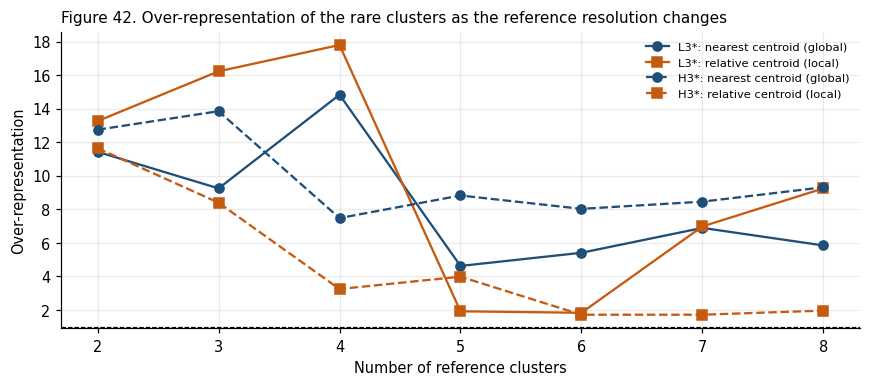

In [60]:
res_rows = []
for k in range(2, 9):
    L = KM[k].labels_; d_ = KM[k].transform(Z)[np.arange(len(Z)), L]
    rel = d_ / pd.Series(d_).groupby(L).median().reindex(L).to_numpy()
    for n in RARE:
        res_rows.append({"k": k, "cluster": n, "Nearest centroid (global)": over(top_flags(d_), n),
                         "Relative centroid (local)": over(top_flags(rel), n)})
res_df = pd.DataFrame(res_rows)
fig, ax = plt.subplots(figsize=(8, 3.6))
for n, ls in zip(RARE, ["-", "--"]):
    s_ = res_df[res_df.cluster == n]
    ax.plot(s_.k, s_["Nearest centroid (global)"], ls=ls, marker="o", color=C_GLOBAL, label=f"{n}: nearest centroid (global)")
    ax.plot(s_.k, s_["Relative centroid (local)"], ls=ls, marker="s", color=C_LOCAL, label=f"{n}: relative centroid (local)")
ax.axhline(1, color="black", ls="--", lw=0.8)
ax.set(xlabel="Number of reference clusters", ylabel="Over-representation"); ax.legend(fontsize=7.5)
fig_title(ax, "Over-representation of the rare clusters as the reference resolution changes")
plt.tight_layout(); plt.show()

### 10.4 Location and Physical Character of Flagged Windows

#### 10.4.1 Distance from the Own Cluster Centre
A flagged window may be far from its own cluster centre because it lies towards another cluster or because it lies at the outer edge of its own. As a descriptive measure, each window's distance from its own centre is divided by the distance between its own centre and the nearest other centre. Larger values mean that a window is farther from its centre relative to how far apart the clusters are. In 40 dimensions the ratio cannot by itself show on which side of a cluster boundary a window lies.

In [61]:
second = np.argsort(KM[K_FINE].transform(Z), axis=1)[:, 1]
beyond = own_d / np.linalg.norm(centres[fine] - centres[second], axis=1)
geom = pd.DataFrame({det: {"Flagged": np.median(beyond[FLAGS[det]]), "Not flagged": np.median(beyond[~FLAGS[det]])}
                     for det in SCORES}).T
display(geom.round(2).rename_axis("Median distance ratio"))

,Flagged,Not flagged
Median distance ratio,,
k-NN distance,0.93,0.66
Isolation Forest,0.89,0.67
Gaussian mixture likelihood,1.12,0.66
Local Outlier Factor,0.74,0.67
Relative centroid distance,0.79,0.67


**Globally flagged windows have larger centroid-distance ratios.** For global detectors, the median ratio of distance to the assigned centroid divided by the separation to the nearest alternative centroid is 0.89–1.12, compared with 0.66 for unflagged windows. This shows that flagged windows tend to be farther from their own centroid **relative to the scale of the centroid separation**.

It does **not** establish whether a window lies *between* clusters or *beyond* them. A ratio above 0.5 is not a geometrically valid test of which side of a cluster boundary a point lies in multidimensional space. We therefore use this statistic descriptively rather than as a positional classification.

#### 10.4.2 Raw-Signal Profiles of Flagged Windows
Flagged and unflagged windows of the same cluster are compared using raw-signal descriptors.

In [62]:
prof = W.assign(flagged=W.flag.map({True: "flagged", False: "not flagged"})).groupby(["fine", "flagged"])[
    ["acc_rms", "gyro_rms", "tilt_change"]].median().unstack()
DESC_NAME = {"acc_rms": "Intensity (g)", "gyro_rms": "Rotation (rad/s)", "tilt_change": "Estimated gravity-direction change (°)"}
prof.columns = [f"{DESC_NAME[a]}, {b}" for a, b in prof.columns]
display(prof.round(3))

,"Intensity (g), flagged","Intensity (g), not flagged","Rotation (rad/s), flagged","Rotation (rad/s), not flagged","Estimated gravity-direction change (°), flagged","Estimated gravity-direction change (°), not flagged"
fine,,,,,,
H1,0.387,0.313,1.448,0.784,3.203,1.448
H2,0.437,0.383,1.070,0.860,2.173,1.203
H3*,0.479,0.388,1.272,1.057,1.850,1.168
L1,0.022,0.012,0.090,0.027,1.111,0.325
L2,0.033,0.012,0.090,0.029,0.602,0.444
L3*,0.262,0.107,0.391,0.268,24.629,8.614


**Flagged windows contain more movement and more orientation change than other windows of the same cluster.** In every fine cluster, flagged windows have higher median intensity, rotation and estimated gravity-direction change.
* In the static clusters **L1 and L2**, flagged windows have about twice the intensity (0.022–0.033 g against 0.012 g) and three times the rotation (0.090 against 0.027–0.029 rad/s).
* In **L3\***, flagged windows have by far the largest gravity-direction change (median 24.6°, against 8.6° for unflagged L3\* windows and under 1.5° for unflagged windows of every other cluster).
* In the dynamic clusters, flagged windows are 14–24% more intense and rotate more; their gravity-direction change roughly doubles but stays small (1.9–3.2°).

These descriptive comparisons do not identify physical transitions or sensor faults.

In [63]:
display((W.pivot_table(index="family", columns="position", values="flag", aggfunc="mean")[["start", "interior", "end"]]
         .rename(index=FAM_NAME) * 100).round(1).rename_axis("Windows flagged (%)"))

position,start,interior,end
Windows flagged (%),,,
Low-intensity family,8.2,1.0,0.4
High-intensity family,10.7,7.7,10.4


**The pattern of Section 7.3 holds for the families.** In the low-intensity family, flags are concentrated at the start of episodes (8.2%, against 1.0% in the interior and 0.4% at the end). In the high-intensity family, the effect of position is weak (7.7–10.7%).

### 10.5 Summary
Some forms of movement are more variable than others, and for distance-based detectors this variability largely explains why they appear unusual.

* **Variability differs.** The two rare clusters have two to three times the spread of the others, and the activity most affected is walking downstairs.
* **Spread explains the global over-representation.** For global detectors, the ranking of clusters by spread matches their ranking by over-representation exactly, and equalising spread removes about 84% of the k-NN excess.
* **The effect depends on the reference.** Local detectors do not over-represent walking downstairs, and the over-representation of the variable clusters falls sharply once they are judged against a reference cluster of their own.
* **The effect depends on the detector.** Equalising spread removes only 30% of the Isolation Forest excess for H3\*.
* **Flagged windows are far from their own centre and contain more movement.** Relative to the separation between cluster centres, they lie farther from their own centre than unflagged windows (Section 10.4.1, which does not establish whether they lie between or beyond clusters), and they contain more movement than other windows of the same cluster.

The 43% of flags that survive equalisation are examined in RQ3.

## 11. RQ3: Individual Consistency Versus Isolated Departure
The two explanations make different predictions:
* **Consistent individual differences** imply that much of the variation in the anomaly score lies between participants, that a participant's flag rate is reproducible across independent episodes, and that a flagged window's nearest neighbours from *other* episodes tend to belong to the same participant.
* **Isolated departures** imply that variation is concentrated in single windows and associated with transient events such as transitions.

### 11.1 Decomposition of Anomaly-Score Variance
Within each family, the variance of the log k-NN score is divided into three components: between participants, between episodes of the same participant, and between windows of the same episode. Only alternate windows are used, so that overlapping windows do not inflate the episode component. A permutation baseline reassigns whole episodes to random participants within the family, 200 times.

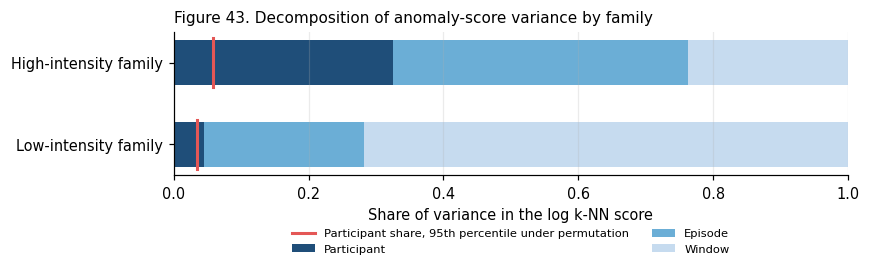

,Participant,Episode,Window,Permutation median,Permutation 95th percentile
Low-intensity family,0.044,0.238,0.718,0.023,0.035
High-intensity family,0.325,0.438,0.237,0.038,0.058


In [64]:
def decompose(y, person, episode):
    d = pd.DataFrame({"y": y, "p": person, "e": episode}); m = d.y.mean(); tot = ((d.y - m)**2).sum()
    pm_ = d.groupby("p").y.transform("mean"); em = d.groupby("e").y.transform("mean")
    return {"Participant": ((pm_ - m)**2).sum() / tot, "Episode": ((em - pm_)**2).sum() / tot, "Window": ((d.y - em)**2).sum() / tot}

def episode_permutation(frame, rng):
    eps = frame.episode.unique(); owner = frame.groupby("episode").subject.first().loc[eps].to_numpy()
    return frame.episode.map(dict(zip(eps, rng.permutation(owner)))).to_numpy()

alt = W.pos % 2 == 0
dec_rows, null_rows = {}, {}
r_ = np.random.default_rng(SEED)
for f in (0, 1):
    g = W[alt & (W.family == f)]
    y_ = np.log(g.score_knn.to_numpy())
    dec_rows[FAM_NAME[f]] = decompose(y_, g.subject.to_numpy(), g.episode.to_numpy())
    null_rows[FAM_NAME[f]] = np.percentile([decompose(y_, episode_permutation(g, r_), g.episode.to_numpy())["Participant"]
                                            for _ in range(N_NULL)], [50, 95])
dec = pd.DataFrame(dec_rows).T
fig, ax = plt.subplots(figsize=(8, 2.8))
left = np.zeros(2)
for comp_, c in zip(dec.columns, [C_GLOBAL, "#6BAED6", "#C6DBEF"]):
    ax.barh(dec.index, dec[comp_], left=left, color=c, label=comp_, height=0.55); left += dec[comp_].to_numpy()
for i, f in enumerate(dec.index):
    ax.plot([null_rows[f][1]] * 2, [i - 0.3, i + 0.3], color=C_HIGH, lw=2)
ax.plot([], [], color=C_HIGH, lw=2, label="Participant share, 95th percentile under permutation")
ax.set(xlim=(0, 1), xlabel="Share of variance in the log k-NN score"); ax.grid(axis="y", visible=False)
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2)
fig_title(ax, "Decomposition of anomaly-score variance by family")
plt.tight_layout(); plt.show()
display(dec.assign(**{"Permutation median": [null_rows[f][0] for f in dec.index],
                      "Permutation 95th percentile": [null_rows[f][1] for f in dec.index]}).round(3))

**The two families differ sharply in where unusualness lies.**
* In the **high-intensity family**, 32.5% of the variance lies between participants, against 3.8% under permutation (95th percentile 5.8%). A further 43.8% lies between episodes of the same participant, and only 23.7% between windows of the same episode.
* In the **low-intensity family**, the participant share is only 4.4%, barely above its permutation 95th percentile of 3.5%, and 71.8% of the variance lies between individual windows.

Unusualness in dynamic movement is therefore largely a property of participants and episodes, whereas unusualness in static postures is largely a property of individual windows.

### 11.2 Reliability Across Recording Episodes
Each participant's flag rate in the high-intensity family is computed separately on their odd- and even-numbered episodes. A high correlation means that the participant's unusualness is reproduced in independent recordings.

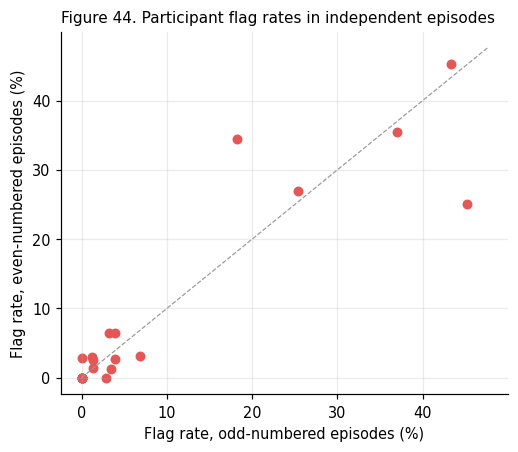

Split-half correlation: r = 0.92, 95% participant-bootstrap interval [0.81, 0.99]


In [65]:
def split_half(flags, family=None):
    d = W.assign(f=np.asarray(flags))
    if family is not None:
        d = d[d.family == family]
    d["half"] = d.groupby("subject").episode.rank(method="dense").astype(int) % 2
    t = d.groupby(["subject", "half"]).f.mean().unstack().dropna()
    return t, pearsonr(t[0], t[1])[0]
sh_table, r_split = split_half(W.flag, family=1)
boot_r = [pearsonr(*sh_table.loc[np.random.default_rng(b).choice(sh_table.index, len(sh_table))].T.values)[0] for b in range(N_BOOT)]
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.scatter(sh_table[1] * 100, sh_table[0] * 100, color=C_HIGH, s=30)
lim = max(sh_table.values.max() * 100, 5) * 1.05
ax.plot([0, lim], [0, lim], color=C_GREY, ls="--", lw=0.8)
ax.set(xlabel="Flag rate, odd-numbered episodes (%)", ylabel="Flag rate, even-numbered episodes (%)")
fig_title(ax, "Participant flag rates in independent episodes")
plt.tight_layout(); plt.show()
print(f"Split-half correlation: r = {r_split:.2f}, 95% participant-bootstrap interval "
      f"[{np.percentile(boot_r, 2.5):.2f}, {np.percentile(boot_r, 97.5):.2f}]")

**Participants' unusualness is reproduced in independent episodes.** Flag rates on odd- and even-numbered episodes are highly correlated (r = 0.92, 95% interval 0.81–0.99). Participants who are often flagged in one half of their recordings are often flagged in the other, so their unusualness is not confined to a single recording.

### 11.3 Sensitivity Analysis
The participant share, its permutation reference and the split-half correlation are recomputed for the other detectors, and after subtracting each participant's mean position in the representation. The subtraction removes fixed offsets between participants, such as a constant device tilt, while leaving each participant's variation intact.

In [66]:
Z_centred = Z - pd.DataFrame(Z).groupby(subj).transform("mean").to_numpy()
alt_scores = {**SCORES, "k-NN distance, participant means removed": knn_score(Z_centred)}
g = W[alt & (W.family == 1)]
rng3 = np.random.default_rng(SEED + 3)   # separate generator, so later random results are unaffected
perm_owners = [episode_permutation(g, rng3) for _ in range(N_NULL)]   # the same shuffles for every detector
rob3 = []
for det, sc_ in alt_scores.items():
    vals = np.asarray(sc_)[g.index]
    y_ = vals if det == "Gaussian mixture likelihood" else np.log(np.maximum(vals, 1e-9))
    null_ = [decompose(y_, p, g.episode.to_numpy())["Participant"] for p in perm_owners]
    rob3.append({"Detector": det, "Participant share": decompose(y_, g.subject.to_numpy(), g.episode.to_numpy())["Participant"],
                 "Permutation 95th percentile": np.percentile(null_, 95),
                 "Split-half r": split_half(top_flags(sc_), family=1)[1],
                 "Overlap with the k-NN shortlist (Jaccard)": jaccard(top_flags(sc_), W.flag)})
display(pd.DataFrame(rob3).set_index("Detector").round(3))


,Participant share,Permutation 95th percentile,Split-half r,Overlap with the k-NN shortlist (Jaccard)
Detector,,,,
k-NN distance,0.325,0.063,0.915,1.000
Isolation Forest,0.328,0.076,0.923,0.632
Gaussian mixture likelihood,0.149,0.039,0.845,0.341
Local Outlier Factor,0.135,0.032,0.766,0.117
Relative centroid distance,0.104,0.042,0.968,0.132
"k-NN distance, participant means removed",0.282,0.059,0.920,0.724


**Participant-level differences persist under every alternative score.** For each detector, the participant share of variance in the high-intensity family exceeds the 95th percentile of its own episode-permutation reference:
* the two global distance scores give the largest shares (0.33, against permutation references of 0.06–0.08), and Isolation Forest reproduces the k-NN split-half correlation (0.92);
* the Gaussian mixture and the two local scores give smaller shares (0.10–0.15), but each is still two and a half to four times its permutation reference (0.03–0.04), with split-half correlations of 0.77–0.97;
* removing each participant's mean position leaves a share of 0.28 (reference 0.06) and a split-half correlation of 0.92.

The participant effect is therefore not an artefact of one detector, and it is not explained *only* by fixed offsets between participants such as a constant device tilt. It does not rule out placement or recording differences that vary within a participant.

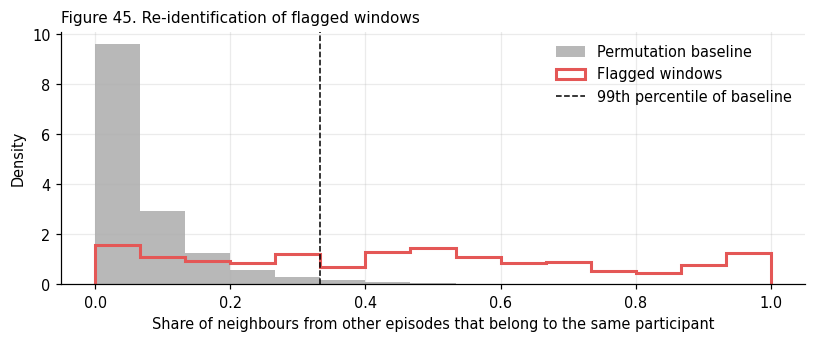

Flagged windows: median share 0.40; baseline 95th / 99th percentiles: 0.20 / 0.33


In [67]:
max_len = int(W.ep_len.max())
_, nb = NearestNeighbors(n_neighbors=max_len + K_NN + 1).fit(Z).kneighbors(Z)
nb = nb[:, 1:]
ep = W.episode.to_numpy()
other_ep = ep[nb] != ep[:, None]
assert (other_ep.sum(1) >= K_NN).all()
nbx = np.take_along_axis(nb, np.argsort(~other_ep, axis=1, kind="stable")[:, :K_NN], axis=1)
reid = (subj[nbx] == subj[:, None]).mean(1)
W["reid"] = reid
flag_arr, fam_arr = W.flag.to_numpy(), W.family.to_numpy()
null_reid = []
for _ in range(N_NULL):
    fake = np.empty(len(W), dtype=int)
    for f in (0, 1):
        m = (W.family == f).to_numpy(); fake[m] = episode_permutation(W[m], r_)
    null_reid.append((fake[nbx] == fake[:, None]).mean(1)[flag_arr])
null_reid = np.concatenate(null_reid)
REID_95, REID_99 = np.percentile(null_reid, [95, 99])
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(null_reid, bins=np.linspace(0, 1, 16), density=True, color=C_GREY, alpha=0.7, label="Permutation baseline")
ax.hist(reid[flag_arr], bins=np.linspace(0, 1, 16), density=True, histtype="step", lw=2, color=C_HIGH, label="Flagged windows")
ax.axvline(REID_99, color="black", ls="--", lw=1, label="99th percentile of baseline")
ax.set(xlabel="Share of neighbours from other episodes that belong to the same participant", ylabel="Density"); ax.legend()
fig_title(ax, "Re-identification of flagged windows")
plt.tight_layout(); plt.show()
print(f"Flagged windows: median share {np.median(reid[flag_arr]):.2f}; baseline 95th / 99th percentiles: {REID_95:.2f} / {REID_99:.2f}")

**Flagged windows are strongly re-identifiable.** The median flagged window has 40% of its neighbours from other episodes belonging to the same participant. Under the permutation baseline, the 95th and 99th percentiles are 20% and 33%. Many flagged windows therefore resemble the same person's windows in other recordings far more than chance would predict.

#### 11.4.3 Descriptive Profile Counts

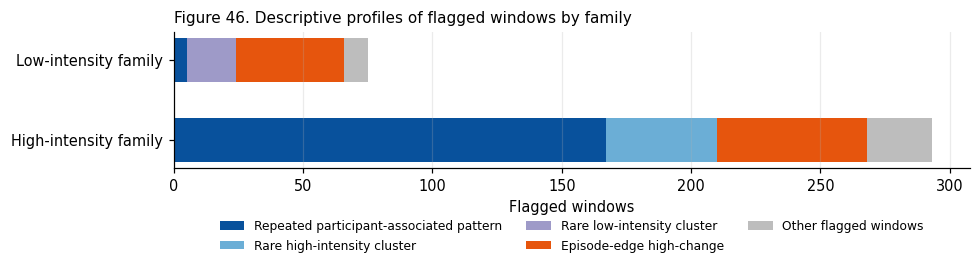

mechanism,Repeated participant-associated pattern,Rare high-intensity cluster,Rare low-intensity cluster,Episode-edge high-change,Other flagged windows,Total
family,,,,,,
High-intensity family,167,43,0,58,25,293
Low-intensity family,5,0,19,42,9,75


In [68]:
W["change_fam"] = np.maximum(W.groupby("family").energy_change.rank(pct=True), W.groupby("family").tilt_change.rank(pct=True))
fam_rate = W.groupby("family").flag.mean().reindex(fam_arr).to_numpy()
rate_other = np.zeros(len(W))
for i in np.flatnonzero(flag_arr):
    m = (subj == subj[i]) & (ep != ep[i]) & (fam_arr == fam_arr[i])
    rate_other[i] = flag_arr[m].mean() if m.any() else 0.0

def attribute(reid_thr=REID_99, change_thr=0.90):
    mech = pd.Series("", index=W.index, dtype=object)
    for i in np.flatnonzero(flag_arr):
        if W.position.iat[i] != "interior" and W.change_fam.iat[i] >= change_thr:
            mech.iat[i] = "Episode-edge high-change"
        elif reid[i] >= reid_thr and rate_other[i] >= 2 * fam_rate[i]:
            mech.iat[i] = "Repeated participant-associated pattern"
        elif W.fine.iat[i].endswith("*"):
            mech.iat[i] = "Rare high-intensity cluster" if fam_arr[i] == 1 else "Rare low-intensity cluster"
        else:
            mech.iat[i] = "Other flagged windows"
    return mech
W["mechanism"] = attribute()
MECH_ORDER = ["Repeated participant-associated pattern", "Rare high-intensity cluster", "Rare low-intensity cluster",
              "Episode-edge high-change", "Other flagged windows"]
MECH_COL = dict(zip(MECH_ORDER, ["#08519C", "#6BAED6", "#9E9AC8", "#E6550D", "#BDBDBD"]))
counts = pd.crosstab(W[W.flag].family.map(FAM_NAME), W[W.flag].mechanism).reindex(columns=MECH_ORDER, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 2.8))
left = np.zeros(len(counts))
for m_ in MECH_ORDER:
    ax.barh(counts.index, counts[m_], left=left, color=MECH_COL[m_], label=m_, height=0.55); left += counts[m_].to_numpy()
ax.set(xlabel="Flagged windows"); ax.grid(axis="y", visible=False)
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.3))
fig_title(ax, "Descriptive profiles of flagged windows by family")
plt.tight_layout(); plt.show()
display(counts.assign(Total=counts.sum(axis=1)))

**The two families contain different types of flagged-window profiles.** The figure reports counts assigned by the rule hierarchy above, and the table shows their distribution across families. These groups capture **observable context**—episode position, participant recurrence and rare-cluster membership—not established physical causes.

#### 11.4.4 Sensitivity to Profile Thresholds
The grouping is repeated for three participant re-identification thresholds and three within-window-change thresholds. This tests the stability of the *rule-based categorisation*, not the accuracy of its causal explanations.

In [69]:
grid_res = {}
for rt_name, rt in [("95th percentile", REID_95), ("99th percentile", REID_99), ("0.50", 0.5)]:
    for ct_ in (0.85, 0.90, 0.95):
        s_ = attribute(rt, ct_)[flag_arr].value_counts(normalize=True).reindex(MECH_ORDER, fill_value=0)
        s_["Participant-pattern or rare-cluster profile (combined)"] = s_[MECH_ORDER[:3]].sum()
        grid_res[(rt_name, ct_)] = s_
grid_res = pd.DataFrame(grid_res).T * 100
main = W[W.flag].mechanism.value_counts(normalize=True).reindex(MECH_ORDER, fill_value=0) * 100
main["Participant-pattern or rare-cluster profile (combined)"] = main[MECH_ORDER[:3]].sum()
display(pd.DataFrame({"Main rule (%)": main, "Minimum (%)": grid_res.min(), "Maximum (%)": grid_res.max()}).round(1))

,Main rule (%),Minimum (%),Maximum (%)
Repeated participant-associated pattern,46.7,30.2,59.2
Rare high-intensity cluster,11.7,6.8,26.6
Rare low-intensity cluster,5.2,5.2,5.4
Episode-edge high-change,27.2,19.0,29.6
Other flagged windows,9.2,7.1,14.9
Participant-pattern or rare-cluster profile (combined),63.6,58.7,72.0


**The rule-based profile composition is threshold-dependent.** The table reports the main rule and the minimum–maximum share across the nine threshold combinations. The relative allocation between the participant-associated category and the rare high-intensity group is particularly sensitive to re-identification criteria.

The combined share of participant-pattern/rare-cluster profiles can be reported as an **operational descriptive summary**, but it should not be called the proportion of anomalies whose causes are known or whose movement is proven consistent.

#### 11.4.5 Flags That Survive Spread Equalisation
Section 10.3.1 identified flags that remain after differences in cluster spread are reduced. Their descriptive profiles show which patterns remain associated with high scores under this alternative representation.

In [70]:
surv = W[W.survives_eq]
display(surv.mechanism.value_counts().reindex(MECH_ORDER, fill_value=0).to_frame("Flags surviving equalisation"))
print(f"Re-identifiable above the baseline's 95th percentile: {(surv.reid >= REID_95).mean():.0%} of {len(surv)}")

,Flags surviving equalisation
mechanism,
Repeated participant-associated pattern,62
Rare high-intensity cluster,7
Rare low-intensity cluster,5
Episode-edge high-change,51
Other flagged windows,34


Re-identifiable above the baseline's 95th percentile: 77% of 159


**The remaining flags still contain participant-associated and episode-edge patterns.** The table identifies the categories assigned to observations that remain flagged after spread equalisation; the additional statistic quantifies cross-episode participant-neighbour similarity.

These are conditional associations under the chosen scoring and threshold rules. Spread equalisation changes feature-space distances, so neither the surviving flags nor their descriptive categories should be interpreted as an independently isolated physical cause.

#### 11.4.6 Correspondence with Recorded Activities
The descriptive profiles are cross-tabulated with the recorded activity labels. Episode-edge high-change windows labelled as static postures are compared with interior windows of those postures.

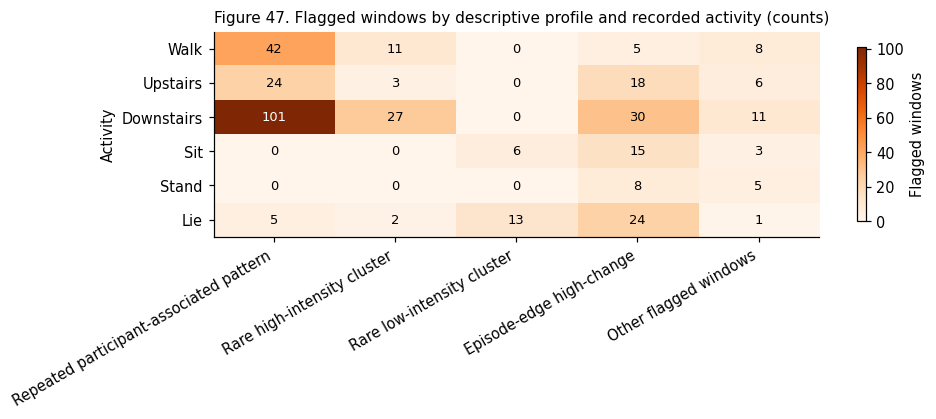

Episode-edge high-change windows labelled as a static posture: 47; share with more movement than 90% of interior windows of the same posture: 100%


In [71]:
mech_act = (pd.crosstab(pd.Series(act[flag_arr], name="Activity"), pd.Series(W.mechanism.to_numpy()[flag_arr], name="Mechanism"))
            .reindex(index=ACT_ORDER, columns=MECH_ORDER, fill_value=0).rename(index=ACT_SHORT))
heatmap(mech_act, "Flagged windows by descriptive profile and recorded activity (counts)", fmt="{:.0f}", cmap="Oranges",
        ylabel="Activity", cbar_label="Flagged windows", figsize=(9, 3.9))
st = np.isin(act, ["SITTING", "STANDING", "LAYING"])
interior = (W.position == "interior").to_numpy()
q90 = pd.Series(W.acc_rms.to_numpy()[st & interior]).groupby(act[st & interior]).quantile(0.9)
tw = (W.mechanism == "Episode-edge high-change").to_numpy() & st
print(f"Episode-edge high-change windows labelled as a static posture: {tw.sum()}; share with more movement than 90% of interior windows "
      f"of the same posture: {(W.acc_rms.to_numpy()[tw] > q90.reindex(act[tw]).to_numpy()).mean():.0%}")

**The profile distribution is consistent with differences in movement context, not a verification of mechanisms.** The activity cross-tabulation shows where participant-associated and rare-cluster profiles occur, and whether episode-edge high-change windows are more common in recorded static activities.

A static-labelled window near an inferred episode boundary that contains more movement than most interior windows of the same posture is compatible with residual movement around a transition. The analysis **does not verify that a transition occurred**, that the activity label is incorrect, or that a sensor fault is absent.

### 11.5 Participant Movement Intensity and Estimated Device Orientation

#### 11.5.1 Participant-Level Characteristics
Recurring participant-associated differences may involve movement intensity, rhythmic motion, orientation or unmeasured recording factors. For each high-intensity participant, we compare median acceleration magnitude, dominant-frequency descriptor and mean **estimated gravity-direction** offset with their anomaly flag rate. The gravity estimate is derived from total minus body acceleration, not from unfiltered total acceleration. These are observational proxies and cannot isolate gait from smartphone placement.

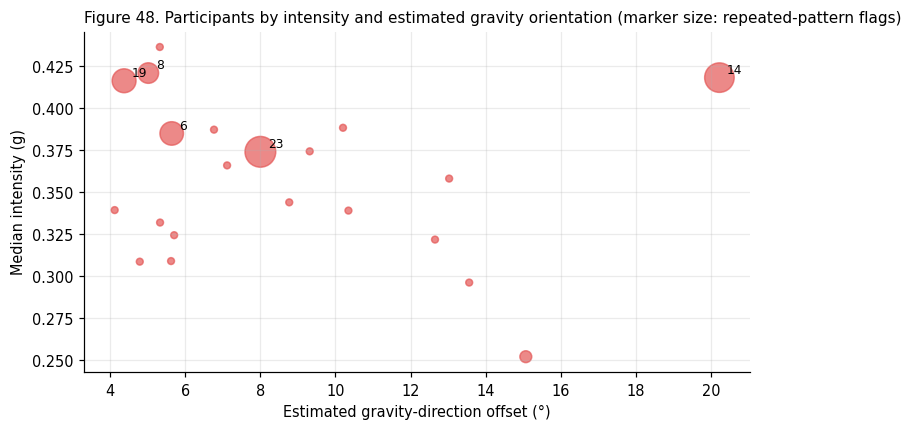

,Spearman correlation with flag rate
Intensity (g),0.54
Dominant frequency (Hz),0.15
Estimated gravity-direction offset (°),-0.37


,Flag rate (%),Participant-associated profile flags,Intensity (g),Dominant frequency (Hz),Estimated gravity-direction offset (°)
subject,,,,,
19,44.27,28,0.42,3.91,4.37
14,36.25,44,0.42,1.56,20.23
23,35.37,48,0.37,1.56,8.00
6,26.11,27,0.38,3.52,5.64
8,25.98,20,0.42,1.95,5.02


Participant medians: intensity 0.358 g, dominant frequency 3.12 Hz, orientation offset 7.1°


In [72]:
hiW = W[W.family == 1]
gvec = hiW[["grav_x", "grav_y", "grav_z"]].to_numpy(); gvec = gvec / np.linalg.norm(gvec, axis=1, keepdims=True)
pop = gvec.mean(0); pop /= np.linalg.norm(pop)
pp = pd.DataFrame({"subject": hiW.subject, "gx": gvec[:, 0], "gy": gvec[:, 1], "gz": gvec[:, 2]}).groupby("subject").mean()
pvec = pp[["gx", "gy", "gz"]].to_numpy().copy(); pvec = pvec / np.linalg.norm(pvec, axis=1, keepdims=True)
pp["Estimated gravity-direction offset (°)"] = np.degrees(np.arccos(np.clip(pvec @ pop, -1, 1)))
pp["Intensity (g)"] = hiW.groupby("subject").acc_rms.median()
pp["Dominant frequency (Hz)"] = hiW.groupby("subject").dom_freq.median()
pp["Flag rate (%)"] = hiW.groupby("subject").flag.mean() * 100
pp["Participant-associated profile flags"] = W[W.mechanism == MECH_ORDER[0]].groupby("subject").size().reindex(pp.index, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(pp["Estimated gravity-direction offset (°)"], pp["Intensity (g)"], s=20 + 8 * pp["Participant-associated profile flags"], color=C_HIGH, alpha=0.7)
for s_, r__ in pp.nlargest(5, "Flag rate (%)").iterrows():
    ax.annotate(str(s_), (r__["Estimated gravity-direction offset (°)"], r__["Intensity (g)"]), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set(xlabel="Estimated gravity-direction offset (°)", ylabel="Median intensity (g)")
fig_title(ax, "Participants by intensity and estimated gravity orientation (marker size: repeated-pattern flags)")
plt.tight_layout(); plt.show()
display(pd.Series({c: spearmanr(pp[c], pp["Flag rate (%)"])[0] for c in ["Intensity (g)", "Dominant frequency (Hz)", "Estimated gravity-direction offset (°)"]},
                  name="Spearman correlation with flag rate").to_frame().round(2))
display(pp.sort_values("Flag rate (%)", ascending=False).head(5)[["Flag rate (%)", "Participant-associated profile flags", "Intensity (g)",
        "Dominant frequency (Hz)", "Estimated gravity-direction offset (°)"]].round(2))
print(f"Participant medians: intensity {pp['Intensity (g)'].median():.3f} g, dominant frequency {pp['Dominant frequency (Hz)'].median():.2f} Hz, "
      f"orientation offset {pp['Estimated gravity-direction offset (°)'].median():.1f}°")

**Flag rate rises with participants' movement intensity, but not with their orientation offset.** Across the 21 participants:
* the Spearman correlation between flag rate and median intensity is 0.54; all five most-flagged participants (26–44% of their dynamic windows) have intensities of 0.37–0.42 g, above the participant median of 0.36 g;
* the correlation with dominant frequency is weak (0.15): the five most-flagged participants include both the lowest (1.56 Hz) and among the highest (3.91 Hz) values;
* the correlation with estimated gravity-direction offset is negative (−0.37). Four of the five most-flagged participants have offsets of 4–8°, close to the median of 7.1°; only participant 14 (20°) has an unusual orientation.

With 21 participants these correlations are imprecise, but they point to movement intensity rather than a tilted phone as the more consistent participant-level correlate. A weak orientation association does **not** rule out device placement: placement may affect dynamic measurements without producing a large average gravity-direction offset, and attachment was not measured independently. This analysis identifies possible correlates, **not** a causal distinction between gait and placement.

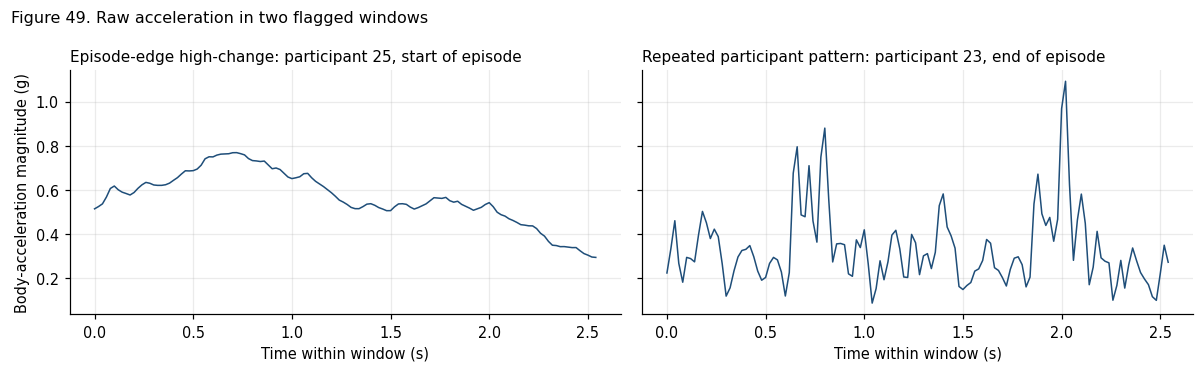

In [73]:
trans = W[(W.mechanism == "Episode-edge high-change") & (W.family == 0)].sort_values("change_fam", ascending=False).index[0]
indiv = W[(W.mechanism == MECH_ORDER[0])].sort_values("reid", ascending=False).index[0]
tt = np.arange(128) / 50
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a_, i, ttl in [(ax[0], trans, "Episode-edge high-change"), (ax[1], indiv, "Repeated participant pattern")]:
    a_.plot(tt, ACC_MAG[i], color=C_GLOBAL, lw=1)
    a_.set(xlabel="Time within window (s)", title=f"{ttl}: participant {subj[i]}, {W.position.iat[i]} of episode")
ax[0].set_ylabel("Body-acceleration magnitude (g)")
fig_title(fig, "Raw acceleration in two flagged windows")
plt.tight_layout(); plt.show()

**The two traces show different kinds of unusualness.**
* The **episode-edge** window (participant 25, start of an episode in the low-intensity family) has a smooth, slowly varying body-acceleration magnitude of 0.3–0.8 g, decaying over the window, with no impact peaks. Static windows typically have a median of about 0.012 g, so this is sustained whole-body movement rather than stepping. It is compatible with settling into a posture; it may also partly reflect gravity leaking into the body-acceleration channel while the phone's orientation changes.
* The **repeated participant pattern** window (participant 23, end of an episode in the high-intensity family) is spiky and irregular, with sharp peaks up to about 1.1 g at uneven intervals. This is vigorous dynamic movement that resembles the same participant's windows in other episodes.

These are single illustrative cases. They do not identify an actual postural transition, rule out device placement or demonstrate an intrinsic gait signature.

## 12. Integration of Clustering and Anomaly Detection
Four questions connect the clustering and anomaly analyses. The table below adds the one comparison not yet made: how much the shortlist of flagged windows changes when the representation or the clustering reference changes.

In [74]:
def within_group_knn(R, groups, k=K_NN):
    s = np.zeros(len(R))
    for g in np.unique(groups):
        m = groups == g; kk = min(k, m.sum() - 1)
        s[m] = NearestNeighbors(n_neighbors=kk + 1).fit(R[m]).kneighbors(R[m])[0][:, kk]
    return s
comp_rows = []
for name, R in REPS.items():
    if name.endswith("(main)"):
        continue
    comp_rows.append({"Comparison": f"Representation: {name}", "Jaccard with the main shortlist": jaccard(W.flag, top_flags(knn_score(R)))})
for name, groups in [("Neighbours drawn only from the same family", fam),
                     (f"Neighbours drawn only from the same K-Means cluster (k = {K_FINE})", fine),
                     (f"Neighbours drawn only from the same Gaussian-mixture component (k = {K_FINE})", gmm_fine.predict(Z))]:
    comp_rows.append({"Comparison": name, "Jaccard with the main shortlist": jaccard(W.flag, top_flags(within_group_knn(Z, groups)))})
display(pd.DataFrame(comp_rows).set_index("Comparison").round(2))
print(f"Flagged windows that HDBSCAN (min_samples = 15) leaves unassigned: {(HDB[15][flag_arr] < 0).mean():.0%} "
      f"(all windows: {(HDB[15] < 0).mean():.0%})")
print(f"Flagged windows in the rare clusters: {W[W.flag].fine.str.endswith('*').mean():.0%} "
      f"(all windows: {W.fine.str.endswith('*').mean():.0%})")

,Jaccard with the main shortlist
Comparison,
"Representation: Block-wise PCA, 60%",0.68
"Representation: Block-wise PCA, 80%",0.76
"Representation: Block-wise PCA, 3 components per family",0.73
"Representation: Global PCA, 50 components",0.62
Neighbours drawn only from the same family,1.00
Neighbours drawn only from the same K-Means cluster (k = 6),0.80
Neighbours drawn only from the same Gaussian-mixture component (k = 6),0.69


Flagged windows that HDBSCAN (min_samples = 15) leaves unassigned: 100% (all windows: 38%)
Flagged windows in the rare clusters: 76% (all windows: 8%)


#### 12.1 Are anomalies outside the main clusters, or unusual only relative to a local cluster?
**This depends on the reference.** Every globally flagged window is among those that HDBSCAN leaves unassigned (100%, against 38% of all windows). From a density perspective, the global anomalies therefore lie outside the dense cores of both families. Relative to their K-Means centroids, they have larger distance-to-centroid ratios (Section 10.4.1); that statistic does not determine whether a point is geometrically between or beyond clusters. Local detectors, which judge each window against its own neighbourhood, flag a largely different set of windows.

#### 12.2 Do some apparent anomalies form a legitimate small cluster?
**Yes.** The two rare clusters hold 8% of windows but 76% of global flags.
* H3\* is a reproducible cluster of vigorous dynamic movement, drawn mainly from five participants.
* L3\* is a cluster of static windows that contain movement.

Once these clusters are given a reference of their own, or their spread is equalised, most of their apparent unusualness disappears (Section 10.3).

#### 12.3 Do representation and clustering assumptions change which windows appear anomalous?
**Moderately, and mainly through the use of local density.**
* Alternative representations retain 62–76% of the shortlist. Agreement is lowest with the global PCA, which does not balance the feature families.
* Restricting neighbours to the window's family changes nothing (Jaccard 1.00), because nearest neighbours already come from the same family.
* Restricting neighbours to the window's K-Means cluster or Gaussian-mixture component changes the shortlist only modestly (0.80 and 0.69).

What changes the shortlist substantially is not the pool of neighbours but whether distances are judged relative to local density, as LOF and the relative-centroid score do.

#### 12.4 What does agreement and disagreement between the analyses reveal?
* **Agreement:** the same two rare clusters dominate both the clustering and the global anomaly results. Many globally flagged windows occur in rare but reproducible movement groups, often associated with particular participants.
* **Disagreement:** global and local detectors identify different windows. Unusualness is not an intrinsic property of a window but a relationship between a window and its reference population.
* **What remains unresolved:** the rule-based profiling in Section 11.4 describes where flags occur but cannot verify their physical causes. Windows that receive a descriptive profile may still reflect unmeasured recording effects or other explanations.

## 13. Generalisation to Unseen Participants

### 13.1 Application of the Fitted Pipeline
The nine test participants are now read for the first time. The fitted standardisation, block-wise PCA, cluster models and detectors are applied without refitting.

A threshold taken from the training scores would be too strict for new people, because training windows are compared with neighbours that include their own participant's other episodes. The k-NN threshold is therefore calibrated out of sample: each training participant is scored against a model fitted on the other 20 participants, and the 95th percentile of those scores is used. Test windows are scored against all 21 training participants, so in both cases the reference excludes the window's own participant and has almost the same size (20 against 21 participants).

In [75]:
X_te_raw, subj_te, act_te, SIG_te = load_split("test")
assert set(subj_te).isdisjoint(set(subj))
W_te = reconstruct_episodes(subj_te, SIG_te).join(raw_descriptors(SIG_te)[0])
Z_te = block.transform(pd.DataFrame(scaler.transform(X_te_raw[X_dedup.columns]), columns=X_dedup.columns))
fam_te = (KM[K_BROAD].predict(Z_te) == hi).astype(int)
fine_te = KM[K_FINE].predict(Z_te)
W_te["family"], W_te["fine"] = fam_te, [FINE_NAME[c] for c in fine_te]

oos = np.zeros(len(Z)); oos_lof = np.zeros(len(Z))
for tr, te in GroupKFold(len(people)).split(Z, groups=subj):   # leave one participant out
    oos[te] = NearestNeighbors(n_neighbors=K_NN).fit(Z[tr]).kneighbors(Z[te])[0][:, K_NN - 1]
    oos_lof[te] = -LocalOutlierFactor(n_neighbors=20, novelty=True).fit(Z[tr]).score_samples(Z[te])
W_te["score_knn"] = NearestNeighbors(n_neighbors=K_NN).fit(Z).kneighbors(Z_te)[0][:, K_NN - 1]
W_te["flag"] = W_te.score_knn > np.quantile(oos, 1 - TOP)
flag_lof_te = -LocalOutlierFactor(n_neighbors=20, novelty=True).fit(Z).score_samples(Z_te) > np.quantile(oos_lof, 1 - TOP)
oos_rate = pd.Series(oos > np.quantile(oos, 1 - TOP)).groupby(subj).mean() * 100
te_rate = W_te.groupby("subject").flag.mean() * 100
print(f"Out-of-sample flag rate per training participant: median {oos_rate.median():.1f}%, range {oos_rate.min():.1f}–{oos_rate.max():.1f}%; "
      f"{(oos_rate > 10).sum()} of {len(oos_rate)} above 10%")
print(f"Flag rate per test participant: median {te_rate.median():.1f}%, range {te_rate.min():.1f}–{te_rate.max():.1f}%; "
      f"{(te_rate > 10).sum()} of {len(te_rate)} above 10%")
print(f"Test data: {len(W_te):,} windows from {len(np.unique(subj_te))} participants; flagged: {W_te.flag.sum()} ({W_te.flag.mean():.1%})")

Out-of-sample flag rate per training participant: median 0.9%, range 0.0–25.1%; 5 of 21 above 10%
Flag rate per test participant: median 1.7%, range 0.0–7.1%; 0 of 9 above 10%
Test data: 2,947 windows from 9 participants; flagged: 65 (2.2%)


### 13.2 Replication of the Principal Findings

In [76]:
def over_te(flags, frame, name):
    m = (frame.fine == name).to_numpy(); f = np.asarray(flags)
    return f[m].mean() / max(f.mean(), 1e-9)
g_te = W_te[(W_te.pos % 2 == 0) & (W_te.family == 1)]
y_te = np.log(g_te.score_knn.to_numpy())
dec_te = decompose(y_te, g_te.subject.to_numpy(), g_te.episode.to_numpy())
null_te = np.percentile([decompose(y_te, episode_permutation(g_te, r_), g_te.episode.to_numpy())["Participant"] for _ in range(N_NULL)], 95)
d_te = W_te[W_te.family == 1].copy()
d_te["half"] = d_te.groupby("subject").episode.rank(method="dense").astype(int) % 2
t_te = d_te.groupby(["subject", "half"]).flag.mean().unstack().dropna()
r_te = pearsonr(t_te[0], t_te[1])[0]
down, down_te = act == "WALKING_DOWNSTAIRS", act_te == "WALKING_DOWNSTAIRS"
rep = pd.DataFrame([
    {"Finding": "Two families: agreement with K-Means refitted on the test participants (ARI)", "Training": 1.0,
     "Test": adjusted_rand_score(fam_te, KMeans(2, n_init=10, random_state=SEED).fit_predict(Z_te))},
    {"Finding": "Two families: agreement with the static/dynamic distinction", "Training": (fam == dynamic).mean(),
     "Test": (fam_te == np.isin(act_te, ACT_ORDER[:3])).mean()},
    {"Finding": f"Fine partition: agreement with K-Means (k = {K_FINE}) refitted on the test participants (ARI)", "Training": 1.0,
     "Test": adjusted_rand_score(fine_te, KMeans(K_FINE, n_init=10, random_state=SEED).fit_predict(Z_te))},
    {"Finding": "Share of windows flagged", "Training": W.flag.mean(), "Test": W_te.flag.mean()},
    *[{"Finding": f"Over-representation of {n}: k-NN (global)", "Training": over(W.flag, n), "Test": over_te(W_te.flag, W_te, n)} for n in RARE],
    *[{"Finding": f"Over-representation of {n}: LOF (local)", "Training": over(FLAGS['Local Outlier Factor'], n), "Test": over_te(flag_lof_te, W_te, n)} for n in RARE],
    {"Finding": "Over-representation of walking downstairs: k-NN (global)", "Training": W.flag[down].mean() / W.flag.mean(),
     "Test": W_te.flag[down_te].mean() / W_te.flag.mean()},
    {"Finding": "Over-representation of walking downstairs: LOF (local)",
     "Training": FLAGS["Local Outlier Factor"][down].mean() / FLAGS["Local Outlier Factor"].mean(),
     "Test": flag_lof_te[down_te].mean() / flag_lof_te.mean()},
    {"Finding": "Participant share of anomaly-score variance, high-intensity family", "Training": dec.loc[FAM_NAME[1], "Participant"], "Test": dec_te["Participant"]},
    {"Finding": "Participant share, 95th percentile under permutation", "Training": null_rows[FAM_NAME[1]][1], "Test": null_te},
    {"Finding": "Split-half correlation of participant flag rates", "Training": r_split, "Test": r_te},
]).set_index("Finding")
display(rep.round(3))

,Training,Test
Finding,,
Two families: agreement with K-Means refitted on the test participants (ARI),1.000,0.999
Two families: agreement with the static/dynamic distinction,0.998,0.999
Fine partition: agreement with K-Means (k = 6) refitted on the test participants (ARI),1.000,0.704
Share of windows flagged,0.050,0.022
Over-representation of L3*: k-NN (global),6.194,13.950
Over-representation of H3*: k-NN (global),12.686,19.836
Over-representation of L3*: LOF (local),2.094,0.480
Over-representation of H3*: LOF (local),1.777,1.561
Over-representation of walking downstairs: k-NN (global),3.424,3.670


#### 13.2.1 Clustering
The frozen partitions are compared with K-Means refitted on the test participants alone. An agreement of 1 means that the structure learned from the training participants is exactly the structure present in the new participants.

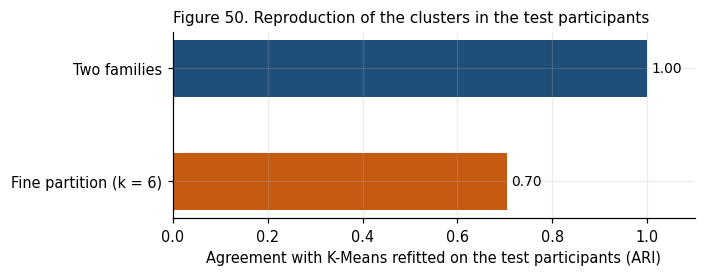

Agreement of the two families with the static/dynamic distinction: training 99.8%, test 99.9%


In [77]:
clu = pd.Series({"Two families": rep.iloc[0]["Test"], f"Fine partition (k = {K_FINE})": rep.iloc[2]["Test"]})
fig, ax = plt.subplots(figsize=(6.5, 2.6))
b = ax.barh(clu.index, clu.values, color=[C_GLOBAL, C_LOCAL], height=0.5)
ax.bar_label(b, fmt="%.2f", fontsize=9, padding=3); ax.invert_yaxis()
ax.set(xlim=(0, 1.1), xlabel="Agreement with K-Means refitted on the test participants (ARI)")
fig_title(ax, "Reproduction of the clusters in the test participants")
plt.tight_layout(); plt.show()
print(f"Agreement of the two families with the static/dynamic distinction: training {rep.iloc[1]['Training']:.1%}, test {rep.iloc[1]['Test']:.1%}")

**The two families are reproduced almost exactly; the fine partition only moderately.** The frozen two-family partition agrees with K-Means refitted on the test participants almost perfectly (ARI 0.999), and it matches the static/dynamic distinction for 99.9% of test windows (99.8% in training). The fine partition agrees less well (ARI 0.70), consistent with its sensitivity to analytical choices in Section 9.3.

#### 13.2.2 Over-Representation Under Global and Local Detectors
Over-representation among flagged windows is compared between the training and test participants, for the two rare clusters and for walking downstairs.

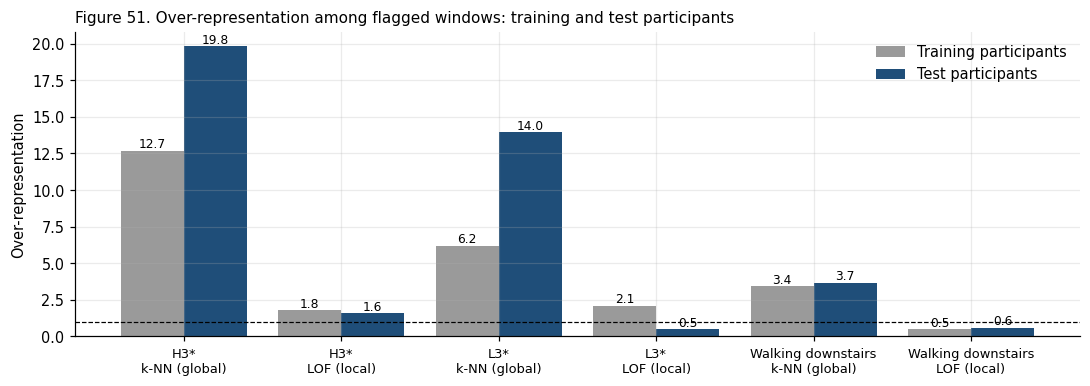

In [78]:
ov = rep.loc[sorted([i for i in rep.index if i.startswith("Over-representation")], key=lambda i: (i.split(":")[0], "LOF" in i))]
ov.index = [i.replace("Over-representation of ", "").replace("walking", "Walking").replace(": ", "\n") for i in ov.index]
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(ov))
b1 = ax.bar(x - 0.2, ov["Training"], 0.4, color=C_GREY, label="Training participants")
b2 = ax.bar(x + 0.2, ov["Test"], 0.4, color=C_GLOBAL, label="Test participants")
ax.bar_label(b1, fmt="%.1f", fontsize=8); ax.bar_label(b2, fmt="%.1f", fontsize=8)
ax.axhline(1, color="black", ls="--", lw=0.8)
ax.set_xticks(x, ov.index, fontsize=8.5); ax.set(ylabel="Over-representation"); ax.legend()
fig_title(ax, "Over-representation among flagged windows: training and test participants")
plt.tight_layout(); plt.show()

**The contrast between global and local detectors replicates.**
* Under k-NN, the rare clusters and walking downstairs remain strongly over-represented in the test participants (3.7–19.8 times their proportional share).
* Under LOF, their over-representation is much smaller (0.5–1.6), as in training.

**Only 2.2% of test windows are flagged, against a nominal 5%, and the reason is participant composition rather than calibration.** The threshold is calibrated leave-one-participant-out, so training and test windows are scored against references of almost the same size. The typical participant is flagged at a similar rate in both sets (median 0.9% of training participants' windows, 1.7% of test participants'). The difference comes from the tail: five of the 21 training participants are flagged in more than 10% of their windows, whereas none of the nine test participants is. This is what Section 11 predicts. Because flags are concentrated in a few individuals, the overall flag rate of a nine-person sample depends on whether it happens to include such individuals.

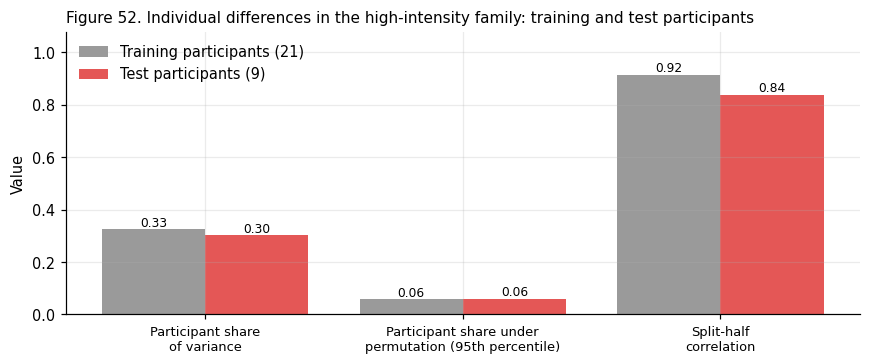

In [79]:
ind = pd.DataFrame({"Training": [rep.iloc[-3]["Training"], rep.iloc[-2]["Training"], rep.iloc[-1]["Training"]],
                    "Test": [rep.iloc[-3]["Test"], rep.iloc[-2]["Test"], rep.iloc[-1]["Test"]]},
                   index=["Participant share\nof variance", "Participant share under\npermutation (95th percentile)", "Split-half\ncorrelation"])
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(ind))
b1 = ax.bar(x - 0.2, ind["Training"], 0.4, color=C_GREY, label="Training participants (21)")
b2 = ax.bar(x + 0.2, ind["Test"], 0.4, color=C_HIGH, label="Test participants (9)")
ax.bar_label(b1, fmt="%.2f", fontsize=8); ax.bar_label(b2, fmt="%.2f", fontsize=8)
ax.set_xticks(x, ind.index, fontsize=8.5); ax.set(ylim=(0, 1.08), ylabel="Value"); ax.legend(loc="upper left")
fig_title(ax, "Individual differences in the high-intensity family: training and test participants")
plt.tight_layout(); plt.show()

**The participant-associated pattern replicates.** In the high-intensity family, the participant share of anomaly-score variance is 0.30 in the test participants against 0.33 in training, both above their respective permutation references (approximately 0.06). Split-half flag-rate correlations are 0.84 and 0.92, respectively. With only nine test participants, these estimates are imprecise, but they support similar **statistical recurrence**, not a specific gait or placement mechanism.

### 13.3 Consequences for Activity Recognition
A supervised activity classifier may make more mistakes on high-scoring windows because those observations are less typical in the chosen representation. However, the flagged and unflagged samples may have different activity compositions. We therefore report (i) overall and family-level error rates and (ii) a **within-activity adjusted comparison**. Participant-grouped cross-validation is used for the training-set diagnostic, and the independent nine-participant test set provides the primary held-out result. The representation was fitted before grouped CV, so training-fold results are exploratory; the test-set result is evaluated with the fixed training-derived representation.

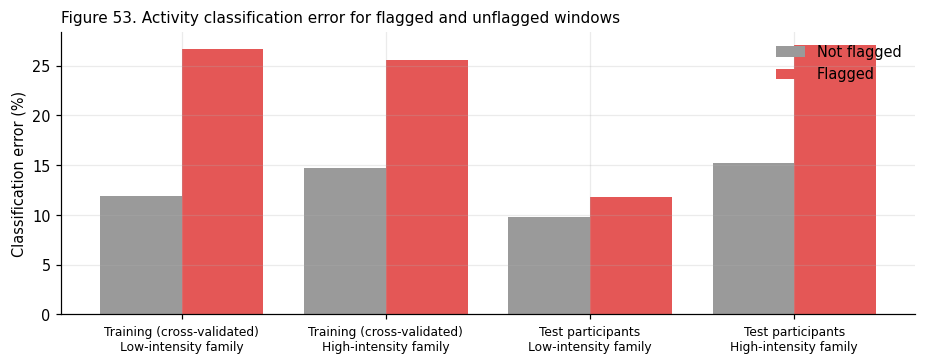

,Training (cross-validated),Test participants
"Accuracy, full representation",0.863,0.874
"Accuracy, fine-cluster identity only",0.607,0.588
"Error rate, flagged windows",0.258,0.231
"Error rate, unflagged windows",0.131,0.124


Total run time: 2.0 minutes


In [80]:
onehot = np.eye(K_FINE)[fine]
pred_cv = np.empty(len(Z), dtype=object); pred_cl = np.empty(len(Z), dtype=object)
for tr, te in GroupKFold(7).split(Z, act, groups=subj):
    pred_cv[te] = LogisticRegression(max_iter=3000).fit(Z[tr], act[tr]).predict(Z[te])
    pred_cl[te] = LogisticRegression(max_iter=3000).fit(onehot[tr], act[tr]).predict(onehot[te])
pred_te = LogisticRegression(max_iter=3000).fit(Z, act).predict(Z_te)
pred_te_cl = LogisticRegression(max_iter=3000).fit(onehot, act).predict(np.eye(K_FINE)[fine_te])
err_tr, err_te = pred_cv != act, pred_te != act_te
flag_te = W_te.flag.to_numpy()
bars = []
for split_name, e_, F_, fm in [("Training (cross-validated)", err_tr, flag_arr, fam), ("Test participants", err_te, flag_te, fam_te)]:
    for f in (0, 1):
        bars.append({"split": split_name, "family": FAM_NAME[f], "Flagged": e_[F_ & (fm == f)].mean() * 100,
                     "Not flagged": e_[~F_ & (fm == f)].mean() * 100, "Flagged windows": int((F_ & (fm == f)).sum())})
bars = pd.DataFrame(bars)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
x = np.arange(len(bars))
ax.bar(x - 0.2, bars["Not flagged"], 0.4, color=C_GREY, label="Not flagged")
ax.bar(x + 0.2, bars["Flagged"], 0.4, color=C_HIGH, label="Flagged")
ax.set_xticks(x, [f"{r.split}\n{r.family}" for r in bars.itertuples()], fontsize=8)
ax.set(ylabel="Classification error (%)"); ax.legend()
fig_title(ax, "Activity classification error for flagged and unflagged windows")
plt.tight_layout(); plt.show()
display(pd.DataFrame({
    "Training (cross-validated)": {"Accuracy, full representation": 1 - err_tr.mean(), "Accuracy, fine-cluster identity only": (pred_cl == act).mean(),
                                   "Error rate, flagged windows": err_tr[flag_arr].mean(), "Error rate, unflagged windows": err_tr[~flag_arr].mean()},
    "Test participants": {"Accuracy, full representation": 1 - err_te.mean(), "Accuracy, fine-cluster identity only": (pred_te_cl == act_te).mean(),
                          "Error rate, flagged windows": err_te[flag_te].mean(), "Error rate, unflagged windows": err_te[~flag_te].mean()}}).round(3))
print(f"Total run time: {(time.time() - T0) / 60:.1f} minutes")

**Globally flagged windows show higher unadjusted classification error.** In participant-grouped training cross-validation, the error rate is 25.8% for flagged windows versus 13.1% for unflagged windows; on held-out participants, the corresponding rates are 23.1% versus 12.4%.

**This unadjusted difference may partly reflect activity composition.** For example, a movement type that is both more frequently flagged and harder to classify could produce a higher overall error rate without any additional relationship between unusualness and error *within that activity*.

Fine-cluster identity alone yields roughly 59–61% activity accuracy, compared with 86–87% for the full representation. The clusters therefore preserve some, but not all, of the activity information.

#### 13.3.1 Within-Activity Comparison of Classification Error
To account for the different activity compositions, the following check compares flagged and unflagged windows **within each recorded activity**. It then weights the unflagged error rates by the observed activity composition of flagged windows, producing an activity-standardised reference error rate. Participant-level bootstrap intervals reflect the independent sampling unit more closely than window-level intervals.

In [81]:
# Activity-controlled association between global anomaly flags and classification errors.
# The comparison conditions on the recorded activity; it does not establish causation.
def activity_controlled_error(errors, flags, activities, participants, split_name, n_boot=500, seed=SEED):
    df = pd.DataFrame({
        "activity": np.asarray(activities),
        "participant": np.asarray(participants),
        "flag": np.asarray(flags, dtype=bool),
        "error": np.asarray(errors, dtype=bool)
    })
    rows = []
    for activity in ACT_ORDER:
        g = df.loc[df.activity == activity]
        f = g.loc[g.flag, "error"]
        u = g.loc[~g.flag, "error"]
        rows.append({
            "Activity": activity, "Flagged n": len(f), "Unflagged n": len(u),
            "Flagged error (%)": 100 * f.mean() if len(f) else np.nan,
            "Unflagged error (%)": 100 * u.mean() if len(u) else np.nan,
            "Difference (pp)": 100 * (f.mean() - u.mean()) if len(f) and len(u) else np.nan,
        })
    tab = pd.DataFrame(rows).set_index("Activity")
    print(f"\n{split_name}: error comparison within recorded activities")
    display(tab.round(1))

    # Counts and error counts for a participant-grouped bootstrap.
    people = pd.Index(np.unique(df.participant))
    counts = np.zeros((len(people), len(ACT_ORDER), 2), dtype=float)
    error_counts = np.zeros_like(counts)
    p_idx = {p: i for i, p in enumerate(people)}
    a_idx = {a: i for i, a in enumerate(ACT_ORDER)}
    for (p, a, f), g in df.groupby(["participant", "activity", "flag"]):
        idx = (p_idx[p], a_idx[a], int(f))
        counts[idx] = len(g)
        error_counts[idx] = g.error.sum()

    def contrast(multiplicities):
        weighted_n = np.tensordot(multiplicities, counts, axes=(0, 0))
        weighted_e = np.tensordot(multiplicities, error_counts, axes=(0, 0))
        eligible = (weighted_n[:, 1] > 0) & (weighted_n[:, 0] > 0)
        if not np.any(eligible):
            return np.nan, np.nan, np.nan, 0
        flag_n = weighted_n[eligible, 1]
        observed = weighted_e[eligible, 1].sum() / flag_n.sum()
        reference = np.sum(flag_n * weighted_e[eligible, 0] / weighted_n[eligible, 0]) / flag_n.sum()
        return observed, reference, observed - reference, int(flag_n.sum())

    observed, reference, difference, supported_n = contrast(np.ones(len(people)))
    rng = np.random.default_rng(seed)
    boot_diffs = []
    for _ in range(n_boot):
        multiplicities = rng.multinomial(len(people), np.full(len(people), 1 / len(people)))
        d = contrast(multiplicities)[2]
        if np.isfinite(d):
            boot_diffs.append(d)
    ci = np.percentile(boot_diffs, [2.5, 97.5]) if boot_diffs else [np.nan, np.nan]
    print(f"Activity-adjusted reference error: {reference:.1%}; flagged error: {observed:.1%}")
    print(f"Within-activity excess error: {100*difference:+.1f} pp ",
          f"(participant bootstrap 95% interval: {100*ci[0]:+.1f} to {100*ci[1]:+.1f} pp; ",
          f"flagged windows in comparable activities: {supported_n})")
    return tab, {"split": split_name, "observed_flagged_error": observed,
                 "activity_adjusted_reference": reference, "difference_pp": 100*difference,
                 "ci_low_pp": 100*ci[0], "ci_high_pp": 100*ci[1],
                 "comparable_flagged_n": supported_n}

activity_error_train, adjusted_train = activity_controlled_error(
    err_tr, flag_arr, act, subj, "Training (participant-grouped CV)"
)
activity_error_test, adjusted_test = activity_controlled_error(
    err_te, flag_te, act_te, subj_te, "Held-out participants"
)
activity_adjusted_summary = pd.DataFrame([adjusted_train, adjusted_test]).set_index("split")
display(activity_adjusted_summary.round(2))


Training (participant-grouped CV): error comparison within recorded activities


,Flagged n,Unflagged n,Flagged error (%),Unflagged error (%),Difference (pp)
Activity,,,,,
WALKING,66,1160,25.8,12.2,13.5
WALKING_UPSTAIRS,51,1022,27.5,13.5,13.9
WALKING_DOWNSTAIRS,169,817,24.9,19.5,5.4
SITTING,24,1262,29.2,21.9,7.2
STANDING,13,1361,38.5,10.4,28.0
LAYING,45,1362,22.2,4.2,18.0


Activity-adjusted reference error: 15.3%; flagged error: 25.8%
Within-activity excess error: +10.5 pp  (participant bootstrap 95% interval: +2.4 to +22.7 pp;  flagged windows in comparable activities: 368)

Held-out participants: error comparison within recorded activities


,Flagged n,Unflagged n,Flagged error (%),Unflagged error (%),Difference (pp)
Activity,,,,,
WALKING,7,489,71.4,2.5,69.0
WALKING_UPSTAIRS,4,467,50.0,16.5,33.5
WALKING_DOWNSTAIRS,34,386,17.6,29.8,-12.1
SITTING,6,485,16.7,16.3,0.4
STANDING,4,528,25.0,10.4,14.6
LAYING,10,527,0.0,3.4,-3.4


Activity-adjusted reference error: 19.5%; flagged error: 23.1%
Within-activity excess error: +3.5 pp  (participant bootstrap 95% interval: -17.2 to +16.1 pp;  flagged windows in comparable activities: 65)


,observed_flagged_error,activity_adjusted_reference,difference_pp,ci_low_pp,ci_high_pp,comparable_flagged_n
split,,,,,,
Training (participant-grouped CV),0.26,0.15,10.50,2.38,22.73,368
Held-out participants,0.23,0.20,3.54,-17.23,16.08,65


**Interpretation of the activity-controlled comparison.** An estimated excess error above zero indicates that flagged observations are harder to classify even after matching on the recorded activity mixture; an interval spanning zero does not provide clear evidence of a remaining within-activity association. The per-activity table reveals whether a difference is concentrated in one movement type or appears more broadly. Activities with no flagged observations cannot contribute a within-activity comparison. These are associations, not evidence that unusualness *causes* classification errors.

## 14. Conclusions
The UCI HAR sensor data provide strong evidence for a broad movement structure and show that what a detector calls unusual depends on movement context, variability and participant-associated differences.

**Structure.** Two broad families—low-intensity (mostly static) and high-intensity (mostly dynamic) movement—are reproduced across training and unseen participants, representations and clustering assumptions. Finer groups are less stable and do not reproduce all six recorded activity classes as separate natural clusters. Some distinguish different physical movement characteristics; the sitting/standing distinction is partly associated with orientation and overlaps across participants. The six-cluster partition is an **exploratory description of finer structure**, not an independently proven natural taxonomy.

**Unusualness and variability.** The two rare groups comprise a small share of the windows but account for a disproportionate share of high global anomaly scores. Equalising within-cluster spread reduces their over-representation under the distance-based method; local reference methods identify a different set of observations. This supports a substantial contribution from cluster dispersion and reference-population choice, **without proving one physical cause for individual flags**.

**Individual differences and episode context.** During higher-intensity movement, participant-associated anomaly-score differences recur across recording episodes and exceed shuffled-participant references. This supports persistent **participant-associated measurement differences**, but does not establish that the cause is gait rather than device placement, posture, intensity or unmeasured conditions. During low-intensity movement, flagged windows occur more often near the reconstructed beginning of episodes and often show high within-window change, which is **compatible** with brief residual movement; actual postural transitions are not independently recorded.

**Descriptive profiling.** Rule-based categories identify how many flagged windows show episode-edge changes, repeated participant association or membership in a rare cluster. Their reported shares measure the chosen rules and thresholds, **not the proportion of anomalies with verified physical causes**. Some statistically unusual observations may be entirely valid movements.

**Generalisation and practical relevance.** The broad clustering and the contrast between global and local anomaly scores recur among unseen participants. Flagged windows have higher unadjusted classification error; Section 13.3.1 additionally examines whether that association persists within the recorded activities. The lower held-out flag rate (2.2% against 5%) reflects participant composition: the typical test participant is flagged about as often as the typical training participant, but none of the nine resembles the five most-flagged training participants.

**Confidence.** Confidence is highest in the two-family structure and in the dependence of anomaly rankings on their comparison context. The existence and exact boundaries of finer groups are less secure. Physical causes of flagged windows remain **hypotheses**, because the dataset provides no verified anomaly, transition or device-placement labels.

### 14.1 Limitations
* **No verified anomaly mechanisms.** A high score defines statistical unusualness, not a sensor fault, behavioural error or clinically abnormal movement. Rule-based profiles are indirect interpretations, not validated causal attributions.
* **Controlled and restricted sample.** Thirty healthy adults aged 19–48 were recorded under one protocol, with 21 training and nine test participants. Participant-level estimates are imprecise and do not directly generalise to other populations or settings.
* **Dependent windows and inferred episodes.** The 50%-overlapping windows are not independent, and recording episodes were reconstructed from signal overlap. Activity transitions are not labelled, so episode-edge changes cannot be confirmed as transitions or mislabelling.
* **Estimated orientation, not measured placement.** Gravity direction is approximated from total minus body acceleration; the estimates may retain motion and filtering artefacts. Even an accurate gravity direction is not an independent record of how the phone was attached, so gait and placement effects cannot be causally separated.
* **Representation and cluster resolution.** Block-wise PCA balances feature families but sacrifices some information. Fine partitions depend on representation and clustering assumptions, and six clusters should not be confused with the six ground-truth activities.
* **Method diagnostics.** The high-dimensional Hopkins statistic, bimodality-coefficient screening and mixture-model BIC are not proofs of a particular number of physical regimes. HDBSCAN outcomes also depend on density parameters.
* **Anomaly calibration.** The threshold is calibrated on leave-one-participant-out scores, so it matches the held-out reference size, but flags are concentrated in a few individuals. With only nine test participants, the held-out flag rate is therefore not a stable estimate of prevalence.
* **Predictive extension.** Overall flagged–unflagged classification error is partly confounded by the activity mixture. The within-activity comparison reduces that specific confounding but remains observational; grouped CV also reuses a training-fitted representation, while the held-out test uses frozen training-derived transformations.

### References
Anguita, D., Ghio, A., Oneto, L., Parra, X. and Reyes-Ortiz, J.L. (2013) 'A public domain dataset for human activity recognition using smartphones', *Proceedings of the 21st European Symposium on Artificial Neural Networks (ESANN)*, Bruges, pp. 437–442.

Breunig, M.M., Kriegel, H.-P., Ng, R.T. and Sander, J. (2000) 'LOF: identifying density-based local outliers', *Proceedings of the ACM SIGMOD International Conference on Management of Data*, pp. 93–104.

Campello, R.J.G.B., Moulavi, D. and Sander, J. (2013) 'Density-based clustering based on hierarchical density estimates', *Advances in Knowledge Discovery and Data Mining (PAKDD)*, pp. 160–172.

Escofier, B. and Pagès, J. (1994) 'Multiple factor analysis (AFMULT package)', *Computational Statistics & Data Analysis*, 18(1), pp. 121–140.

Hopkins, B. and Skellam, J.G. (1954) 'A new method for determining the type of distribution of plant individuals', *Annals of Botany*, 18(2), pp. 213–227.

Jolliffe, I.T. (2002) *Principal Component Analysis*. 2nd edn. New York: Springer.

Liu, F.T., Ting, K.M. and Zhou, Z.-H. (2008) 'Isolation forest', *Proceedings of the 8th IEEE International Conference on Data Mining*, pp. 413–422.

Pfister, R., Schwarz, K.A., Janczyk, M., Dale, R. and Freeman, J.B. (2013) 'Good things peak in pairs: a note on the bimodality coefficient', *Frontiers in Psychology*, 4, 700.

Ramaswamy, S., Rastogi, R. and Shim, K. (2000) 'Efficient algorithms for mining outliers from large data sets', *Proceedings of the ACM SIGMOD International Conference on Management of Data*, pp. 427–438.

Rousseeuw, P.J. (1987) 'Silhouettes: a graphical aid to the interpretation and validation of cluster analysis', *Journal of Computational and Applied Mathematics*, 20, pp. 53–65.

van der Maaten, L. and Hinton, G. (2008) 'Visualizing data using t-SNE', *Journal of Machine Learning Research*, 9, pp. 2579–2605.

### Generative AI Statement
Generative AI (Anthropic's Claude) was used in preparing this notebook: Claude was used in order to write code, identify alternative visualisation methods to better showcase findings, identify inconsistency in explanations and conclusions.